In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# False for your private working copy; True for the public-safe copy.
PUBLIC_SAFE_MODE = False

# Copy-on-Write lets the raw DataFrame remain untouched while working copies
# can add/replace columns without eagerly duplicating every underlying block.
pd.options.mode.copy_on_write = True

print(sys.executable)
print("Pandas version:", pd.__version__)
print("All libraries imported successfully!")

/opt/pyvenv/bin/python3
Pandas version: 2.2.3
All libraries imported successfully!


In [2]:
from pathlib import Path

# Resolve the project root from the notebook working directory.
working_directory = Path.cwd().resolve()
project_candidates = [working_directory, working_directory.parent]
project_root = next(
    (root for root in project_candidates if (root / "data" / "raw" / "g2_reviews.csv").is_file()),
    working_directory,
)

# Recommended project structure: data/raw/g2_reviews.csv
data_path_candidates = [
    project_root / "data" / "raw" / "g2_reviews.csv",
    working_directory / "g2_reviews.csv",
]
DATA_PATH = next((path.resolve() for path in data_path_candidates if path.is_file()), None)

if DATA_PATH is None:
    searched_paths = "\n".join(str(path) for path in data_path_candidates)
    raise FileNotFoundError(
        "Could not find g2_reviews.csv. Place it in data/raw/ or beside the notebook. "
        f"\nSearched:\n{searched_paths}"
    )

# Keep the original source untouched and use a separate working DataFrame.
df_raw = pd.read_csv(DATA_PATH, low_memory=False)
df = df_raw.copy(deep=True)

print("Project root:", project_root)
print("Loaded file:", DATA_PATH)
print("Raw dataset shape:", df_raw.shape)
print("Working dataset shape:", df.shape)
print("Raw and working objects are separate:", df_raw is not df)


Project root: /mnt/data/G2_Product_Experience_Ready_v3
Loaded file: /mnt/data/G2_Product_Experience_Ready_v3/data/raw/g2_reviews.csv
Raw dataset shape: (111441, 23)
Working dataset shape: (111441, 23)
Raw and working objects are separate: True


In [3]:
df.shape

(111441, 23)

In [4]:
df.head()

,review_id,product_slug,product_name,review_date,star_rating,title,review_text,markdown_content,likes,dislikes,problems_solved,has_structured_split,incentivized,review_source,validated_reviewer,validated_method,verified_current_user,reviewer_title,reviewer_company_size,reviewer_industry,reviewer_name,reviewer_has_avatar,review_url
0,12548808,notion,Notion,2026-03-26,5.0,Great Project Management with Notion AI,great project management tool with notion ai |...,# Notion Review: Great Project Management with...,NaN,NaN,NaN,0,1,Organic,1,NaN,1,NaN,Mid-Market (51-1000 emp.),NaN,[redacted],0,NaN
1,12456092,notion,Notion,2026-03-09,4.5,Feature-Rich and Highly Customizable,The freedom in customisation and plethora of f...,# Notion Review: Feature-Rich and Highly Custo...,NaN,NaN,NaN,0,1,Organic,1,NaN,1,NaN,Small-Business (50 or fewer emp.),NaN,[redacted],0,NaN
2,12561145,notion,Notion,2026-03-30,5.0,Ultimate Tool for Organization and Automations,I use Notion for organizing and tracking both ...,# Notion Review: Ultimate Tool for Organizatio...,NaN,NaN,NaN,0,1,Organic,1,NaN,0,NaN,Mid-Market (51-1000 emp.),NaN,[redacted],1,NaN
3,12558607,notion,Notion,2026-03-28,4.0,MCP with Claude Adds the Context I Need to Wor...,Using MCP with Claude gives me enough context ...,# Notion Review: MCP with Claude Adds the Cont...,NaN,NaN,NaN,0,1,Organic,1,NaN,1,Fondateur,Small-Business (50 or fewer emp.),NaN,[redacted],1,NaN
4,12558407,notion,Notion,2026-03-28,5.0,Keeps Projects Organized and Builds a Strong A...,It helps keep projects organized and manage a ...,# Notion Review: Keeps Projects Organized and ...,NaN,NaN,NaN,0,1,Organic,1,NaN,0,NaN,Small-Business (50 or fewer emp.),NaN,[redacted],0,NaN


In [5]:
df.tail()

,review_id,product_slug,product_name,review_date,star_rating,title,review_text,markdown_content,likes,dislikes,problems_solved,has_structured_split,incentivized,review_source,validated_reviewer,validated_method,verified_current_user,reviewer_title,reviewer_company_size,reviewer_industry,reviewer_name,reviewer_has_avatar,review_url
111436,11798797,yodeck,Yodeck,2025-10-13,4.0,Easy to use displays,• Ease of use & implementation - very easy sys...,# Yodeck Review: Easy to use displays **Rating...,• Ease of use & implementation - very easy sys...,• Limited offline features • Sometimes web-bas...,Displaying site information,1,0,Organic,1,NaN,1,NaN,Mid-Market (51-1000 emp.),NaN,[redacted],0,NaN
111437,11836707,yodeck,Yodeck,2025-10-20,3.5,Good Signage Software,I really enjoy using YoDeck. I think it works ...,# Yodeck Review: Good Signage Software **Ratin...,I really enjoy using YoDeck. I think it works ...,It would be great to have a simple and an adva...,Helps ensure that more people receive the righ...,1,0,Organic,1,NaN,1,NaN,Small-Business (50 or fewer emp.),NaN,[redacted],0,NaN
111438,11388428,yodeck,Yodeck,2025-07-11,4.0,Great affordable solution,Simplicity and ease of use and deployment woul...,# Yodeck Review: Great affordable solution **R...,Simplicity and ease of use and deployment woul...,We've had a few units supplied from Yodeck get...,A simple effective way of distributing content...,1,0,Organic,1,NaN,1,Director,Small-Business (50 or fewer emp.),NaN,[redacted],0,NaN
111439,12699403,yodeck,Yodeck,2026-04-28,4.0,Yodeck Saves You Time,We used to rely on media uploaded directly to ...,# Yodeck Review: Yodeck Saves You Time **Ratin...,We used to rely on media uploaded directly to ...,I can’t think of any downsides. Possibly the c...,We had a resource issue with how frequently we...,1,0,Organic,1,NaN,1,Audio Visual Technician,Enterprise (> 1000 emp.),NaN,[redacted],0,NaN
111440,12065741,yodeck,Yodeck,2025-12-09,4.0,Yodeck helping us into the 21st century,I love the ease of use of the Yodeck software ...,# Yodeck Review: Yodeck helping us into the 21...,I love the ease of use of the Yodeck software,I don't see any downsodes as of yet. Yodeck se...,We're using it for a front loby marketing disp...,1,0,Organic,1,NaN,0,NaN,Mid-Market (51-1000 emp.),NaN,[redacted],0,NaN


In [6]:
df.columns.tolist()

['review_id',
 'product_slug',
 'product_name',
 'review_date',
 'star_rating',
 'title',
 'review_text',
 'markdown_content',
 'likes',
 'dislikes',
 'problems_solved',
 'has_structured_split',
 'incentivized',
 'review_source',
 'validated_reviewer',
 'validated_method',
 'verified_current_user',
 'reviewer_title',
 'reviewer_company_size',
 'reviewer_industry',
 'reviewer_name',
 'reviewer_has_avatar',
 'review_url']

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 111441 entries, 0 to 111440
Data columns (total 23 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   review_id              111441 non-null  int64  
 1   product_slug           111441 non-null  object 
 2   product_name           111441 non-null  object 
 3   review_date            111441 non-null  object 
 4   star_rating            111441 non-null  float64
 5   title                  111174 non-null  object 
 6   review_text            111160 non-null  object 
 7   markdown_content       111441 non-null  object 
 8   likes                  35133 non-null   object 
 9   dislikes               35079 non-null   object 
 10  problems_solved        34942 non-null   object 
 11  has_structured_split   111441 non-null  int64  
 12  incentivized           111441 non-null  int64  
 13  review_source          111441 non-null  object 
 14  validated_reviewer     111441 non-nu

In [8]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
review_id,111441.0,NaN,NaN,NaN,9639488.700012,3648738.445808,96.0,7951490.0,11226555.0,12351649.0,13405847.0
product_slug,111441,79,notion,4326,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_name,111441,82,Notion,4326,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_date,111441,3991,2025-10-16,737,NaN,NaN,NaN,NaN,NaN,NaN,NaN
star_rating,111441.0,NaN,NaN,NaN,4.305377,1.00345,0.0,4.0,4.5,5.0,5.0
title,111174,102077,Easy to use,352,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_text,111160,111156,This created competition among the teams. | Pe...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
markdown_content,111441,111441,# Notion Review: Great Project Management with...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
likes,35133,35118,Nothing,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dislikes,35079,34912,Nothing,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Initial Dataset Understanding

## Dataset Overview
- Total Records: 111,441
- Total Columns: 23
- Dataset Type: B2B SaaS Customer Reviews

## Key Observations
1. The dataset contains reviews for multiple SaaS products.
2. Star ratings are numerical.
3. Review dates are currently stored as strings.
4. Review titles and review texts contain customer feedback.
5. Several columns contain missing values.
6. Some numerical-looking fields are stored as strings.

## Analysis Opportunities
- Product-wise review analysis
- Customer satisfaction analysis
- Rating distribution
- Customer feedback analysis
- Feature and pain-point identification
- Reviewer segmentation

In [9]:
missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values.sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing_values

,Missing_Count,Missing_Percentage
reviewer_industry,103964,93.290620
validated_method,95319,85.533152
review_url,83668,75.078293
problems_solved,76499,68.645292
dislikes,76362,68.522357
likes,76308,68.473901
reviewer_title,54963,49.320268
reviewer_company_size,7188,6.450050
review_text,281,0.252151
title,267,0.239589


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df["review_id"].duplicated().sum()

np.int64(0)

In [12]:
df.duplicated(subset=["product_slug", "review_text"]).sum()

np.int64(237)

In [13]:
(df.duplicated().sum() / len(df)) * 100

np.float64(0.0)

In [14]:
# Review date range
review_dates = pd.to_datetime(df["review_date"], errors="coerce")

print("Earliest Review:", review_dates.min())
print("Latest Review:", review_dates.max())
print("Invalid Dates:", review_dates.isna().sum())

# Star rating distribution
print("\nStar Rating Distribution:")
print(df["star_rating"].value_counts().sort_index())

# Check invalid ratings
print("\nInvalid Ratings:")
print((~df["star_rating"].between(1, 5)).sum())

Earliest Review: 2012-08-30 00:00:00
Latest Review: 2026-09-03 00:00:00
Invalid Dates: 0

Star Rating Distribution:
star_rating
0.0     1603
0.5      618
1.0      879
1.5     1038
2.0     1300
2.5     3055
3.0     4211
3.5     6610
4.0    18613
4.5    21954
5.0    51560
Name: count, dtype: int64

Invalid Ratings:
2221


In [15]:
# Count ratings below 1
df[df["star_rating"] < 1]["star_rating"].value_counts()

star_rating
0.0    1603
0.5     618
Name: count, dtype: int64

In [16]:
# Inspect records with zero ratings
df.loc[
    df["star_rating"] == 0,
    ["review_id", "product_name", "review_date", "title", "review_text", "star_rating"]
].head(10)

,review_id,product_name,review_date,title,review_text,star_rating
1038,8115159,Notion,2023-05-19,Charging & Refund Policies are a Joke - Suppor...,Yes I like notion but the Charging and refundi...,0.0
1039,7539579,Notion,2022-12-28,Beware of Payment,It's infinitely configurable but very difficul...,0.0
1040,7522899,Notion,2022-12-23,They blocked our recruitment pages without pre...,"We are using it for the whole company, already...",0.0
1041,11662940,Notion,2025-09-10,Beware: Notion Can and Will Block Access to Yo...,Great for tech-savvy users who like to build t...,0.0
1396,8150019,Notion,2023-05-26,confused at first but realized soon after that...,Window to Mac cross-platform sync ability | Mo...,0.0
1397,11013740,Notion,2025-04-03,Absolutely terrible sales experience - Don't buy,"It has some decent collaboration features, it ...",0.0
1399,13163709,Notion,2026-07-24,"It's difficult to use, the search is not great...","I have no choice but to use it for work, but h...",0.0
1400,12352167,Notion,2026-02-12,Effortless Access and AI Assistance Elevate Ou...,"I like the fast access feature of Notion, as I...",0.0
1401,12960217,Notion,2026-06-15,BAD. Terrible product. Not great,I like that it makes me rely on other products...,0.0
1408,12353873,Notion,2026-02-12,"Flexible, Organized, but Needs Performance Boo...","I use Notion to manage projects, track tasks a...",0.0


In [17]:
# Inspect records with half-star ratings
df.loc[
    df["star_rating"] == 0.5,
    ["review_id", "product_name", "review_date", "title", "review_text", "star_rating"]
].head(10)

,review_id,product_name,review_date,title,review_text,star_rating
1042,11209106,Notion,2025-05-22,Frustratingly difficult to find tools and make...,I like using Notion for building searchable da...,0.5
1043,11535364,Notion,2025-08-12,Powerful Tool for Knowledge Management,I found Notion frustrating to use for knowledg...,0.5
1373,13168010,Notion,2026-07-26,Scam provider,"Nothing, they just want money, i dont have som...",0.5
1398,13184959,Notion,2026-07-29,Poor Integration and Setup Experience with Notion,Nothing | I didn't like how Notion didn't have...,0.5
1402,7877395,Notion,2023-03-28,Notion- the app that lost its way!,I liked Notion for the aesthetic and database ...,0.5
1404,12752201,Notion,2026-05-05,"Great for Documentation, Lacks in Project Trac...",I use Notion primarily for documentation becau...,0.5
1405,12725932,Notion,2026-04-30,Notion Offers Potential but Faces Usability Ch...,I like the fact that Notion connects well to t...,0.5
1407,12442125,Notion,2026-03-05,Too Similar to MS Word—Hard to See the Added V...,It is a lot like MS word so from that respect ...,0.5
1411,12247226,Notion,2026-01-22,Effortless Knowledge & Project Management with...,I really appreciate Notion's design and functi...,0.5
1415,11788178,Notion,2025-10-09,Best Project Management Platform?,Interface is good enough but then integrations...,0.5


In [18]:
zero_reviews = df[df["star_rating"] == 0]

zero_reviews[
    [
        "review_source",
        "validated_reviewer",
        "validated_method",
        "incentivized",
        "verified_current_user"
    ]
].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
review_source,1603,9,Organic,1390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
validated_reviewer,1603.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
validated_method,513,2,Business Email,342,NaN,NaN,NaN,NaN,NaN,NaN,NaN
incentivized,1603.0,NaN,NaN,NaN,0.31753,0.465661,0.0,0.0,0.0,1.0,1.0
verified_current_user,1603.0,NaN,NaN,NaN,0.497817,0.500151,0.0,0.0,0.0,1.0,1.0


In [19]:
zero_reviews["review_source"].value_counts(dropna=False)

review_source
Organic                             1390
Seller invite                         84
G2 invite                             84
G2 invite on behalf of seller         28
Thank You page                         7
Organic Review from Pop Up             4
G2 Gives Campaign                      3
In-app                                 2
Organic Review from User Profile       1
Name: count, dtype: int64

In [20]:
# Compare zero-rating reviews with regular reviews

df.groupby(
    df["star_rating"] == 0
).agg(
    total_reviews=("review_id", "count"),
    avg_incentivized=("incentivized", "mean"),
    avg_verified_user=("verified_current_user", "mean"),
    avg_validated_reviewer=("validated_reviewer", "mean")
)

,total_reviews,avg_incentivized,avg_verified_user,avg_validated_reviewer
star_rating,,,,
False,109838,0.640744,0.608514,1.0
True,1603,0.317530,0.497817,1.0


In [21]:
# Compare review text availability

df.groupby(
    df["star_rating"] == 0
)["review_text"].apply(
    lambda x: x.notna().mean() * 100
)

star_rating
False    99.745990
True     99.875234
Name: review_text, dtype: float64

### Zero-Rating Review Investigation

- Identified 1,603 reviews with a zero-star rating.
- 86.71% of zero-rating reviews originated from Organic sources.
- 31.75% of zero-rating reviews were incentivized, compared with 64.07% of regular reviews.
- 49.78% of zero-rating reviews were verified current users, compared with 60.85% of regular reviews.
- Both groups had 100% validated reviewers.
- 99.88% of zero-rating reviews contained review text.

**Conclusion:** Zero-rating reviews contain meaningful written feedback and have different characteristics from regular reviews. Their validity cannot be determined from the rating alone. These records will be retained until further investigation.

## 2.1 Missing Value Investigation

Before handling missing values, investigate whether missingness is concentrated in particular products or review types. Identify which columns are essential for the planned analysis and determine whether missing values represent unavailable information or genuinely empty responses.

In [22]:
# Investigate missing values by product

missing_by_product = (
    df.groupby("product_name")[
        ["review_text", "title", "likes", "dislikes",
         "problems_solved", "reviewer_company_size"]
    ]
    .apply(lambda x: x.isna().mean() * 100)
)

missing_by_product.round(2)

,review_text,title,likes,dislikes,problems_solved,reviewer_company_size
product_name,,,,,,
1Password,0.00,0.00,56.06,56.06,56.06,0.09
Action1,0.09,0.09,94.41,94.41,94.41,5.31
Agentforce Sales (formerly Salesforce Sales Cloud),0.25,0.25,35.91,35.95,36.12,5.31
Airtable,0.22,0.07,65.97,65.97,66.04,1.01
Apollo.io,0.12,0.12,53.12,53.24,53.30,3.42
...,...,...,...,...,...,...
Zoom Workplace,0.06,0.06,62.98,62.98,63.18,7.82
lemlist,0.96,0.96,88.99,88.99,88.99,46.02
monday AI Work Platform,1.06,1.06,48.41,48.41,48.41,0.35


In [23]:
# Check missing values in important review fields

df[
    ["review_text", "title", "likes",
     "dislikes", "problems_solved"]
].isna().sum()

review_text          281
title                267
likes              76308
dislikes           76362
problems_solved    76499
dtype: int64

In [24]:
product_review_summary = (
    df.groupby("product_name")
    .agg(
        total_reviews=("review_id", "count"),
        missing_review_text=("review_text", lambda x: x.isna().sum()),
        missing_likes=("likes", lambda x: x.isna().sum()),
        missing_dislikes=("dislikes", lambda x: x.isna().sum()),
        missing_problems_solved=("problems_solved", lambda x: x.isna().sum())
    )
    .sort_values("total_reviews", ascending=False)
)

product_review_summary.head(20)

,total_reviews,missing_review_text,missing_likes,missing_dislikes,missing_problems_solved
product_name,,,,,
Notion,4326,21,3173,3175,3174
Smartsheet,2816,1,2151,2152,2158
Slack,2601,16,1520,1520,1526
Gusto,2413,0,1418,1424,1423
Agentforce Sales (formerly Salesforce Sales Cloud),2392,6,859,860,864
Navan (Formerly TripActions),2213,2,1665,1665,1668
Asana,2147,4,1762,1763,1766
Rippling,2075,2,1263,1267,1270
Nectar,2030,0,1398,1398,1418


In [25]:
product_missing_analysis = product_review_summary.copy()

missing_columns = [
    "missing_review_text",
    "missing_likes",
    "missing_dislikes",
    "missing_problems_solved"
]

for col in missing_columns:
    product_missing_analysis[col + "_pct"] = (
        product_missing_analysis[col]
        / product_missing_analysis["total_reviews"]
    ) * 100

product_missing_analysis.head(20).round(2)

,total_reviews,missing_review_text,missing_likes,missing_dislikes,missing_problems_solved,missing_review_text_pct,missing_likes_pct,missing_dislikes_pct,missing_problems_solved_pct
product_name,,,,,,,,,
Notion,4326,21,3173,3175,3174,0.49,73.35,73.39,73.37
Smartsheet,2816,1,2151,2152,2158,0.04,76.38,76.42,76.63
Slack,2601,16,1520,1520,1526,0.62,58.44,58.44,58.67
Gusto,2413,0,1418,1424,1423,0.00,58.77,59.01,58.97
Agentforce Sales (formerly Salesforce Sales Cloud),2392,6,859,860,864,0.25,35.91,35.95,36.12
Navan (Formerly TripActions),2213,2,1665,1665,1668,0.09,75.24,75.24,75.37
Asana,2147,4,1762,1763,1766,0.19,82.07,82.11,82.25
Rippling,2075,2,1263,1267,1270,0.10,60.87,61.06,61.20
Nectar,2030,0,1398,1398,1418,0.00,68.87,68.87,69.85


In [26]:
structured_analysis = (
    df.groupby("has_structured_split")
    .agg(
        total_reviews=("review_id", "count"),
        available_likes=("likes", "count"),
        available_dislikes=("dislikes", "count"),
        available_problems_solved=("problems_solved", "count")
    )
)

structured_analysis

,total_reviews,available_likes,available_dislikes,available_problems_solved
has_structured_split,,,,
0,76304,0,0,0
1,35137,35133,35079,34942


In [27]:
for col in [
    "available_likes",
    "available_dislikes",
    "available_problems_solved"
]:
    structured_analysis[col + "_pct"] = (
        structured_analysis[col]
        / structured_analysis["total_reviews"]
    ) * 100

structured_analysis.round(2)

,total_reviews,available_likes,available_dislikes,available_problems_solved,available_likes_pct,available_dislikes_pct,available_problems_solved_pct
has_structured_split,,,,,,,
0,76304,0,0,0,0.00,0.00,0.00
1,35137,35133,35079,34942,99.99,99.83,99.45


In [28]:
# Filter reviews with structured feedback
structured_reviews = df[df["has_structured_split"] == 1]

# Count missing values in structured feedback fields
structured_reviews[
    ["likes", "dislikes", "problems_solved"]
].isna().sum()

likes                4
dislikes            58
problems_solved    195
dtype: int64

In [29]:
# Inspect records with missing structured feedback

structured_reviews.loc[
    structured_reviews[
        ["likes", "dislikes", "problems_solved"]
    ].isna().any(axis=1),
    [
        "review_id",
        "product_name",
        "has_structured_split",
        "likes",
        "dislikes",
        "problems_solved"
    ]
].head(20)

,review_id,product_name,has_structured_split,likes,dislikes,problems_solved
1119,13225142,Notion,1,it does help me with note taking and includes ...,i havent found anything yet that i dont like. ...,NaN
1201,13187266,Notion,1,I like being able to use the AI function in No...,NaN,"Notion helps me quickly find answers using AI,..."
1411,12247226,Notion,1,I really appreciate Notion's design and functi...,NaN,I use Notion for knowledge and project managem...
3950,13168345,Notion,1,I find Notion helpful for collaboration at wor...,NaN,"I use Notion for collaboration, with its AI to..."
4133,13170471,Notion,1,It’s nice to have a good overview of all the p...,i found it harder to use than copilot and AI l...,NaN
4196,11195136,Notion,1,NaN,The formatting and editing options in Notion n...,We use Notion to create and document company p...
4379,10914355,Smartsheet,1,The application itself works well and we haven...,"- No way to bulk transfer files, it's either y...",NaN
4450,4540921,Smartsheet,1,We can not comment on this because of issues,Beware company bills for trial even when not o...,NaN
4461,12034094,Smartsheet,1,I appreciate the Gantt chart view in Smartshee...,I find it challenging to share access with our...,NaN
4520,12462371,Smartsheet,1,There weren't *any* redeeming qualities in the...,Well - they forced MFA on all accounts (while ...,NaN


### Missing Value Investigation — Findings

1. Review text and title have very few missing values compared
   with the overall dataset.

2. Likes, dislikes, and problems_solved contain substantial
   missingness because structured feedback is not available
   for every review.

3. Approximately 31.5% of reviews contain structured feedback.

4. Among reviews with structured feedback, most fields are
   available, although some individual values are missing.

5. Missing reviewer company size will be retained as Unknown
   during analysis rather than deleting those records.

6. Reviewer industry has excessive missingness and will not
   be used in the primary analysis.

7. Missing structured feedback values will not automatically
   be replaced with zero because missing does not mean zero.

Conclusion:
Missing values require field-specific treatment. No records
will be deleted or values imputed during this investigation.

### 2.2.1 Check Leading and Trailing Whitespace

Investigate text columns for unnecessary spaces before
or after their values.

In [30]:
# Identify text columns
text_columns = df.select_dtypes(include="object").columns

# Count values containing unnecessary whitespace
whitespace_counts = {}

for col in text_columns:
    values = df[col].dropna().astype(str)

    whitespace_counts[col] = (
        values != values.str.strip()
    ).sum()

# Display results
pd.Series(whitespace_counts).sort_values(ascending=False)

product_slug             0
product_name             0
review_date              0
title                    0
review_text              0
markdown_content         0
likes                    0
dislikes                 0
problems_solved          0
review_source            0
validated_method         0
reviewer_title           0
reviewer_company_size    0
reviewer_industry        0
reviewer_name            0
review_url               0
dtype: int64

### 2.2.2 Check Inconsistent Product Names

Investigate whether product names contain inconsistent
capitalization or formatting that could create duplicate categories.

In [31]:
# Create a temporary normalized product name
product_name_check = df["product_name"].dropna().to_frame()

product_name_check["normalized_name"] = (
    product_name_check["product_name"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

# Identify names with multiple original variations
product_name_variants = (
    product_name_check
    .groupby("normalized_name")["product_name"]
    .agg(lambda x: sorted(x.unique()))
    .reset_index(name="name_variants")
)

# Keep only names with multiple variations
product_name_variants = product_name_variants[
    product_name_variants["name_variants"].apply(len) > 1
]

product_name_variants

,normalized_name,name_variants
44,monday work management,"[monday Work Management, monday work management]"


In [32]:
# Compare frequencies of inconsistent product names

df[
    df["product_name"].str.casefold() == "monday work management"
]["product_name"].value_counts()

product_name
monday Work Management    1228
monday work management      11
Name: count, dtype: int64

In [33]:
# Create standardized product names

df["product_name_clean"] = (
    df["product_name"]
    .str.strip()
    .str.casefold()
)

# Verify standardized product names

df[
    df["product_name_clean"] == "monday work management"
]["product_name_clean"].value_counts()

product_name_clean
monday work management    1239
Name: count, dtype: int64

In [34]:
# Check total duplicate rows

df.duplicated().sum()

np.int64(0)

In [35]:
# Check duplicate review IDs

df["review_id"].duplicated().sum()

np.int64(0)

In [36]:
# Display duplicate records

df[df.duplicated(keep=False)].head(20)

,review_id,product_slug,product_name,review_date,star_rating,title,review_text,markdown_content,likes,dislikes,problems_solved,has_structured_split,incentivized,review_source,validated_reviewer,validated_method,verified_current_user,reviewer_title,reviewer_company_size,reviewer_industry,reviewer_name,reviewer_has_avatar,review_url,product_name_clean


In [37]:
# Examine numerical column distributions

numeric_columns = [
    "star_rating",
    "likes",
    "dislikes",
    "problems_solved"
]

df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
star_rating,111441.0,4.305377,1.00345,0.0,4.0,4.5,5.0,5.0


In [38]:
# Count reviews for each star rating
df["star_rating"].value_counts(dropna=False).sort_index()

star_rating
0.0     1603
0.5      618
1.0      879
1.5     1038
2.0     1300
2.5     3055
3.0     4211
3.5     6610
4.0    18613
4.5    21954
5.0    51560
Name: count, dtype: int64

In [39]:
# Calculate percentage distribution
(
    df["star_rating"]
    .value_counts(normalize=True, dropna=False)
    .sort_index() * 100
).round(2)

star_rating
0.0     1.44
0.5     0.55
1.0     0.79
1.5     0.93
2.0     1.17
2.5     2.74
3.0     3.78
3.5     5.93
4.0    16.70
4.5    19.70
5.0    46.27
Name: proportion, dtype: float64

In [40]:
# Inspect reviews with zero star ratings

zero_rating_reviews = df[df["star_rating"] == 0]

zero_rating_reviews[
    ["review_id", "product_name", "star_rating", "title", "review_text"]
].head(15)

,review_id,product_name,star_rating,title,review_text
1038,8115159,Notion,0.0,Charging & Refund Policies are a Joke - Suppor...,Yes I like notion but the Charging and refundi...
1039,7539579,Notion,0.0,Beware of Payment,It's infinitely configurable but very difficul...
1040,7522899,Notion,0.0,They blocked our recruitment pages without pre...,"We are using it for the whole company, already..."
1041,11662940,Notion,0.0,Beware: Notion Can and Will Block Access to Yo...,Great for tech-savvy users who like to build t...
1396,8150019,Notion,0.0,confused at first but realized soon after that...,Window to Mac cross-platform sync ability | Mo...
1397,11013740,Notion,0.0,Absolutely terrible sales experience - Don't buy,"It has some decent collaboration features, it ..."
1399,13163709,Notion,0.0,"It's difficult to use, the search is not great...","I have no choice but to use it for work, but h..."
1400,12352167,Notion,0.0,Effortless Access and AI Assistance Elevate Ou...,"I like the fast access feature of Notion, as I..."
1401,12960217,Notion,0.0,BAD. Terrible product. Not great,I like that it makes me rely on other products...
1408,12353873,Notion,0.0,"Flexible, Organized, but Needs Performance Boo...","I use Notion to manage projects, track tasks a..."


In [41]:
# Check whether zero-rating reviews contain text

zero_rating_reviews["review_text"].notna().value_counts()

review_text
True     1601
False       2
Name: count, dtype: int64

In [42]:
# Check missing values in review content

review_content_columns = [
    "title",
    "review_text",
    "markdown_content"
]

df[review_content_columns].isna().sum()

title               267
review_text         281
markdown_content      0
dtype: int64

In [43]:
# Calculate missing percentage

(
    df[review_content_columns].isna().mean() * 100
).round(2)

title               0.24
review_text         0.25
markdown_content    0.00
dtype: float64

In [44]:
df["review_date"].dtype

dtype('O')

In [45]:
df["review_date"].head(10)

0    2026-03-26
1    2026-03-09
2    2026-03-30
3    2026-03-28
4    2026-03-28
5    2026-03-28
6    2026-03-28
7    2026-03-18
8    2026-03-27
9    2026-03-27
Name: review_date, dtype: object

In [46]:
df["review_date"].isna().sum()

np.int64(0)

In [47]:
df["review_date"].agg(["min", "max"])

min    2012-08-30
max    2026-09-03
Name: review_date, dtype: object

In [48]:
# Convert review_date to datetime
df["review_date"] = pd.to_datetime(
    df["review_date"],
    errors="coerce"
)

# Verify the conversion
df["review_date"].dtype

dtype('<M8[ns]')

In [49]:
# Check for invalid dates
df["review_date"].isna().sum()

np.int64(0)

In [50]:
# Check date range
df["review_date"].agg(["min", "max"])

min   2012-08-30
max   2026-09-03
Name: review_date, dtype: datetime64[ns]

In [51]:
# Count reviews by year

df["review_date"].dt.year.value_counts().sort_index()

review_date
2012       40
2013      101
2014      120
2015      330
2016      662
2017     1901
2018     2994
2019     5866
2020     2220
2021     3799
2022     6212
2023    10951
2024    12431
2025    28170
2026    35644
Name: count, dtype: int64

In [52]:
# Count reviews by month

df["review_date"].dt.month.value_counts().sort_index()

review_date
1      9037
2     11175
3     11329
4     10417
5      9889
6      7720
7     10129
8      8676
9      6894
10     8853
11     8224
12     9098
Name: count, dtype: int64

In [53]:
# Count reviews by weekday

df["review_date"].dt.day_name().value_counts()

review_date
Tuesday      25843
Thursday     24277
Wednesday    21078
Monday       16665
Friday       15344
Sunday        4141
Saturday      4093
Name: count, dtype: int64

In [54]:
# Examine numerical columns

numeric_columns = [
    "star_rating",
    "likes",
    "dislikes",
    "problems_solved"
]

df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
star_rating,111441.0,4.305377,1.00345,0.0,4.0,4.5,5.0,5.0


In [55]:
df[numeric_columns].dtypes

star_rating        float64
likes               object
dislikes            object
problems_solved     object
dtype: object

In [56]:
# Inspect sample values
for col in ["likes", "dislikes", "problems_solved"]:
    print(f"\n{col}")
    print(df[col].value_counts().head(10))


likes
likes
Nothing                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    12
nothing                                                                                                                                                                                                                                                                                                                      

In [57]:
df["star_rating"].lt(0).sum()

np.int64(0)

In [58]:
numeric_columns = [
    "star_rating"
]

In [59]:
# Check negative values in numerical columns
(df[numeric_columns] < 0).sum()

star_rating    0
dtype: int64

In [60]:
# Count zero-rating reviews
zero_rating_reviews = df[df["star_rating"] == 0]

# Check review text availability
zero_rating_reviews[
    ["review_id", "star_rating", "title", "review_text"]
].isna().sum()

review_id      0
star_rating    0
title          4
review_text    2
dtype: int64

In [61]:
# Display sample zero-rating reviews
zero_rating_reviews[
    ["review_id", "product_name", "star_rating", "title", "review_text"]
].head(10)

,review_id,product_name,star_rating,title,review_text
1038,8115159,Notion,0.0,Charging & Refund Policies are a Joke - Suppor...,Yes I like notion but the Charging and refundi...
1039,7539579,Notion,0.0,Beware of Payment,It's infinitely configurable but very difficul...
1040,7522899,Notion,0.0,They blocked our recruitment pages without pre...,"We are using it for the whole company, already..."
1041,11662940,Notion,0.0,Beware: Notion Can and Will Block Access to Yo...,Great for tech-savvy users who like to build t...
1396,8150019,Notion,0.0,confused at first but realized soon after that...,Window to Mac cross-platform sync ability | Mo...
1397,11013740,Notion,0.0,Absolutely terrible sales experience - Don't buy,"It has some decent collaboration features, it ..."
1399,13163709,Notion,0.0,"It's difficult to use, the search is not great...","I have no choice but to use it for work, but h..."
1400,12352167,Notion,0.0,Effortless Access and AI Assistance Elevate Ou...,"I like the fast access feature of Notion, as I..."
1401,12960217,Notion,0.0,BAD. Terrible product. Not great,I like that it makes me rely on other products...
1408,12353873,Notion,0.0,"Flexible, Organized, but Needs Performance Boo...","I use Notion to manage projects, track tasks a..."


In [62]:
# Display zero-rating reviews with missing content

zero_rating_reviews[
    zero_rating_reviews["title"].isna() |
    zero_rating_reviews["review_text"].isna()
][
    ["review_id", "star_rating", "title", "review_text"]
]

,review_id,star_rating,title,review_text
4550,8137068,0.0,NaN,The conditional formatting attribute allows us...
15539,12653369,0.0,NaN,NaN
20870,11273308,0.0,NaN,1. Rippling manages all IT related things like...
55092,3054486,0.0,NaN,NaN


In [63]:
zero_rating_reviews[
    zero_rating_reviews["title"].isna() |
    zero_rating_reviews["review_text"].isna()
][
    ["review_id", "title", "review_text", "markdown_content"]
]

,review_id,title,review_text,markdown_content
4550,8137068,NaN,The conditional formatting attribute allows us...,# Smartsheet Review: NA **Rating:** 0.0/5 ☆☆☆☆...
15539,12653369,NaN,NaN,# Navan (Formerly TripActions) Review: **Ratin...
20870,11273308,NaN,1. Rippling manages all IT related things like...,# Rippling Review: NA **Rating:** 0.0/5 ☆☆☆☆☆ ...
55092,3054486,NaN,NaN,# BambooHR Review: **Rating:** 0.0/5 ☆☆☆☆☆ | *...


In [64]:
# Display complete markdown content for reviews
# where review_text is missing

missing_review_text = zero_rating_reviews[
    zero_rating_reviews["review_text"].isna()
]

for _, row in missing_review_text.iterrows():
    print("Review ID:", row["review_id"])
    print("Markdown content:")
    print(row["markdown_content"])
    print("-" * 80)

Review ID: 12653369
Markdown content:
# Navan (Formerly TripActions) Review: **Rating:** 0.0/5 ☆☆☆☆☆ | **Date:** 2026-04-20 **Reviewer:** Delphine D. — Senior Project Leader **Company:** Mid-Market (51-1000 emp.) **Status:** Verified (None) | Current User --- _reviewId:12653369 | product:navan-formerly-tripactions_
--------------------------------------------------------------------------------
Review ID: 3054486
Markdown content:
# BambooHR Review: **Rating:** 0.0/5 ☆☆☆☆☆ | **Date:** 2019-08-24 **Reviewer:** Verified User in Information Technology and Services — Enterprise (> 1000 emp.) **Status:** Verified (None) | Current User --- _reviewId:3054486 | product:bamboohr_
--------------------------------------------------------------------------------


In [65]:
# Count records with missing review content

df[
    ["title", "review_text", "markdown_content"]
].isna().sum()

title               267
review_text         281
markdown_content      0
dtype: int64

In [66]:
# Count records where both title and review text are missing

(
    df["title"].isna() &
    df["review_text"].isna()
).sum()

np.int64(255)

In [67]:
# Calculate percentage of records with both missing

(
    df["title"].isna() &
    df["review_text"].isna()
).mean() * 100

np.float64(0.22882063154494306)

### Missing Review Content — Findings

- `title`: 267 missing values.
- `review_text`: 281 missing values.
- `markdown_content`: 0 missing values.
- Both `title` and `review_text` are missing in 255 records.
- 293 records have at least one missing review-content field.
- Only approximately 0.23% of the dataset has both title and review text missing.

**Decision:** Retain these records because `markdown_content` contains product and review metadata. Do not automatically delete records with missing review content.

In [68]:
# Check completely duplicated rows

df.duplicated().sum()

np.int64(0)

In [69]:
# Check duplicate review IDs

df["review_id"].duplicated().sum()

np.int64(0)

In [70]:
# Display duplicate review IDs

df[df["review_id"].duplicated(keep=False)].sort_values("review_id")

,review_id,product_slug,product_name,review_date,star_rating,title,review_text,markdown_content,likes,dislikes,problems_solved,has_structured_split,incentivized,review_source,validated_reviewer,validated_method,verified_current_user,reviewer_title,reviewer_company_size,reviewer_industry,reviewer_name,reviewer_has_avatar,review_url,product_name_clean


In [71]:
# Check data types of numerical and engagement columns

engagement_columns = [
    "star_rating",
    "likes",
    "dislikes",
    "problems_solved"
]

df[engagement_columns].dtypes

star_rating        float64
likes               object
dislikes            object
problems_solved     object
dtype: object

In [72]:
# Inspect unique values in engagement columns

for col in ["likes", "dislikes", "problems_solved"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).head(15))


likes
likes
NaN                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        76308
Nothing                                                                                                                                                                                                                                                                                                                   

In [73]:
# Investigate engagement-related text columns

text_columns = [
    "likes",
    "dislikes",
    "problems_solved"
]

for col in text_columns:

    print(f"\n--- {col} ---")

    print("Missing values:", df[col].isna().sum())

    print("Non-missing values:", df[col].notna().sum())

    print("Unique values:", df[col].nunique())

    print("\nSample responses:")

    print(df.loc[df[col].notna(), col].head(5).to_string(index=False))


--- likes ---
Missing values: 76308
Non-missing values: 35133
Unique values: 35118

Sample responses:
Most tools make you adapt to them. Notion works...
I appreciate the personalization and freedom to...
I really appreciate Notion's ability to build f...
I use Notion to bring together a collection of ...
I use Notion for so many things, like copywriti...

--- dislikes ---
Missing values: 76362
Non-missing values: 35079
Unique values: 34912

Sample responses:
There’s a certain softness to its performance. ...
I think Notion could improve its automation wit...
I think it's mainly the UX. The UI for someone ...
Only a minor thing: now the right panel opens o...
I'd like a shorter list of AI models to make it...

--- problems_solved ---
Missing values: 76499
Non-missing values: 34942
Unique values: 34706

Sample responses:
Most of my work ends up scattered—notes in one ...
I use Notion for documentation, bug, and featur...
Notion helps with database structure and access...
It provides an 

In [74]:
# Investigate problems_solved

print("Missing values:", df["problems_solved"].isna().sum())

print("Non-missing values:", df["problems_solved"].notna().sum())

print("Unique values:", df["problems_solved"].nunique())

print("\nSample responses:")

print(
    df.loc[df["problems_solved"].notna(), "problems_solved"]
    .head(10)
    .to_string(index=False)
)

Missing values: 76499
Non-missing values: 34942
Unique values: 34706

Sample responses:
Most of my work ends up scattered—notes in one ...
I use Notion for documentation, bug, and featur...
Notion helps with database structure and access...
It provides an all-round data repository and AI...
Notion speeds up my work dramatically. I love h...
We run a tutoring company, and since we’re new ...
For me, Notion solves the problem of having inf...
Notion has helped our team track projects in a ...
Notion helps me keep my notes, project document...
We use it to share documentation, HR guides, on...


### Findings — Engagement and Feedback Columns

- `likes`, `dislikes`, and `problems_solved` contain textual feedback rather than numerical metrics.
- All three columns have approximately 68% missing values.
- The columns contain a large number of unique user responses.
- These columns will be retained as text fields.
- No numerical conversion or deletion will be performed during this investigation.

**Conclusion:** These columns contain potentially valuable qualitative information and will be evaluated during the data-cleaning stage.

In [75]:
# Identify categorical columns

categorical_columns = df.select_dtypes(
    include=["object"]
).columns.tolist()

categorical_columns

['product_slug',
 'product_name',
 'title',
 'review_text',
 'markdown_content',
 'likes',
 'dislikes',
 'problems_solved',
 'review_source',
 'validated_method',
 'reviewer_title',
 'reviewer_company_size',
 'reviewer_industry',
 'reviewer_name',
 'review_url',
 'product_name_clean']

In [76]:
# Count unique values in categorical columns

df[categorical_columns].nunique().sort_values()

reviewer_name                 1
validated_method              2
reviewer_company_size         3
review_source                 9
product_slug                 79
product_name_clean           81
product_name                 82
reviewer_industry           138
review_url                 8549
reviewer_title            24468
problems_solved           34706
dislikes                  34912
likes                     35118
title                    102077
review_text              111156
markdown_content         111441
dtype: int64

In [77]:
# Inspect categorical column distributions

categorical_check = [
    "validated_method",
    "reviewer_company_size",
    "review_source",
    "reviewer_name"
]

for col in categorical_check:

    print(f"\n--- {col} ---")

    print(df[col].value_counts(dropna=False))


--- validated_method ---
validated_method
NaN               95319
Business Email     9594
LinkedIn           6528
Name: count, dtype: int64

--- reviewer_company_size ---
reviewer_company_size
Small-Business (50 or fewer emp.)    46535
Mid-Market (51-1000 emp.)            39816
Enterprise (> 1000 emp.)             17902
NaN                                   7188
Name: count, dtype: int64

--- review_source ---
review_source
Organic                             98222
G2 invite                            4859
Seller invite                        4550
G2 invite on behalf of seller        2222
In-app                                926
Organic Review from User Profile      387
Thank You page                        162
G2 Gives Campaign                     105
Organic Review from Pop Up              8
Name: count, dtype: int64

--- reviewer_name ---
reviewer_name
[redacted]    111440
NaN                1
Name: count, dtype: int64


In [78]:
# Compare product names and their cleaned versions

df[
    ["product_name", "product_name_clean", "product_slug"]
].drop_duplicates().sort_values("product_name")

,product_name,product_name_clean,product_slug
85527,1Password,1password,1password
83343,Action1,action1,action1
12156,Agentforce Sales (formerly Salesforce Sales Cl...,agentforce sales (formerly salesforce sales cl...,agentforce-sales-formerly-salesforce-sales-cloud
56981,Airtable,airtable,airtable
37168,Apollo.io,apollo.io,apollo-io
...,...,...,...
45038,Zoom Workplace,zoom workplace,zoom-workplace
35497,lemlist,lemlist,lemlist
49016,monday AI Work Platform,monday ai work platform,monday-com
48112,monday Work Management,monday work management,monday-com


In [79]:
# Check product slugs associated with multiple product names

df.groupby("product_slug")["product_name_clean"].nunique().sort_values(ascending=False).head(15)

product_slug
monday-com                                          2
perk-formerly-travelperk                            2
1password                                           1
airtable                                            1
apollo-io                                           1
action1                                             1
agentforce-sales-formerly-salesforce-sales-cloud    1
asana                                               1
assembly-by-quantum-workplace                       1
attentive                                           1
autocad                                             1
awardco                                             1
bamboohr                                            1
applied-epic                                        1
appy-pie                                            1
Name: product_name_clean, dtype: int64

In [80]:
# Inspect products with multiple names under the same slug

df[
    df["product_slug"].isin(
        df.groupby("product_slug")["product_name_clean"]
        .nunique()
        .loc[lambda x: x > 1].index
    )
][["product_name", "product_name_clean", "product_slug"]].drop_duplicates().sort_values("product_slug")

,product_name,product_name_clean,product_slug
48112,monday Work Management,monday work management,monday-com
49016,monday AI Work Platform,monday ai work platform,monday-com
49327,monday work management,monday work management,monday-com
26811,Perk(formerly TravelPerk),perk(formerly travelperk),perk-formerly-travelperk
27182,Perk (formerly TravelPerk),perk (formerly travelperk),perk-formerly-travelperk


In [81]:
# Inspect exact product name representations

df[
    df["product_slug"].isin(["monday-com", "perk-formerly-travelperk"])
][["product_name", "product_name_clean", "product_slug"]].drop_duplicates().to_string(index=False)

'              product_name         product_name_clean             product_slug\n Perk(formerly TravelPerk)  perk(formerly travelperk) perk-formerly-travelperk\nPerk (formerly TravelPerk) perk (formerly travelperk) perk-formerly-travelperk\n    monday Work Management     monday work management               monday-com\n   monday AI Work Platform    monday ai work platform               monday-com\n    monday work management     monday work management               monday-com'

In [82]:
# Check lengths of cleaned product names

df[
    df["product_slug"].isin(["monday-com", "perk-formerly-travelperk"])
][["product_name_clean"]].drop_duplicates().assign(
    name_length=lambda x: x["product_name_clean"].str.len()
)

,product_name_clean,name_length
26811,perk(formerly travelperk),25
27182,perk (formerly travelperk),26
48112,monday work management,22
49016,monday ai work platform,23


In [83]:
# Check review_date data type

df["review_date"].dtype

dtype('<M8[ns]')

In [84]:
# Count missing review dates

df["review_date"].isna().sum()

np.int64(0)

In [85]:
# Percentage of missing review dates

df["review_date"].isna().mean() * 100

np.float64(0.0)

In [86]:
# Display sample review dates

df["review_date"].head(15)

0    2026-03-26
1    2026-03-09
2    2026-03-30
3    2026-03-28
4    2026-03-28
5    2026-03-28
6    2026-03-28
7    2026-03-18
8    2026-03-27
9    2026-03-27
10   2026-03-27
11   2026-03-27
12   2026-03-27
13   2026-03-27
14   2026-03-27
Name: review_date, dtype: datetime64[ns]

In [87]:
# Find earliest and latest review dates

df["review_date"].min(), df["review_date"].max()

(Timestamp('2012-08-30 00:00:00'), Timestamp('2026-09-03 00:00:00'))

In [88]:
# Check minimum and maximum ratings

df["star_rating"].min(), df["star_rating"].max()

(np.float64(0.0), np.float64(5.0))

In [89]:
# Check all unique rating values

df["star_rating"].value_counts().sort_index()

star_rating
0.0     1603
0.5      618
1.0      879
1.5     1038
2.0     1300
2.5     3055
3.0     4211
3.5     6610
4.0    18613
4.5    21954
5.0    51560
Name: count, dtype: int64

In [90]:
# Identify ratings below 0 or above 5

df[
    (df["star_rating"] < 0) |
    (df["star_rating"] > 5)
]

,review_id,product_slug,product_name,review_date,star_rating,title,review_text,markdown_content,likes,dislikes,problems_solved,has_structured_split,incentivized,review_source,validated_reviewer,validated_method,verified_current_user,reviewer_title,reviewer_company_size,reviewer_industry,reviewer_name,reviewer_has_avatar,review_url,product_name_clean


In [91]:
df["star_rating"].isna().sum()

np.int64(0)

In [92]:
(df["star_rating"] == 0).sum()

np.int64(1603)

In [93]:
(df["star_rating"] == 0).mean() * 100

np.float64(1.4384293033982107)

In [94]:
df.loc[
    df["star_rating"] == 0,
    [
        "review_id",
        "product_name",
        "review_date",
        "title",
        "review_text",
        "markdown_content"
    ]
].head(10)

,review_id,product_name,review_date,title,review_text,markdown_content
1038,8115159,Notion,2023-05-19,Charging & Refund Policies are a Joke - Suppor...,Yes I like notion but the Charging and refundi...,# Notion Review: Charging & Refund Policies ar...
1039,7539579,Notion,2022-12-28,Beware of Payment,It's infinitely configurable but very difficul...,# Notion Review: Beware of Payment **Rating:**...
1040,7522899,Notion,2022-12-23,They blocked our recruitment pages without pre...,"We are using it for the whole company, already...",# Notion Review: They blocked our recruitment ...
1041,11662940,Notion,2025-09-10,Beware: Notion Can and Will Block Access to Yo...,Great for tech-savvy users who like to build t...,# Notion Review: Beware: Notion Can and Will B...
1396,8150019,Notion,2023-05-26,confused at first but realized soon after that...,Window to Mac cross-platform sync ability | Mo...,# Notion Review: confused at first but realize...
1397,11013740,Notion,2025-04-03,Absolutely terrible sales experience - Don't buy,"It has some decent collaboration features, it ...",# Notion Review: Absolutely terrible sales exp...
1399,13163709,Notion,2026-07-24,"It's difficult to use, the search is not great...","I have no choice but to use it for work, but h...","# Notion Review: It's difficult to use, the se..."
1400,12352167,Notion,2026-02-12,Effortless Access and AI Assistance Elevate Ou...,"I like the fast access feature of Notion, as I...",# Notion Review: Effortless Access and AI Assi...
1401,12960217,Notion,2026-06-15,BAD. Terrible product. Not great,I like that it makes me rely on other products...,# Notion Review: BAD. Terrible product. Not gr...
1408,12353873,Notion,2026-02-12,"Flexible, Organized, but Needs Performance Boo...","I use Notion to manage projects, track tasks a...","# Notion Review: Flexible, Organized, but Need..."


In [95]:
df.loc[
    df["star_rating"] == 0,
    "markdown_content"
].str.contains(
    r"Rating:\*\* 0\.0/5",
    na=False
).sum()

np.int64(1603)

Star Rating Findings
- Ratings range from 0 to 5, in increments of 0.5.
- 1,603 records (1.44%) have a zero rating.
- Zero ratings are also explicitly present in the original review content.
- Their interpretation requires further investigation before deciding whether to exclude them from rating-based analysis.
Review Date Findings
- No missing review dates.
- Dates are already stored in datetime format.
- Review period: August 2012 – September 2026.

## 3.1 Duplicate Record Investigation

In [96]:
# Count completely duplicated rows

df.duplicated().sum()

np.int64(0)

In [97]:
# Count duplicate review IDs

df["review_id"].duplicated().sum()

np.int64(0)

In [98]:
# Count missing review IDs

df["review_id"].isna().sum()

np.int64(0)

In [99]:
# Display all records with duplicate review IDs

df.loc[
    df["review_id"].duplicated(keep=False)
].sort_values("review_id").head(20)

,review_id,product_slug,product_name,review_date,star_rating,title,review_text,markdown_content,likes,dislikes,problems_solved,has_structured_split,incentivized,review_source,validated_reviewer,validated_method,verified_current_user,reviewer_title,reviewer_company_size,reviewer_industry,reviewer_name,reviewer_has_avatar,review_url,product_name_clean


In [100]:
# Compare total records and unique review IDs

len(df), df["review_id"].nunique()

(111441, 111441)

In [101]:
# Identify columns with object data type

text_columns = df.select_dtypes(include="object").columns

text_columns

Index(['product_slug', 'product_name', 'title', 'review_text',
       'markdown_content', 'likes', 'dislikes', 'problems_solved',
       'review_source', 'validated_method', 'reviewer_title',
       'reviewer_company_size', 'reviewer_industry', 'reviewer_name',
       'review_url', 'product_name_clean'],
      dtype='object')

In [102]:
# Count empty strings in text columns

(df[text_columns] == "").sum().sort_values(ascending=False)

product_slug             0
product_name             0
title                    0
review_text              0
markdown_content         0
likes                    0
dislikes                 0
problems_solved          0
review_source            0
validated_method         0
reviewer_title           0
reviewer_company_size    0
reviewer_industry        0
reviewer_name            0
review_url               0
product_name_clean       0
dtype: int64

In [103]:
# Count strings containing only whitespace

df[text_columns].apply(
    lambda col: col.str.strip().eq("").sum()
).sort_values(ascending=False)

product_slug             0
product_name             0
title                    0
review_text              0
markdown_content         0
likes                    0
dislikes                 0
problems_solved          0
review_source            0
validated_method         0
reviewer_title           0
reviewer_company_size    0
reviewer_industry        0
reviewer_name            0
review_url               0
product_name_clean       0
dtype: int64

In [104]:
df["product_name"].nunique(), df["product_slug"].nunique()

(82, 79)

In [105]:
df["product_name"].value_counts().head(30)

product_name
Notion                                                4326
Smartsheet                                            2816
Slack                                                 2601
Gusto                                                 2413
Agentforce Sales (formerly Salesforce Sales Cloud)    2392
Navan (Formerly TripActions)                          2213
Asana                                                 2147
Rippling                                              2075
Nectar                                                2030
SAP Concur                                            2000
Canva                                                 1798
CaptivateIQ                                           1760
ClickUp                                               1750
HubSpot Sales Hub                                     1702
Instantly                                             1700
lemlist                                               1671
Apollo.io                                  

In [106]:
df["product_name"].str.strip().ne(df["product_name"]).sum()

np.int64(0)

In [107]:
df[["product_name", "product_slug"]].drop_duplicates().sort_values("product_name").head(30)

,product_name,product_slug
85527,1Password,1password
83343,Action1,action1
12156,Agentforce Sales (formerly Salesforce Sales Cl...,agentforce-sales-formerly-salesforce-sales-cloud
56981,Airtable,airtable
37168,Apollo.io,apollo-io
66428,Applied Epic,applied-epic
70251,Appy Pie,appy-pie
16761,Asana,asana
58374,Assembly by Quantum Workplace,assembly-by-quantum-workplace
108438,Attentive,attentive


In [108]:
slug_name_counts = (
    df.groupby("product_slug")["product_name"]
    .nunique()
    .sort_values(ascending=False)
)

slug_name_counts[slug_name_counts > 1]

product_slug
monday-com                  3
perk-formerly-travelperk    2
Name: product_name, dtype: int64

In [109]:
df[
    df["product_slug"].isin(
        slug_name_counts[slug_name_counts > 1].index
    )
][["product_slug", "product_name"]].drop_duplicates().sort_values("product_slug")

,product_slug,product_name
48112,monday-com,monday Work Management
49016,monday-com,monday AI Work Platform
49327,monday-com,monday work management
26811,perk-formerly-travelperk,Perk(formerly TravelPerk)
27182,perk-formerly-travelperk,Perk (formerly TravelPerk)


In [110]:
# Count reviews associated with each affected product name

df[
    df["product_slug"].isin(["monday-com", "perk-formerly-travelperk"])
].groupby(
    ["product_slug", "product_name"]
).agg(
    review_count=("review_id", "count"),
    unique_reviewers=("reviewer_name", "nunique")
).reset_index().sort_values(
    ["product_slug", "review_count"],
    ascending=[True, False]
)

,product_slug,product_name,review_count,unique_reviewers
1,monday-com,monday Work Management,1228,1
0,monday-com,monday AI Work Platform,283,1
2,monday-com,monday work management,11,1
4,perk-formerly-travelperk,Perk(formerly TravelPerk),1512,1
3,perk-formerly-travelperk,Perk (formerly TravelPerk),262,1


In [111]:
df.groupby(
    ["product_slug", "product_name"]
)["reviewer_name"].nunique()

product_slug                                      product_name                                      
1password                                         1Password                                             1
action1                                           Action1                                               1
agentforce-sales-formerly-salesforce-sales-cloud  Agentforce Sales (formerly Salesforce Sales Cloud)    1
airtable                                          Airtable                                              1
apollo-io                                         Apollo.io                                             1
                                                                                                       ..
zapier                                            Zapier                                                1
zendesk-for-customer-service                      Zendesk for Customer Service                          1
zoho-crm                                          Z

In [112]:
df.loc[
    df["product_slug"].isin(
        ["monday-com", "perk-formerly-travelperk"]
    ),
    ["product_name", "reviewer_name", "reviewer_title"]
].value_counts().head(20)

product_name               reviewer_name  reviewer_title          
monday Work Management     [redacted]     Project Manager             13
                                          Operations Manager          12
Perk(formerly TravelPerk)  [redacted]     Account Manager              9
                                          Office Manager               8
                                          Product Manager              8
monday Work Management     [redacted]     CEO                          7
                                          Marketing Manager            7
                                          Director                     6
                                          Owner                        6
Perk(formerly TravelPerk)  [redacted]     Executive Assistant          6
monday AI Work Platform    [redacted]     Project Manager              5
monday Work Management     [redacted]     Director of Operations       5
Perk(formerly TravelPerk)  [redacted]     Customer Succes

In [113]:
df["reviewer_name"].isna().sum()

np.int64(1)

In [114]:
df["reviewer_name"].value_counts(dropna=False)

reviewer_name
[redacted]    111440
NaN                1
Name: count, dtype: int64

In [115]:
df.groupby("product_slug").agg(
    product_names=("product_name", "nunique"),
    total_reviews=("review_id", "count")
).sort_values(
    "product_names", ascending=False
).head(10)

,product_names,total_reviews
product_slug,,
monday-com,3,1522
perk-formerly-travelperk,2,1774
1password,1,1090
airtable,1,1393
apollo-io,1,1636
action1,1,1092
agentforce-sales-formerly-salesforce-sales-cloud,1,2392
asana,1,2147
assembly-by-quantum-workplace,1,1386


### 3.1 Duplicate Record Investigation — Findings

**1. Completely duplicated records**
- No completely duplicated rows were identified.

**2. Duplicate review IDs**
- No duplicate review IDs were identified.
- All 111,441 review IDs are unique.

**3. Missing review IDs**
- No missing review IDs were identified.

**4. Product identifier consistency**
- `monday-com` has three different product names.
- `perk-formerly-travelperk` has two different product names.
- These inconsistencies require attention during data cleaning.

**5. Reviewer identity**
- 111,440 records contain `[redacted]` as the reviewer name.
- One reviewer name is missing.
- Actual unique reviewer counts cannot be determined.

**Overall conclusion:** No duplicate records or duplicate review IDs were identified. However, product naming inconsistencies and anonymized reviewer identities were discovered.

In [116]:
df["review_date"].dtype

dtype('<M8[ns]')

In [117]:
df["review_date"].agg(["min", "max"])

min   2012-08-30
max   2026-09-03
Name: review_date, dtype: datetime64[ns]

In [118]:
df["review_date"].isna().sum()

np.int64(0)

In [119]:
df["review_date"].nunique()

3991

In [120]:
df["review_date"].value_counts().head(15)

review_date
2025-10-16    737
2026-02-12    560
2026-01-13    532
2026-07-08    521
2026-04-28    509
2026-03-17    500
2025-12-16    483
2026-03-31    449
2026-03-12    449
2025-07-29    437
2025-11-05    430
2026-03-30    427
2025-12-09    420
2026-05-14    416
2026-02-10    400
Name: count, dtype: int64

### 3.2 Review ID Investigation

Investigating review IDs to identify missing values,
duplicate IDs, and potential duplicate review records.

In [121]:
review_id_summary = pd.Series({
    "Total Reviews": len(df),
    "Missing Review IDs": df["review_id"].isna().sum(),
    "Unique Review IDs": df["review_id"].nunique(),
    "Duplicate Review IDs": df["review_id"].duplicated().sum(),
    "Duplicate Rows (all occurrences)": df["review_id"].duplicated(keep=False).sum()
})

review_id_summary

Total Reviews                       111441
Missing Review IDs                       0
Unique Review IDs                   111441
Duplicate Review IDs                     0
Duplicate Rows (all occurrences)         0
dtype: int64

**Findings:**
- All 111,441 records have a review ID.
- No missing review IDs were found.
- All review IDs are unique.
- No duplicate review IDs were detected.

**Conclusion:** The review_id column is clean and does not require modification.

### 3.3 Exact Duplicate Record Investigation

Checking whether identical records exist across all dataset columns.

In [122]:
duplicate_summary = pd.Series({
    "Total Records": len(df),
    "Exact Duplicate Rows": df.duplicated().sum(),
    "All Duplicate Occurrences": df.duplicated(keep=False).sum()
})

duplicate_summary

Total Records                111441
Exact Duplicate Rows              0
All Duplicate Occurrences         0
dtype: int64

### 3.4 Missing Values Investigation

Identifying missing values across all dataset columns
and measuring their percentage to determine potential
data quality issues.

In [123]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_percentage", ascending=False)
)

missing_summary

,missing_count,missing_percentage
reviewer_industry,103964,93.29
validated_method,95319,85.53
review_url,83668,75.08
problems_solved,76499,68.65
dislikes,76362,68.52
likes,76308,68.47
reviewer_title,54963,49.32
reviewer_company_size,7188,6.45
review_text,281,0.25
title,267,0.24


### 3.4 Missing Value Investigation — Critical Columns

Investigating missing values in review_text and title to determine
how many records may be affected and whether they can be retained.

In [124]:
critical_missing = pd.Series({
    "Missing review_text": df["review_text"].isna().sum(),
    "Missing title": df["title"].isna().sum(),
    "Missing both": (
        df["review_text"].isna() & df["title"].isna()
    ).sum(),
    "Missing either": (
        df["review_text"].isna() | df["title"].isna()
    ).sum()
})

critical_missing

Missing review_text    281
Missing title          267
Missing both           255
Missing either         293
dtype: int64

In [125]:
text_columns = ["review_text", "title"]

for col in text_columns:
    print(f"{col}: {(df[col].astype('string').str.strip() == '').sum()} empty strings")

review_text: 0 empty strings
title: 0 empty strings


### 3.5 Missing Value Distribution Across Products

Investigating whether missing values in important review attributes
are concentrated in specific SaaS products.

In [126]:
missing_cols = [
    "reviewer_industry",
    "validated_method",
    "review_url",
    "problems_solved",
    "dislikes",
    "likes"
]

product_missingness = (
    df.groupby("product_slug")
    .agg(
        total_reviews=("review_id", "size"),
        **{
            f"{col}_missing_pct": (
                col,
                lambda x: x.isna().mean() * 100
            )
            for col in missing_cols
        }
    )
    .sort_values("total_reviews", ascending=False)
)

product_missingness.head(15).round(2)

,total_reviews,reviewer_industry_missing_pct,validated_method_missing_pct,review_url_missing_pct,problems_solved_missing_pct,dislikes_missing_pct,likes_missing_pct
product_slug,,,,,,,
notion,4326,95.89,48.22,78.73,73.37,73.39,73.35
smartsheet,2816,93.11,96.20,96.02,76.63,76.42,76.38
slack,2601,86.70,79.01,79.55,58.67,58.44,58.44
gusto,2413,96.93,60.75,64.86,58.97,59.01,58.77
agentforce-sales-formerly-salesforce-sales-cloud,2392,89.55,57.40,21.07,36.12,35.95,35.91
navan-formerly-tripactions,2213,96.43,94.85,5.33,75.37,75.24,75.24
asana,2147,90.03,53.56,93.62,82.25,82.11,82.07
rippling,2075,95.47,64.77,70.02,61.20,61.06,60.87
nectar,2030,99.56,98.67,98.62,69.85,68.87,68.87


### 3.6 Likes and Dislikes Missingness Investigation

Investigating the relationship between missing likes and dislikes
to determine whether both fields are unavailable in the same records.

In [127]:
likes_dislikes_summary = pd.Series({
    "Missing likes": df["likes"].isna().sum(),

    "Missing dislikes": df["dislikes"].isna().sum(),

    "Missing both": (
        df["likes"].isna() & df["dislikes"].isna()
    ).sum(),

    "Missing likes only": (
        df["likes"].isna() & df["dislikes"].notna()
    ).sum(),

    "Missing dislikes only": (
        df["likes"].notna() & df["dislikes"].isna()
    ).sum(),

    "Both available": (
        df["likes"].notna() & df["dislikes"].notna()
    ).sum()
})

likes_dislikes_summary

Missing likes            76308
Missing dislikes         76362
Missing both             76304
Missing likes only           4
Missing dislikes only       58
Both available           35075
dtype: int64

### 3.7 Review Feedback Fields — Missingness Investigation

Investigating whether problems_solved, likes, and dislikes
have similar missing-value patterns across review records.

In [128]:
feedback_cols = ["problems_solved", "likes", "dislikes"]

feedback_missingness = (
    df[feedback_cols]
    .isna()
    .value_counts()
    .rename("record_count")
    .reset_index()
)

feedback_missingness["percentage"] = (
    feedback_missingness["record_count"] / len(df) * 100
)

feedback_missingness

,problems_solved,likes,dislikes,record_count,percentage
0,True,True,True,76304,68.470312
1,False,False,False,34882,31.300868
2,True,False,False,193,0.173186
3,False,False,True,57,0.051148
4,False,True,False,3,0.002692
5,True,False,True,1,0.000897
6,True,True,False,1,0.000897


### 3.8 Reviewer Attributes — Missingness Investigation

Investigating missing-value patterns across reviewer industry,
reviewer title, and reviewer company size.

In [129]:
reviewer_cols = [
    "reviewer_industry",
    "reviewer_title",
    "reviewer_company_size"
]

reviewer_missingness = (
    df[reviewer_cols]
    .isna()
    .value_counts()
    .rename("record_count")
    .reset_index()
)

reviewer_missingness["percentage"] = (
    reviewer_missingness["record_count"] / len(df) * 100
)

reviewer_missingness

,reviewer_industry,reviewer_title,reviewer_company_size,record_count,percentage
0,True,True,False,48675,43.677821
1,True,False,False,48124,43.183389
2,False,False,False,7453,6.687844
3,True,True,True,6287,5.641550
4,True,False,True,878,0.787861
5,False,False,True,23,0.020639
6,False,True,False,1,0.000897


### 3.9 Validation and Review URL — Missingness Investigation

Investigating whether missing validation methods and review URLs
occur together or independently.

In [130]:
metadata_missingness = (
    df[["validated_method", "review_url"]]
    .isna()
    .value_counts()
    .rename("record_count")
    .reset_index()
)

metadata_missingness["percentage"] = (
    metadata_missingness["record_count"] / len(df) * 100
)

metadata_missingness

,validated_method,review_url,record_count,percentage
0,True,True,75323,67.590025
1,True,False,19996,17.943127
2,False,True,8345,7.488267
3,False,False,7777,6.978581


### 3.10 Data Type Validation

Inspecting column data types to identify columns that require
conversion before analysis.

In [131]:
# Inspect the data type of every column
dtype_summary = pd.DataFrame({
    "column": df.columns,
    "data_type": df.dtypes.astype(str).values,
    "missing_values": df.isna().sum().values,
    "unique_values": df.nunique().values
})

dtype_summary

,column,data_type,missing_values,unique_values
0,review_id,int64,0,111441
1,product_slug,object,0,79
2,product_name,object,0,82
3,review_date,datetime64[ns],0,3991
4,star_rating,float64,0,11
5,title,object,267,102077
6,review_text,object,281,111156
7,markdown_content,object,0,111441
8,likes,object,76308,35118
9,dislikes,object,76362,34912


### 3.11 Rating and Indicator Validation

Inspecting rating values and binary indicator columns to identify
unexpected values, constant columns, or inconsistent encoding.

In [132]:
# Inspect all rating values
print("Star Rating Values:")
print(sorted(df["star_rating"].unique()))

# Inspect indicator columns
indicator_columns = [
    "has_structured_split",
    "incentivized",
    "validated_reviewer",
    "verified_current_user",
    "reviewer_has_avatar"
]

print("\nIndicator Column Distributions:")

for column in indicator_columns:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))

Star Rating Values:
[np.float64(0.0), np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)]

Indicator Column Distributions:

has_structured_split
has_structured_split
0    76304
1    35137
Name: count, dtype: int64

incentivized
incentivized
1    70887
0    40554
Name: count, dtype: int64

validated_reviewer
validated_reviewer
1    111441
Name: count, dtype: int64

verified_current_user
verified_current_user
1    67636
0    43805
Name: count, dtype: int64

reviewer_has_avatar
reviewer_has_avatar
0    60092
1    51349
Name: count, dtype: int64


### 3.12 Feedback Content and Indicator Validation

Inspecting feedback fields to understand their content and checking
the complete distributions of binary indicator columns.

In [133]:
# Inspect feedback field examples
feedback_columns = ["likes", "dislikes", "problems_solved"]

for column in feedback_columns:
    print(f"\n{'=' * 60}")
    print(f"Column: {column}")
    print(f"{'=' * 60}")

    print("Data type:", df[column].dtype)
    print("Non-missing examples:")
    print(df[column].dropna().head(5).to_list())


# Inspect complete indicator distributions
indicator_columns = [
    "has_structured_split",
    "incentivized",
    "validated_reviewer",
    "verified_current_user",
    "reviewer_has_avatar"
]

indicator_summary = pd.DataFrame({
    "unique_values": df[indicator_columns].nunique(),
    "minimum": df[indicator_columns].min(),
    "maximum": df[indicator_columns].max(),
    "zero_count": (df[indicator_columns] == 0).sum(),
    "one_count": (df[indicator_columns] == 1).sum()
})

indicator_summary


Column: likes
Data type: object
Non-missing examples:
['Most tools make you adapt to them. Notion works the other way around. A blank page can turn into a quick note, a task system, a database, or even a full operating system for your work, and it still feels like you’re working on the same surface. That continuity matters more than any single feature, because it eliminates the mental reset you usually have to do when switching between tools. Its real strength is the way structure and flexibility live side by side. You can build something as loose as a daily journal or as strict as a fully relational database, and both feel natural in the same environment. It doesn’t fall apart as you scale up your thinking; if anything, it keeps up and helps sharpen it.', 'I appreciate the personalization and freedom to customize that Notion offers. It works well for collaboration and allows multiple people to view documents. The automation and ability to link with other tools/apps enhance its utilit

,unique_values,minimum,maximum,zero_count,one_count
has_structured_split,2,0,1,76304,35137
incentivized,2,0,1,40554,70887
validated_reviewer,1,1,1,0,111441
verified_current_user,2,0,1,43805,67636
reviewer_has_avatar,2,0,1,60092,51349


### 3.13 Product Name Consistency Investigation

Comparing original product names, cleaned product names, and product
slugs to identify naming inconsistencies and validate the cleaned field.

In [134]:
# Compare original and cleaned product names
product_name_changes = (
    df[["product_slug", "product_name", "product_name_clean"]]
    .drop_duplicates()
    .sort_values(["product_slug", "product_name"])
)

# Display rows where original and cleaned names differ
changed_names = product_name_changes[
    product_name_changes["product_name"]
    != product_name_changes["product_name_clean"]
]

print("Total distinct product-name combinations:",
      len(product_name_changes))

print("\nProduct names changed by cleaning:")
print(changed_names.to_string(index=False))

print("\nUnique original product names:",
      df["product_name"].nunique())

print("Unique cleaned product names:",
      df["product_name_clean"].nunique())

print("Unique product slugs:",
      df["product_slug"].nunique())

Total distinct product-name combinations: 82

Product names changed by cleaning:
                                    product_slug                                       product_name                                 product_name_clean
                                       1password                                          1Password                                          1password
                                         action1                                            Action1                                            action1
agentforce-sales-formerly-salesforce-sales-cloud Agentforce Sales (formerly Salesforce Sales Cloud) agentforce sales (formerly salesforce sales cloud)
                                        airtable                                           Airtable                                           airtable
                                       apollo-io                                          Apollo.io                                          apollo.io
             

In [135]:
# Show all original names that map to the same cleaned name
name_mapping = (
    df[["product_name", "product_name_clean"]]
    .drop_duplicates()
    .groupby("product_name_clean")
    .agg(
        original_names=("product_name", list),
        original_name_count=("product_name", "nunique")
    )
    .reset_index()
)

name_collisions = name_mapping[
    name_mapping["original_name_count"] > 1
]

name_collisions

,product_name_clean,original_names,original_name_count
44,monday work management,"[monday Work Management, monday work management]",2


In [136]:
# Check whether a product slug maps to multiple cleaned names
slug_mapping = (
    df[["product_slug", "product_name_clean"]]
    .drop_duplicates()
    .groupby("product_slug")
    .agg(
        cleaned_names=("product_name_clean", list),
        cleaned_name_count=("product_name_clean", "nunique")
    )
    .reset_index()
)

slug_collisions = slug_mapping[
    slug_mapping["cleaned_name_count"] > 1
]

slug_collisions

,product_slug,cleaned_names,cleaned_name_count
43,monday-com,"[monday work management, monday ai work platform]",2
54,perk-formerly-travelperk,"[perk(formerly travelperk), perk (formerly tra...",2


In [137]:
# Inspect all records associated with the two inconsistent slugs
problem_slugs = [
    "monday-com",
    "perk-formerly-travelperk"
]

product_name_details = (
    df[df["product_slug"].isin(problem_slugs)]
    .groupby(
        ["product_slug", "product_name", "product_name_clean"],
        dropna=False
    )
    .size()
    .reset_index(name="review_count")
    .sort_values(["product_slug", "review_count"], ascending=[True, False])
)

product_name_details.to_string(index=False)

'            product_slug               product_name         product_name_clean  review_count\n              monday-com     monday Work Management     monday work management          1228\n              monday-com    monday AI Work Platform    monday ai work platform           283\n              monday-com     monday work management     monday work management            11\nperk-formerly-travelperk  Perk(formerly TravelPerk)  perk(formerly travelperk)          1512\nperk-formerly-travelperk Perk (formerly TravelPerk) perk (formerly travelperk)           262'

### 3.14 Review Date Validation

Investigating review dates for chronological consistency, unusual
date values, and review distribution across years.

In [138]:
# Basic date range
print("Earliest review:", df["review_date"].min())
print("Latest review:", df["review_date"].max())

# Check for future dates
today = pd.Timestamp.now().normalize()

future_reviews = df[df["review_date"] > today]

print("\nFuture-dated reviews:", len(future_reviews))

# Review distribution by year
reviews_by_year = (
    df["review_date"]
    .dt.year
    .value_counts()
    .sort_index()
    .rename_axis("year")
    .reset_index(name="review_count")
)

reviews_by_year

Earliest review: 2012-08-30 00:00:00
Latest review: 2026-09-03 00:00:00

Future-dated reviews: 0


,year,review_count
0,2012,40
1,2013,101
2,2014,120
3,2015,330
4,2016,662
5,2017,1901
6,2018,2994
7,2019,5866
8,2020,2220
9,2021,3799


### 3.15 Rating and Review Anomaly Investigation

Investigating rating distribution, zero-star reviews, and review-text
length to identify unusual records that may affect analysis.

In [139]:
# Rating distribution
rating_distribution = (
    df["star_rating"]
    .value_counts()
    .sort_index()
    .rename_axis("star_rating")
    .reset_index(name="review_count")
)

rating_distribution["percentage"] = (
    rating_distribution["review_count"] / len(df) * 100
)

print("Rating Distribution:")
display(rating_distribution)


# Investigate zero-star reviews
zero_star_reviews = df[df["star_rating"] == 0]

print("\nZero-star reviews:", len(zero_star_reviews))


# Review text length
df["review_text_length"] = df["review_text"].str.len()

print("\nReview Text Length Statistics:")
print(df["review_text_length"].describe())


# Inspect unusually short reviews
short_reviews = df[
    df["review_text_length"].between(1, 10)
][["star_rating", "title", "review_text"]]

print("\nReviews with 1–10 characters:", len(short_reviews))
display(short_reviews.head(10))


# Inspect unusually long reviews
print(
    "\nReviews longer than 5,000 characters:",
    (df["review_text_length"] > 5000).sum()
)

Rating Distribution:


,star_rating,review_count,percentage
0,0.0,1603,1.438429
1,0.5,618,0.554554
2,1.0,879,0.788758
3,1.5,1038,0.931435
4,2.0,1300,1.166537
5,2.5,3055,2.741361
6,3.0,4211,3.778681
7,3.5,6610,5.931390
8,4.0,18613,16.702111
9,4.5,21954,19.700110



Zero-star reviews: 1603

Review Text Length Statistics:
count    111160.000000
mean        435.573012
std         380.437235
min           1.000000
25%         189.000000
50%         325.000000
75%         557.000000
max       13398.000000
Name: review_text_length, dtype: float64

Reviews with 1–10 characters: 1


,star_rating,title,review_text
5826,3.0,It is a great tool for collaboration between w...,|



Reviews longer than 5,000 characters: 23


### 3.16 Detailed Review Anomaly Investigation

Inspecting zero-star reviews, extremely short reviews, and unusually
long reviews to distinguish valid records from potential data-quality issues.

In [140]:
# 1. Inspect zero-star reviews
zero_star_details = df[
    df["star_rating"] == 0
][["product_name_clean", "review_date", "title", "review_text"]]

print("Zero-star review examples:")
display(zero_star_details.head(10))


# 2. Inspect extremely short reviews
short_review_details = df[
    df["review_text_length"].between(1, 10)
][["product_name_clean", "star_rating", "title", "review_text"]]

print("\nExtremely short reviews:")
display(short_review_details)


# 3. Inspect unusually long reviews
long_review_details = (
    df[df["review_text_length"] > 5000]
    [["product_name_clean", "star_rating", "review_text_length", "title", "review_text"]]
    .sort_values("review_text_length", ascending=False)
)

print("\nUnusually long reviews:")
display(long_review_details.head(10))

Zero-star review examples:


,product_name_clean,review_date,title,review_text
1038,notion,2023-05-19,Charging & Refund Policies are a Joke - Suppor...,Yes I like notion but the Charging and refundi...
1039,notion,2022-12-28,Beware of Payment,It's infinitely configurable but very difficul...
1040,notion,2022-12-23,They blocked our recruitment pages without pre...,"We are using it for the whole company, already..."
1041,notion,2025-09-10,Beware: Notion Can and Will Block Access to Yo...,Great for tech-savvy users who like to build t...
1396,notion,2023-05-26,confused at first but realized soon after that...,Window to Mac cross-platform sync ability | Mo...
1397,notion,2025-04-03,Absolutely terrible sales experience - Don't buy,"It has some decent collaboration features, it ..."
1399,notion,2026-07-24,"It's difficult to use, the search is not great...","I have no choice but to use it for work, but h..."
1400,notion,2026-02-12,Effortless Access and AI Assistance Elevate Ou...,"I like the fast access feature of Notion, as I..."
1401,notion,2026-06-15,BAD. Terrible product. Not great,I like that it makes me rely on other products...
1408,notion,2026-02-12,"Flexible, Organized, but Needs Performance Boo...","I use Notion to manage projects, track tasks a..."



Extremely short reviews:


,product_name_clean,star_rating,title,review_text
5826,smartsheet,3.0,It is a great tool for collaboration between w...,|



Unusually long reviews:


,product_name_clean,star_rating,review_text_length,title,review_text
93999,figma,4.5,13398.0,From Wireframe to Dev-Ready Handoff,The single file that carries an idea from a ro...
79461,zoho crm,0.0,10905.0,BEFORE YOU SUBSCRIBE TO ZOHO CRM: BEWARE OF ZO...,Zoho CRM before unethical upgrade paths were p...
38288,apollo.io,4.5,10474.0,Apollo.io: All-in-One GTM Control Plane That S...,What I like best about Apollo.io is that it fu...
44894,hubspot marketing hub,0.0,8908.0,HUBSPOT HELL! I SPENT A YEAR AND A HALF RESEAR...,"It has a nice looking user interface, that is ..."
93997,figma,5.0,8332.0,Figma is Near-Perfect: Just a Few Gaps Left to...,I've used a lot of design tools over the years...
7142,slack,5.0,8247.0,Organized Team Communication with Powerful Sea...,"Honestly, the channel organization is what kee..."
49225,monday work management,3.5,7689.0,Replaced scattered notes and Slack reminders w...,What I like best about monday Work Management ...
99416,fin by intercom,4.0,7685.0,Easy to use and deeply customizable AI chatbot...,"I work with Fin every day, it is one of my mai..."
1429,notion,5.0,7130.0,Notion’s Flexibility Turned Our Work Into One ...,What I like most about Notion is how incredibl...
26080,canva,5.0,6687.0,A Versatile Design Tool for Technical and Crea...,Canva is a versatile design tool that caters t...


### 3.17 Final Data Quality Summary

Consolidating the findings from missing-value, data-type, product-name,
date, rating, and review-anomaly investigations before applying cleaning rules.

In [141]:
# Consolidated data-quality summary

data_quality_summary = pd.DataFrame([
    ["Missing reviewer industry", 103964, "93.29%", "Retain; highly incomplete"],
    ["Missing validation method", 95319, "85.53%", "Retain; do not impute"],
    ["Missing review URL", 83668, "75.08%", "Retain; do not generate"],
    ["Missing problems solved", 76499, "68.65%", "Retain as optional text"],
    ["Missing dislikes", 76362, "68.52%", "Retain as optional text"],
    ["Missing likes", 76308, "68.47%", "Retain as optional text"],
    ["Missing reviewer title", 54963, "49.32%", "Retain"],
    ["Missing company size", 7188, "6.45%", "Retain"],
    ["Missing review text", 281, "0.25%", "Preserve missingness"],
    ["Missing review title", 267, "0.24%", "Preserve missingness"],
    ["Missing reviewer name", 1, "0.00%", "Retain"],
    ["Constant validated_reviewer", 111441, "100.00%", "Candidate for exclusion"],
    ["Unusable one-character review", 1, "0.00%", "Flag review text"],
    ["Future-dated reviews", 0, "0.00%", "No action"],
    ["Exact duplicate rows", 0, "0.00%", "No action"],
    ["Duplicate review IDs", 0, "0.00%", "No action"]
], columns=[
    "issue",
    "record_count",
    "percentage",
    "preliminary_decision"
])

data_quality_summary

,issue,record_count,percentage,preliminary_decision
0,Missing reviewer industry,103964,93.29%,Retain; highly incomplete
1,Missing validation method,95319,85.53%,Retain; do not impute
2,Missing review URL,83668,75.08%,Retain; do not generate
3,Missing problems solved,76499,68.65%,Retain as optional text
4,Missing dislikes,76362,68.52%,Retain as optional text
5,Missing likes,76308,68.47%,Retain as optional text
6,Missing reviewer title,54963,49.32%,Retain
7,Missing company size,7188,6.45%,Retain
8,Missing review text,281,0.25%,Preserve missingness
9,Missing review title,267,0.24%,Preserve missingness


### 3.19 Creating the Cleaned Dataset

Creating a separate analytical dataset while preserving the original
raw DataFrame. Applying the approved data-quality and standardization rules.

In [142]:
# Build the analytical dataset from the untouched source DataFrame.
# `df` above is the working inspection DataFrame and has derived columns from earlier checks.
df_clean = df_raw.copy(deep=False)

# 1. Standardize product display names from the original product_name field.
df_clean["product_name_clean"] = (
    df_clean["product_name"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

# Keep the distinct Monday product names under the same slug separate.
# Normalize spacing for the Perk display-name variation only.
df_clean["product_name_clean"] = df_clean["product_name_clean"].str.replace(
    r"perk\s*\(\s*formerly\s+travelperk\s*\)",
    "perk (formerly travelperk)",
    regex=True
)

# 2. Convert review_date in the analytical copy.
df_clean["review_date"] = pd.to_datetime(df_clean["review_date"], errors="coerce")

# 3. Flag the one-character pipe-only placeholder as missing text.
df_clean["review_text"] = df_clean["review_text"].replace("|", pd.NA)

# 4. Recreate the review-text length helper using the cleaned text.
df_clean["review_text_length"] = df_clean["review_text"].str.len()

# 5. Remove the constant column from the analytical dataset.
if "validated_reviewer" in df_clean.columns:
    df_clean = df_clean.drop(columns=["validated_reviewer"])

print("Raw dataset shape:", df_raw.shape)
print("Working inspection dataset shape:", df.shape)
print("Cleaned analytical dataset shape:", df_clean.shape)
print("Raw columns preserved:", df_raw.shape[1] == 23)
print("Cleaned helper columns added: product_name_clean, review_text_length")
print("Constant validated_reviewer removed:", "validated_reviewer" not in df_clean.columns)
print("Missing review text after cleaning:", int(df_clean["review_text"].isna().sum()))
print("Perk normalized name:")
print(df_clean.loc[df_clean["product_slug"] == "perk-formerly-travelperk", "product_name_clean"].value_counts())

Raw dataset shape: (111441, 23)
Working inspection dataset shape: (111441, 25)
Cleaned analytical dataset shape: (111441, 24)
Raw columns preserved: True
Cleaned helper columns added: product_name_clean, review_text_length
Constant validated_reviewer removed: True
Missing review text after cleaning: 282
Perk normalized name:
product_name_clean
perk (formerly travelperk)    1774
Name: count, dtype: Int64


### 3.20 Final Data Quality Validation

Verifying that the cleaned dataset satisfies the approved
data-quality rules and that the original dataset remains unchanged.

In [143]:
# Validate the final analytical dataset and confirm the raw source is unchanged.
print("Cleaned dataset shape:", df_clean.shape)
print("Duplicate review IDs:", int(df_clean["review_id"].duplicated().sum()))
print("Exact duplicate rows:", int(df_clean.duplicated().sum()))
print("validated_reviewer present in cleaned data:", "validated_reviewer" in df_clean.columns)
print("Pipe-only review text remaining:", int(df_clean["review_text"].eq("|").sum()))
print("Missing review text after cleaning:", int(df_clean["review_text"].isna().sum()))

# Raw-source invariants: same original columns/row count and original placeholder retained.
assert df_raw.shape == (111441, 23), f"Unexpected raw shape: {df_raw.shape}"
assert "validated_reviewer" in df_raw.columns
assert df_raw["review_text"].eq("|").sum() == 1
assert df_clean.shape == (111441, 24), f"Unexpected cleaned shape: {df_clean.shape}"
assert df_clean["review_id"].is_unique
assert df_clean.duplicated().sum() == 0
assert "validated_reviewer" not in df_clean.columns
assert df_clean["review_text"].eq("|").sum() == 0

print("\nAll Phase 2 raw-preservation and cleaning assertions passed.")

Cleaned dataset shape: (111441, 24)
Duplicate review IDs: 0


Exact duplicate rows: 0
validated_reviewer present in cleaned data: False
Pipe-only review text remaining: 0
Missing review text after cleaning: 282



All Phase 2 raw-preservation and cleaning assertions passed.


## Phase 4 — Exploratory Data Analysis (EDA)

### 4.1 Overall Dataset Overview

Establishing the key metrics and statistical characteristics
of the cleaned G2 SaaS reviews dataset.

In [144]:
# 1. Dataset dimensions
total_reviews = len(df_clean)
total_columns = df_clean.shape[1]

# 2. Product information
total_products = df_clean["product_name_clean"].nunique()
total_product_slugs = df_clean["product_slug"].nunique()

# 3. Review date range
first_review_date = df_clean["review_date"].min()
latest_review_date = df_clean["review_date"].max()

# 4. Star rating statistics
average_rating = df_clean["star_rating"].mean()
median_rating = df_clean["star_rating"].median()

# 5. Review text availability
reviews_with_text = df_clean["review_text"].notna().sum()
reviews_without_text = df_clean["review_text"].isna().sum()

# 6. Review title availability
reviews_with_title = df_clean["title"].notna().sum()
reviews_without_title = df_clean["title"].isna().sum()

# 7. Create an overall summary
overview = pd.DataFrame({
    "Metric": [
        "Total Reviews",
        "Total Columns",
        "Unique Products",
        "Unique Product Slugs",
        "First Review Date",
        "Latest Review Date",
        "Average Star Rating",
        "Median Star Rating",
        "Reviews With Text",
        "Reviews Without Text",
        "Reviews With Title",
        "Reviews Without Title"
    ],
    "Value": [
        total_reviews,
        total_columns,
        total_products,
        total_product_slugs,
        first_review_date,
        latest_review_date,
        round(average_rating, 2),
        median_rating,
        reviews_with_text,
        reviews_without_text,
        reviews_with_title,
        reviews_without_title
    ]
})

print(overview.to_string(index=False))

               Metric               Value
        Total Reviews              111441
        Total Columns                  24
      Unique Products                  80
 Unique Product Slugs                  79
    First Review Date 2012-08-30 00:00:00
   Latest Review Date 2026-09-03 00:00:00
  Average Star Rating                4.31
   Median Star Rating                 4.5
    Reviews With Text              111159
 Reviews Without Text                 282
   Reviews With Title              111174
Reviews Without Title                 267


### 4.2 Rating Analysis

Analysing the distribution of star ratings across all SaaS reviews
to understand overall customer sentiment and rating patterns.

In [145]:
# Calculate the frequency of each star rating
rating_counts = df_clean["star_rating"].value_counts().sort_index()

# Calculate the percentage of total reviews
rating_percentage = (
    rating_counts / len(df_clean)
) * 100

# Combine counts and percentages into one table
rating_distribution = pd.DataFrame({
    "Review Count": rating_counts,
    "Percentage": rating_percentage
})

# Display the rating distribution
print(rating_distribution.round(2))

             Review Count  Percentage
star_rating                          
0.0                  1603        1.44
0.5                   618        0.55
1.0                   879        0.79
1.5                  1038        0.93
2.0                  1300        1.17
2.5                  3055        2.74
3.0                  4211        3.78
3.5                  6610        5.93
4.0                 18613       16.70
4.5                 21954       19.70
5.0                 51560       46.27


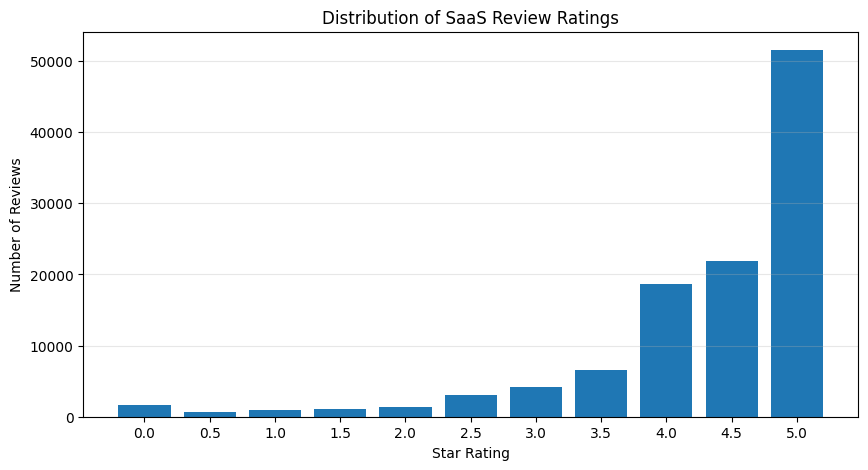

In [146]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    rating_distribution.index.astype(str),
    rating_distribution["Review Count"]
)

plt.title("Distribution of SaaS Review Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.grid(axis="y", alpha=0.3)

plt.show()

### 4.2.2 Rating Band Analysis

Grouping individual star ratings into low, mid-range, and high
rating categories to understand the overall rating distribution.

In [147]:
# Count reviews in each rating band
rating_bands = pd.Series({
    "Low (0–2 Stars)": df_clean["star_rating"].between(0, 2).sum(),
    "Mid-range (2.5–3.5 Stars)": df_clean["star_rating"].between(2.5, 3.5).sum(),
    "High (4–5 Stars)": df_clean["star_rating"].between(4, 5).sum()
})

# Calculate percentages
rating_band_analysis = pd.DataFrame({
    "Review Count": rating_bands,
    "Percentage": (rating_bands / len(df_clean)) * 100
})

# Display results
print(rating_band_analysis.round(2))

                           Review Count  Percentage
Low (0–2 Stars)                    5438        4.88
Mid-range (2.5–3.5 Stars)         13876       12.45
High (4–5 Stars)                  92127       82.67


### 4.3 Product Analysis

#### 4.3.1 Review Volume by Product

Analysing the number of reviews received by each SaaS product
to identify the most and least represented products.

In [148]:
# Count reviews for each product
product_review_counts = (
    df_clean.groupby("product_name_clean")
    .size()
    .sort_values(ascending=False)
)

# Calculate each product's percentage of total reviews
product_review_analysis = pd.DataFrame({
    "Review Count": product_review_counts,
    "Percentage": (
        product_review_counts / len(df_clean)
    ) * 100
})

# Display the 10 products with the most reviews
top_10_products = product_review_analysis.head(10)

print("Top 10 Products by Review Count:")
print(top_10_products.round(2))

Top 10 Products by Review Count:
                                                    Review Count  Percentage
product_name_clean                                                          
notion                                                      4326        3.88
smartsheet                                                  2816        2.53
slack                                                       2601        2.33
gusto                                                       2413        2.17
agentforce sales (formerly salesforce sales cloud)          2392        2.15
navan (formerly tripactions)                                2213        1.99
asana                                                       2147        1.93
rippling                                                    2075        1.86
nectar                                                      2030        1.82
sap concur                                                  2000        1.79


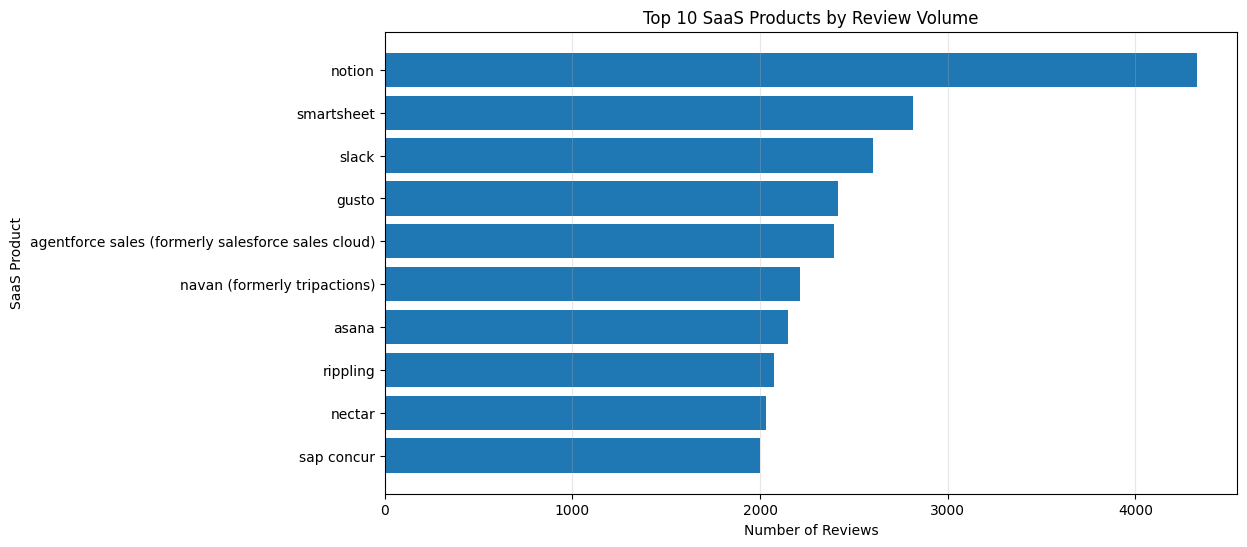

In [149]:
# Create a horizontal bar chart for the top 10 products
plt.figure(figsize=(11, 6))

plt.barh(
    top_10_products.index[::-1],
    top_10_products["Review Count"][::-1]
)

plt.title("Top 10 SaaS Products by Review Volume")
plt.xlabel("Number of Reviews")
plt.ylabel("SaaS Product")
plt.grid(axis="x", alpha=0.3)

plt.show()

#### 4.3.2 Average Rating by Product

Calculating the average and median star ratings for each SaaS
product while considering the number of reviews received.

In [150]:
# Calculate review volume and rating statistics for each product
product_rating_analysis = (
    df_clean.groupby("product_name_clean")
    .agg(
        Review_Count=("review_id", "size"),
        Average_Rating=("star_rating", "mean"),
        Median_Rating=("star_rating", "median")
    )
    .sort_values("Review_Count", ascending=False)
)

# Display the top 10 most-reviewed products
top_10_product_ratings = product_rating_analysis.head(10)

print("Top 10 Products: Review Volume and Ratings")

print(
    top_10_product_ratings.round(2).to_string()
)

Top 10 Products: Review Volume and Ratings
                                                    Review_Count  Average_Rating  Median_Rating
product_name_clean                                                                             
notion                                                      4326            4.30            4.5
smartsheet                                                  2816            3.54            3.5
slack                                                       2601            3.94            4.5
gusto                                                       2413            4.26            5.0
agentforce sales (formerly salesforce sales cloud)          2392            3.48            4.0
navan (formerly tripactions)                                2213            4.22            4.5
asana                                                       2147            3.76            4.0
rippling                                                    2075            4.44            5

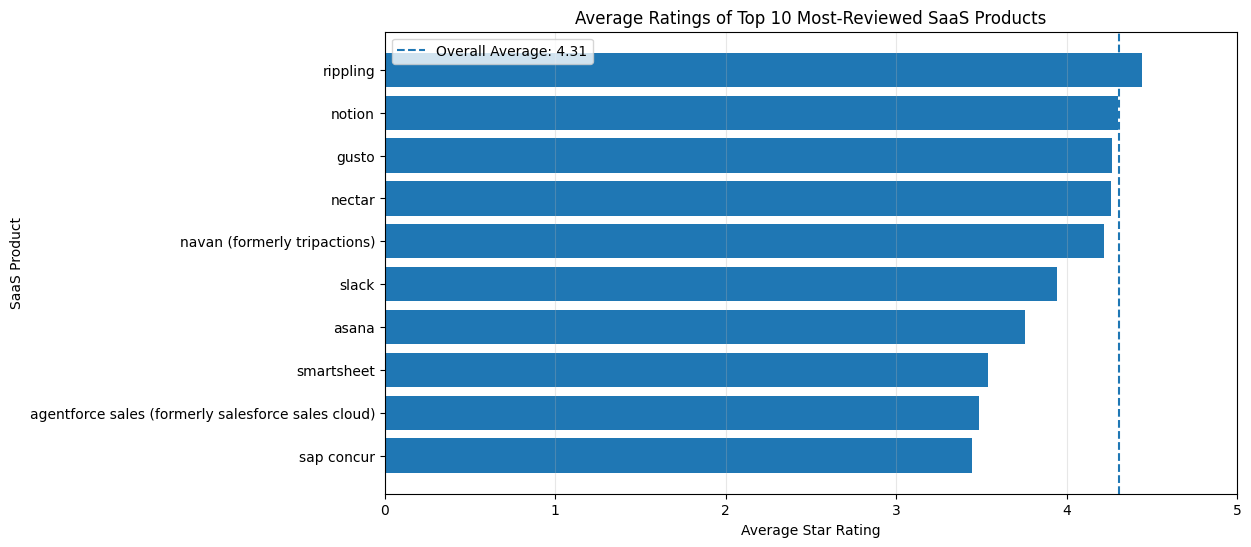

In [151]:
# Sort products by average rating
rating_chart_data = top_10_product_ratings.sort_values(
    "Average_Rating",
    ascending=True
)

# Create horizontal bar chart
plt.figure(figsize=(11, 6))

plt.barh(
    rating_chart_data.index,
    rating_chart_data["Average_Rating"]
)

# Add overall average rating reference line
overall_average = df_clean["star_rating"].mean()

plt.axvline(
    overall_average,
    linestyle="--",
    label=f"Overall Average: {overall_average:.2f}"
)

plt.title("Average Ratings of Top 10 Most-Reviewed SaaS Products")
plt.xlabel("Average Star Rating")
plt.ylabel("SaaS Product")

plt.xlim(0, 5)
plt.legend()
plt.grid(axis="x", alpha=0.3)

plt.show()

#### 4.3.3 Review Volume Distribution Across Products

Examining the number of reviews received by all 80 SaaS products
to understand differences in sample sizes before comparing ratings.

In [152]:
# Summary statistics for review counts across all products
print("Review Count Distribution Across All Products:")

print(
    product_rating_analysis["Review_Count"]
    .describe()
    .round(2)
)

# Identify the 10 products with the fewest reviews
least_reviewed_products = (
    product_rating_analysis
    .nsmallest(10, "Review_Count")
)

print("\n10 Products with the Fewest Reviews:")

print(
    least_reviewed_products[
        ["Review_Count", "Average_Rating"]
    ].round(2)
)

Review Count Distribution Across All Products:
count      80.00
mean     1393.01
std       559.49
min        39.00
25%      1053.00
50%      1254.00
75%      1553.25
max      4326.00
Name: Review_Count, dtype: float64

10 Products with the Fewest Reviews:
                         Review_Count  Average_Rating
product_name_clean                                   
fin                                39            2.88
monday ai work platform           283            4.55
fin by intercom                   996            4.54
yodeck                           1000            4.72
motive                           1001            4.23
attentive                        1002            4.42
zoho expense                     1002            4.55
square point of sale             1003            4.63
creately                         1005            4.39
foxit pdf editor                 1007            4.53


#### 4.3.4 Product Identity Validation — Fin

Checking whether "Fin" and "Fin by Intercom" represent
different product identifiers or naming variations.

In [153]:
# Inspect Fin-related products and their product slugs
fin_products = (
    df_clean.loc[
        df_clean["product_name_clean"].str.contains(
            r"\bfin\b",
            case=False,
            na=False,
            regex=True
        )
    ]
    .groupby(["product_name_clean", "product_slug"])
    .agg(
        Review_Count=("review_id", "size"),
        Average_Rating=("star_rating", "mean")
    )
    .sort_values("Review_Count", ascending=False)
)

print(fin_products.round(2).to_string())

                                    Review_Count  Average_Rating
product_name_clean product_slug                                 
fin by intercom    fin-by-intercom           996            4.54
fin                fin                        39            2.88


#### 4.3.5 Product Performance Comparison

Comparing the review volume and rating performance of all SaaS products.

Metrics:
- Total reviews
- Valid rating count
- Average rating
- Median rating
- Five-star rating percentage
- Low-rating percentage

In [154]:
# 1. Prepare valid-rating records (exclude zero-star ratings)
df_valid_ratings = df_clean[
    df_clean["star_rating"] >= 1
].copy()

# 2. Identify products using both slug and cleaned name
# This keeps distinct Monday products separate.
product_keys = ["product_slug", "product_name_clean"]

# 3. Calculate total reviews for each product
product_review_volume = (
    df_clean.groupby(product_keys)
    .size()
    .reset_index(name="Total_Reviews")
)

# 4. Calculate rating metrics using valid ratings only
product_rating_metrics = (
    df_valid_ratings.groupby(product_keys)
    .agg(
        Valid_Rating_Count=("star_rating", "count"),
        Average_Rating=("star_rating", "mean"),
        Median_Rating=("star_rating", "median"),
        Five_Star_Count=("star_rating", lambda x: (x == 5).sum()),
        Low_Rating_Count=("star_rating", lambda x: x.between(1, 2).sum())
    )
    .reset_index()
)

# 5. Combine review volume and rating metrics
product_performance = product_review_volume.merge(
    product_rating_metrics,
    on=product_keys,
    how="left"
)

# 6. Calculate rating percentages
product_performance["Five_Star_Percentage"] = (
    product_performance["Five_Star_Count"]
    / product_performance["Valid_Rating_Count"]
) * 100

product_performance["Low_Rating_Percentage"] = (
    product_performance["Low_Rating_Count"]
    / product_performance["Valid_Rating_Count"]
) * 100

# 7. Validate totals
print("PRODUCT PERFORMANCE VALIDATION")
print("Total Reviews:", product_performance["Total_Reviews"].sum())
print("Valid Rating Reviews:", product_performance["Valid_Rating_Count"].sum())
print("Total Products:", len(product_performance))
print("Overall Valid Average Rating:",
      round(df_valid_ratings["star_rating"].mean(), 2))

# 8. Display the 10 highest-rated products
print("\nTOP 10 HIGHEST-RATED PRODUCTS")

print(
    product_performance
    .dropna(subset=["Average_Rating"])
    .sort_values("Average_Rating", ascending=False)
    .head(10)[
        ["product_name_clean", "Total_Reviews", "Valid_Rating_Count",
         "Average_Rating", "Median_Rating",
         "Five_Star_Percentage", "Low_Rating_Percentage"]
    ]
    .round(2)
    .to_string(index=False)
)

# 9. Display the 10 lowest-rated products
print("\nTOP 10 LOWEST-RATED PRODUCTS")

print(
    product_performance
    .dropna(subset=["Average_Rating"])
    .sort_values("Average_Rating", ascending=True)
    .head(10)[
        ["product_name_clean", "Total_Reviews", "Valid_Rating_Count",
         "Average_Rating", "Median_Rating",
         "Five_Star_Percentage", "Low_Rating_Percentage"]
    ]
    .round(2)
    .to_string(index=False)
)

PRODUCT PERFORMANCE VALIDATION
Total Reviews: 111441
Valid Rating Reviews: 109220
Total Products: 80
Overall Valid Average Rating: 4.39

TOP 10 HIGHEST-RATED PRODUCTS
product_name_clean  Total_Reviews  Valid_Rating_Count  Average_Rating  Median_Rating  Five_Star_Percentage  Low_Rating_Percentage
           awardco           1072                1072            4.88            5.0                 83.21                   0.00
           action1           1092                1092            4.88            5.0                 82.78                   0.18
         everstage           1499                1497            4.82            5.0                 80.23                   0.07
             qobra           1046                1046            4.76            5.0                 71.32                   0.00
             close           1015                1012            4.76            5.0                 68.28                   0.10
          navattic           1010                1010

#### 4.3.6 Review Volume vs Average Rating

**Business question:** Do products receiving more reviews necessarily have higher average ratings?

The scatter plot uses all 80 product identifiers established in Section 4.3.5. The X-axis is total review volume (including every review); the Y-axis is the average of valid ratings using the existing project rule `star_rating >= 1`. The horizontal reference line is the overall valid average rating. Pearson and Spearman correlations are included to describe the direction and strength of association; neither establishes causation.


In [155]:
# Prepare the 80-product comparison using the validated table from Section 4.3.5.
product_volume_rating = product_performance[
    [
        "product_slug",
        "product_name_clean",
        "Total_Reviews",
        "Valid_Rating_Count",
        "Average_Rating"
    ]
].dropna(subset=["Average_Rating"]).copy()

overall_valid_average = df_valid_ratings["star_rating"].mean()
median_product_review_volume = product_volume_rating["Total_Reviews"].median()

# Measure the linear association using Pearson correlation.
pearson_correlation = product_volume_rating["Total_Reviews"].corr(
    product_volume_rating["Average_Rating"],
    method="pearson"
)

# Spearman correlation using ranked values
volume_ranks = product_volume_rating["Total_Reviews"].rank(method="average")
rating_ranks = product_volume_rating["Average_Rating"].rank(method="average")

spearman_correlation = volume_ranks.corr(
    rating_ranks,
    method="pearson"
)

print("PRODUCT REVIEW VOLUME vs AVERAGE VALID RATING")
print("Products included:", len(product_volume_rating))
print("Overall valid average rating:", round(overall_valid_average, 2))
print("Median product review volume:", round(median_product_review_volume, 2))
print("Pearson correlation:", round(pearson_correlation, 3))
print("Spearman correlation:", round(spearman_correlation, 3))

# Identify products that are useful to inspect in the scatter plot.
product_volume_rating["Volume_Group"] = np.where(
    product_volume_rating["Total_Reviews"] >= median_product_review_volume,
    "Higher-volume",
    "Lower-volume"
)
product_volume_rating["Rating_Group"] = np.where(
    product_volume_rating["Average_Rating"] >= overall_valid_average,
    "At/above overall average",
    "Below overall average"
)

standout_products = product_volume_rating[
    (
        (product_volume_rating["Volume_Group"] == "Higher-volume") &
        (product_volume_rating["Rating_Group"] == "Below overall average")
    ) |
    (
        (product_volume_rating["Volume_Group"] == "Lower-volume") &
        (product_volume_rating["Rating_Group"] == "At/above overall average")
    )
].sort_values("Total_Reviews", ascending=False)

print("\nProducts worth inspecting (relative to the median volume and overall valid average):")
print(
    standout_products[
        ["product_name_clean", "Total_Reviews", "Valid_Rating_Count", "Average_Rating",
         "Volume_Group", "Rating_Group"]
    ].round(2).head(20).to_string(index=False)
)


PRODUCT REVIEW VOLUME vs AVERAGE VALID RATING
Products included: 80
Overall valid average rating: 4.39
Median product review volume: 1254.0
Pearson correlation: -0.335
Spearman correlation: -0.385

Products worth inspecting (relative to the median volume and overall valid average):
                                product_name_clean  Total_Reviews  Valid_Rating_Count  Average_Rating  Volume_Group          Rating_Group
                                            notion           4326                4295            4.33 Higher-volume Below overall average
                                        smartsheet           2816                2746            3.62 Higher-volume Below overall average
                                             slack           2601                2531            4.04 Higher-volume Below overall average
agentforce sales (formerly salesforce sales cloud)           2392                2270            3.66 Higher-volume Below overall average
                      navan

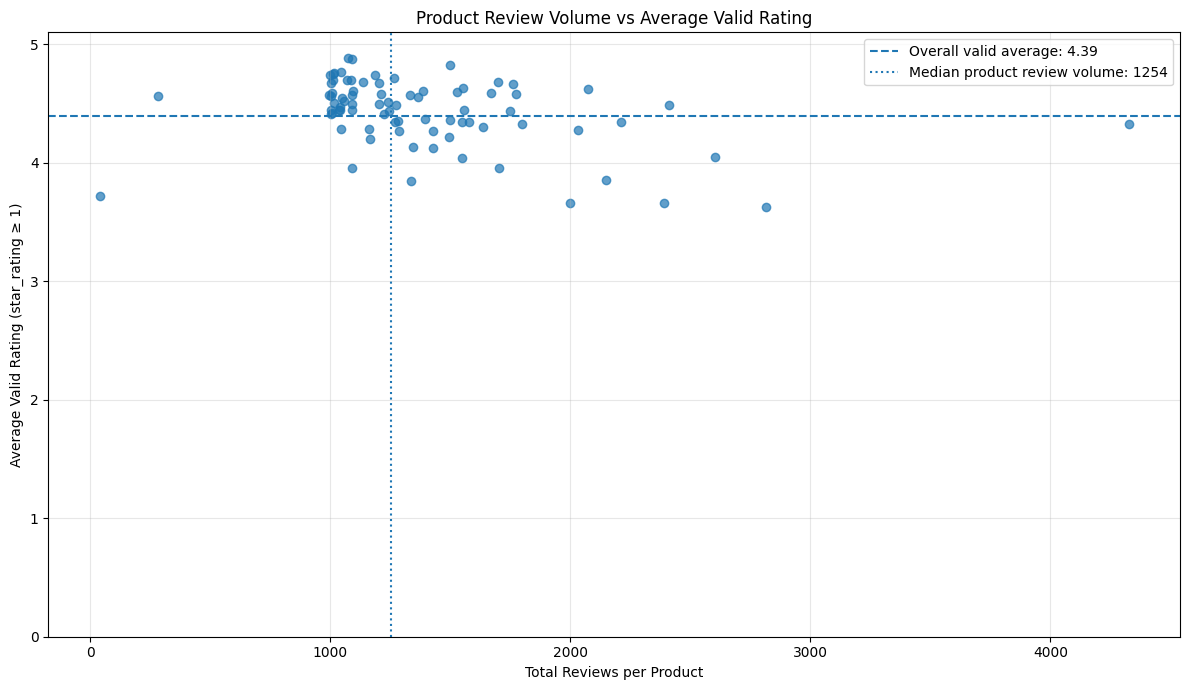

In [156]:
# Plot all products: volume on X, average valid rating on Y.
plt.figure(figsize=(12, 7))

plt.scatter(
    product_volume_rating["Total_Reviews"],
    product_volume_rating["Average_Rating"],
    alpha=0.7
)

plt.axhline(
    overall_valid_average,
    linestyle="--",
    label=f"Overall valid average: {overall_valid_average:.2f}"
)
plt.axvline(
    median_product_review_volume,
    linestyle=":",
    label=f"Median product review volume: {median_product_review_volume:.0f}"
)

plt.title("Product Review Volume vs Average Valid Rating")
plt.xlabel("Total Reviews per Product")
plt.ylabel("Average Valid Rating (star_rating ≥ 1)")
plt.ylim(0, 5.1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 4.4 Time-Based Analysis

**Business objective:** Understand how review activity and average valid ratings changed over time.

Review volume calculations use all reviews. Rating-trend calculations use the same valid-rating rule already established in Section 4.3.5 (`star_rating >= 1`). The dataset begins on August 30, 2012 and ends on September 3, 2026, so 2012 and 2026 are partial calendar years.


### 4.4.1 Review Volume by Year

Calculate annual review counts and each year's share of all reviews. The chart shows the observed counts; partial years must not be interpreted as complete-year totals.


In [157]:
# Count all reviews by calendar year and calculate their share of the dataset.
yearly_review_summary = (
    df_clean.assign(Review_Year=df_clean["review_date"].dt.year)
    .groupby("Review_Year")
    .agg(Review_Count=("review_id", "size"))
)

yearly_review_summary["Percentage_of_All_Reviews"] = (
    yearly_review_summary["Review_Count"] / len(df_clean) * 100
)
yearly_review_summary = yearly_review_summary.round(2)

print("YEARLY REVIEW VOLUME")
print(yearly_review_summary.to_string())
print("\nYear with the highest observed review volume:",
      int(yearly_review_summary["Review_Count"].idxmax()))


YEARLY REVIEW VOLUME
             Review_Count  Percentage_of_All_Reviews
Review_Year                                         
2012                   40                       0.04
2013                  101                       0.09
2014                  120                       0.11
2015                  330                       0.30
2016                  662                       0.59
2017                 1901                       1.71
2018                 2994                       2.69
2019                 5866                       5.26
2020                 2220                       1.99
2021                 3799                       3.41
2022                 6212                       5.57
2023                10951                       9.83
2024                12431                      11.15
2025                28170                      25.28
2026                35644                      31.98

Year with the highest observed review volume: 2026


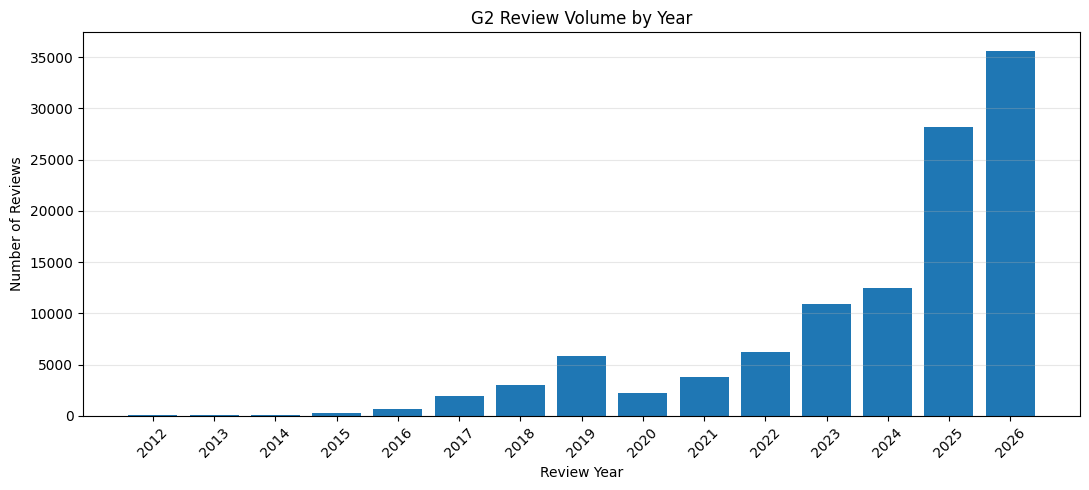

In [158]:
plt.figure(figsize=(11, 5))
plt.bar(
    yearly_review_summary.index.astype(str),
    yearly_review_summary["Review_Count"]
)
plt.title("G2 Review Volume by Year")
plt.xlabel("Review Year")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### 4.4.2 Monthly Review Trends

Aggregate all reviews by calendar month and plot the complete observed monthly series. The first and last months are partial periods because the dataset starts on August 30, 2012 and ends on September 3, 2026.


In [159]:
# Aggregate review volume by calendar month.
monthly_review_counts = (
    df_clean.assign(Review_Month=df_clean["review_date"].dt.to_period("M"))
    .groupby("Review_Month")
    .size()
    .rename("Review_Count")
    .to_frame()
)

print("Monthly review-count summary:")
print(monthly_review_counts["Review_Count"].describe().round(2).to_string())
print("\nHighest-volume month:", monthly_review_counts["Review_Count"].idxmax())
print("Lowest-volume month:", monthly_review_counts["Review_Count"].idxmin())


Monthly review-count summary:
count     170.00
mean      655.54
std      1148.23
min         2.00
25%        32.00
50%       224.50
75%       714.50
max      6999.00

Highest-volume month: 2026-03
Lowest-volume month: 2012-08


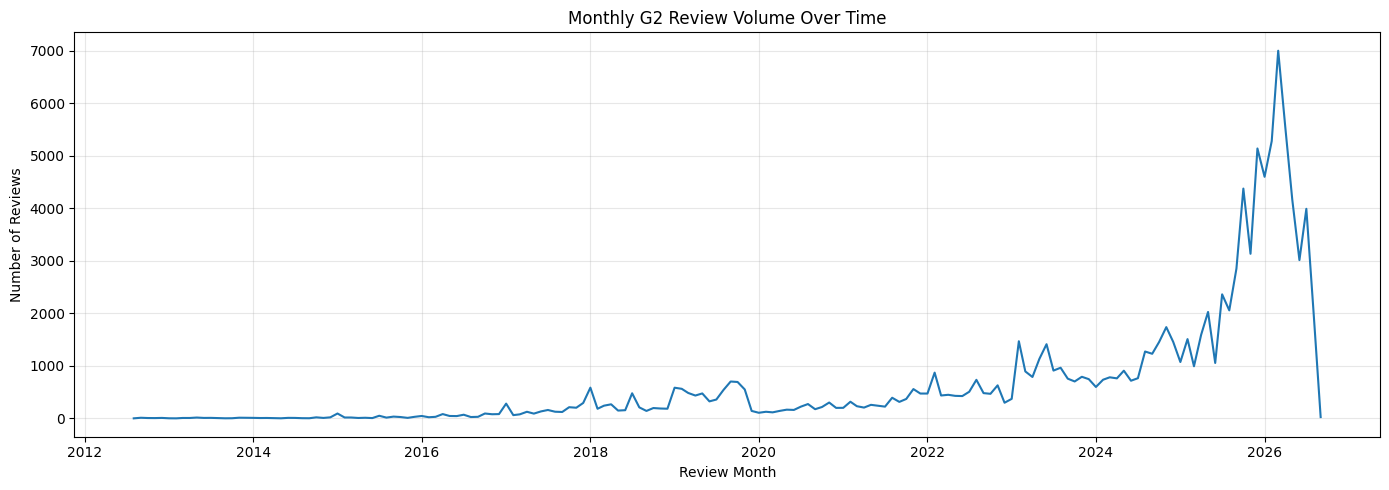

In [160]:
plt.figure(figsize=(14, 5))
plt.plot(
    monthly_review_counts.index.to_timestamp(),
    monthly_review_counts["Review_Count"]
)
plt.title("Monthly G2 Review Volume Over Time")
plt.xlabel("Review Month")
plt.ylabel("Number of Reviews")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 4.4.3 Average Rating Over Time

Calculate yearly and monthly average ratings using valid ratings only (`star_rating >= 1`). Include the number of valid ratings alongside each average so that periods with different sample sizes remain visible.


YEARLY AVERAGE VALID RATING
             Valid_Rating_Count  Average_Valid_Rating
Review_Year                                          
2012                         37                  3.59
2013                         95                  3.90
2014                        101                  3.90
2015                        298                  3.85
2016                        619                  3.83
2017                       1768                  3.40
2018                       2844                  3.86
2019                       5664                  3.90
2020                       2080                  4.13
2021                       3608                  4.13
2022                       5967                  4.34
2023                      10681                  4.42
2024                      12224                  4.49
2025                      27850                  4.49
2026                      35384                  4.51


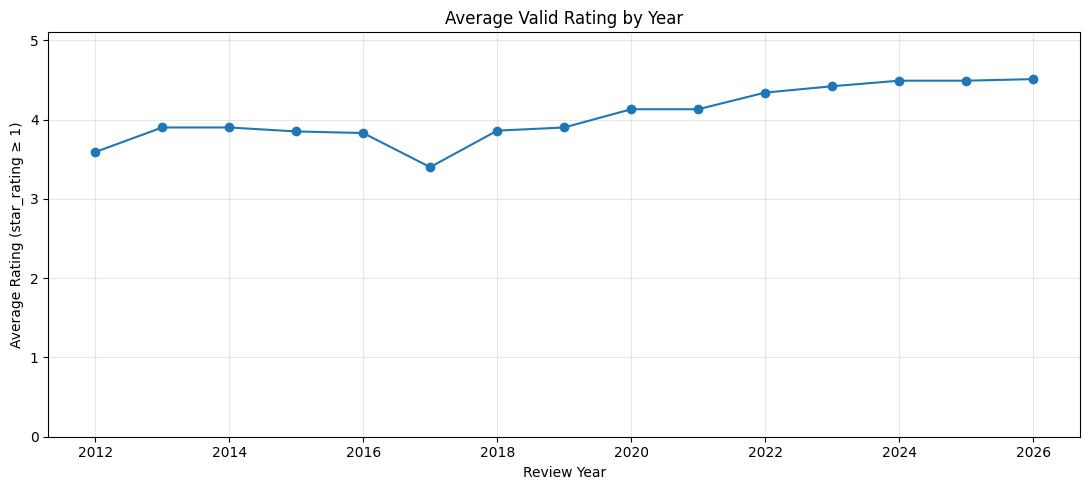

In [161]:
# Yearly average valid rating and the number of valid ratings behind each average.
yearly_rating_summary = (
    df_valid_ratings.assign(Review_Year=df_valid_ratings["review_date"].dt.year)
    .groupby("Review_Year")
    .agg(
        Valid_Rating_Count=("star_rating", "count"),
        Average_Valid_Rating=("star_rating", "mean")
    )
)

yearly_rating_summary["Average_Valid_Rating"] = (
    yearly_rating_summary["Average_Valid_Rating"].round(2)
)

print("YEARLY AVERAGE VALID RATING")
print(yearly_rating_summary.to_string())

plt.figure(figsize=(11, 5))
plt.plot(
    yearly_rating_summary.index,
    yearly_rating_summary["Average_Valid_Rating"],
    marker="o"
)
plt.title("Average Valid Rating by Year")
plt.xlabel("Review Year")
plt.ylabel("Average Rating (star_rating ≥ 1)")
plt.ylim(0, 5.1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Monthly average valid rating summary:
count    170.00
mean       4.05
std        0.41
min        2.83
25%        3.80
50%        4.10
75%        4.41
max        5.00


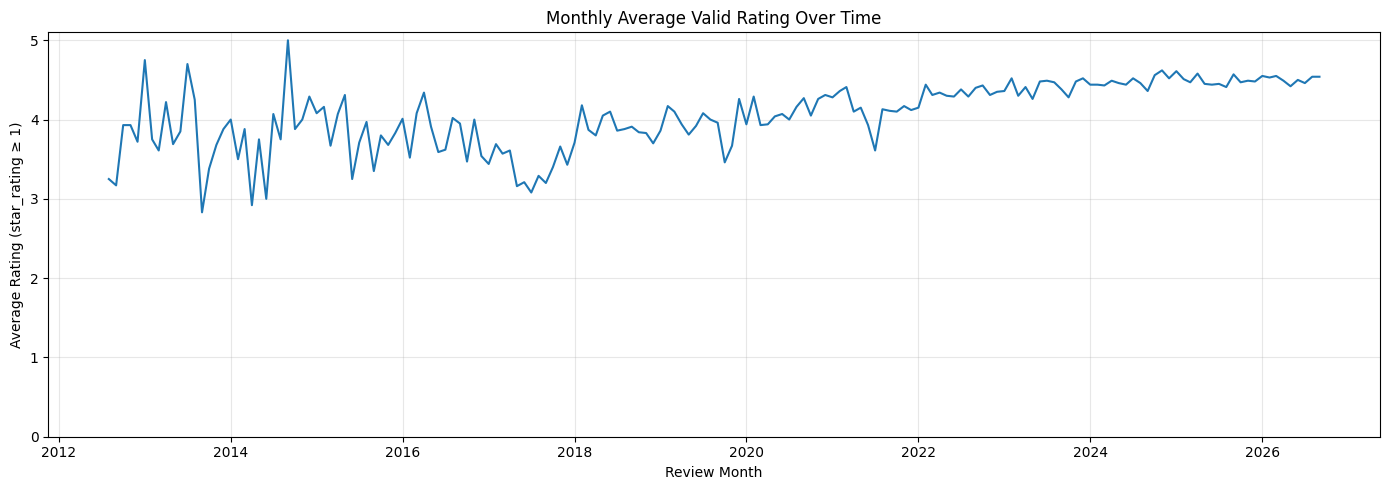

In [162]:
# Monthly average valid rating and valid-rating count.
monthly_rating_summary = (
    df_valid_ratings.assign(Review_Month=df_valid_ratings["review_date"].dt.to_period("M"))
    .groupby("Review_Month")
    .agg(
        Valid_Rating_Count=("star_rating", "count"),
        Average_Valid_Rating=("star_rating", "mean")
    )
)

monthly_rating_summary["Average_Valid_Rating"] = (
    monthly_rating_summary["Average_Valid_Rating"].round(2)
)

print("Monthly average valid rating summary:")
print(monthly_rating_summary["Average_Valid_Rating"].describe().round(2).to_string())

plt.figure(figsize=(14, 5))
plt.plot(
    monthly_rating_summary.index.to_timestamp(),
    monthly_rating_summary["Average_Valid_Rating"]
)
plt.title("Monthly Average Valid Rating Over Time")
plt.xlabel("Review Month")
plt.ylabel("Average Rating (star_rating ≥ 1)")
plt.ylim(0, 5.1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 4.5 Reviewer Analysis

**Business objective:** Describe the reviewer attributes available in the dataset. This section reports the observed company-size, industry, title, and verification fields; it does not infer individual identities.


### 4.5.1 Company Size Distribution

The actual source categories were inspected earlier in the notebook (cell 84). They match the three business segments in the project blueprint. Missing company-size values are retained as **Unknown** rather than excluded.


In [163]:
# Map the observed source labels to the project's three business segments.
company_size_mapping = {
    "Small-Business (50 or fewer emp.)": "Small business",
    "Mid-Market (51-1000 emp.)": "Mid-market",
    "Enterprise (> 1000 emp.)": "Enterprise"
}

observed_company_sizes = set(
    df_clean["reviewer_company_size"].dropna().unique()
)
unmapped_company_sizes = sorted(observed_company_sizes - set(company_size_mapping))

company_size_segment = df_clean["reviewer_company_size"].map(company_size_mapping)
company_size_segment = company_size_segment.mask(
    df_clean["reviewer_company_size"].notna() & company_size_segment.isna(),
    "Unmapped / check"
).fillna("Unknown")

company_size_order = [
    "Small business",
    "Mid-market",
    "Enterprise",
    "Unknown",
    "Unmapped / check"
]
company_size_counts = company_size_segment.value_counts().reindex(
    company_size_order,
    fill_value=0
)

company_size_analysis = pd.DataFrame({
    "Review_Count": company_size_counts,
    "Percentage_of_All_Reviews": company_size_counts / len(df_clean) * 100
}).round(2)

print("COMPANY SIZE DISTRIBUTION")
print(company_size_analysis.to_string())
print("\nUnmapped non-missing source values:", unmapped_company_sizes)
print("Missing company-size records:", int(df_clean["reviewer_company_size"].isna().sum()))


COMPANY SIZE DISTRIBUTION
                       Review_Count  Percentage_of_All_Reviews
reviewer_company_size                                         
Small business                46535                      41.76
Mid-market                    39816                      35.73
Enterprise                    17902                      16.06
Unknown                        7188                       6.45
Unmapped / check                  0                       0.00

Unmapped non-missing source values: []
Missing company-size records: 7188


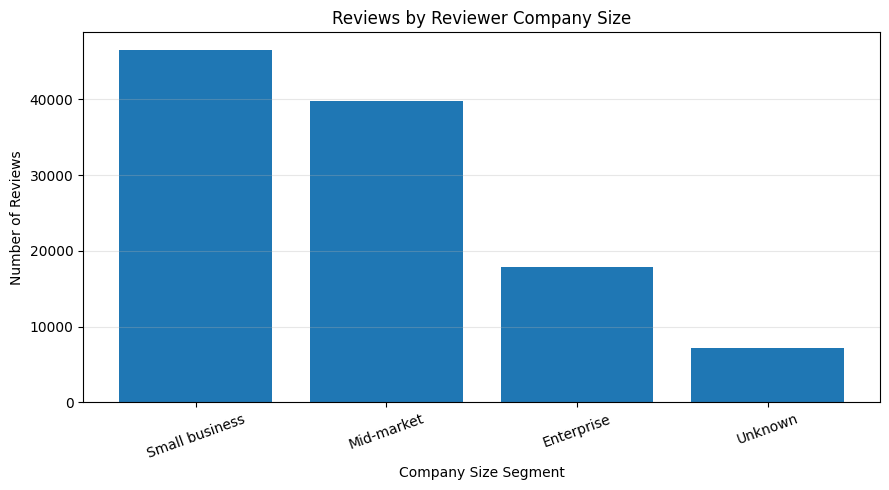

In [164]:
company_size_plot = company_size_analysis[company_size_analysis["Review_Count"] > 0]

plt.figure(figsize=(9, 5))
plt.bar(
    company_size_plot.index,
    company_size_plot["Review_Count"]
)
plt.title("Reviews by Reviewer Company Size")
plt.xlabel("Company Size Segment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### 4.5.2 Reviewer Industry Distribution

The industry field has substantial missingness (93.29% in the earlier data-quality audit). Report its completeness and show the most frequently observed categories only. Percentages among non-missing industry values are shown separately from percentages of the full dataset; do not generalise the observed subset to all reviewers.


In [165]:
industry_series = df_clean["reviewer_industry"]
industry_available = industry_series.dropna()
industry_missing_count = int(industry_series.isna().sum())
industry_available_count = int(industry_series.notna().sum())

industry_completeness = pd.DataFrame({
    "Metric": ["Total reviews", "Industry available", "Industry missing"],
    "Count": [len(df_clean), industry_available_count, industry_missing_count],
    "Percentage_of_All_Reviews": [
        100.0,
        industry_available_count / len(df_clean) * 100,
        industry_missing_count / len(df_clean) * 100
    ]
})

industry_counts = industry_available.value_counts()
industry_distribution = pd.DataFrame({
    "Review_Count": industry_counts,
    "Percentage_of_NonMissing_Industry": industry_counts / industry_available_count * 100,
    "Percentage_of_All_Reviews": industry_counts / len(df_clean) * 100
}).round(2)

print("INDUSTRY FIELD COMPLETENESS")
print(industry_completeness.round(2).to_string(index=False))
print("\nTOP 15 OBSERVED INDUSTRIES")
print(industry_distribution.head(15).to_string())
print("\nNumber of observed industry categories:", industry_available.nunique())


INDUSTRY FIELD COMPLETENESS
            Metric  Count  Percentage_of_All_Reviews
     Total reviews 111441                     100.00
Industry available   7477                       6.71
  Industry missing 103964                      93.29

TOP 15 OBSERVED INDUSTRIES
                                     Review_Count  Percentage_of_NonMissing_Industry  Percentage_of_All_Reviews
reviewer_industry                                                                                              
Information Technology and Services          1505                              20.13                       1.35
Computer Software                             883                              11.81                       0.79
Marketing and Advertising                     611                               8.17                       0.55
Internet                                      255                               3.41                       0.23
Financial Services                            233           

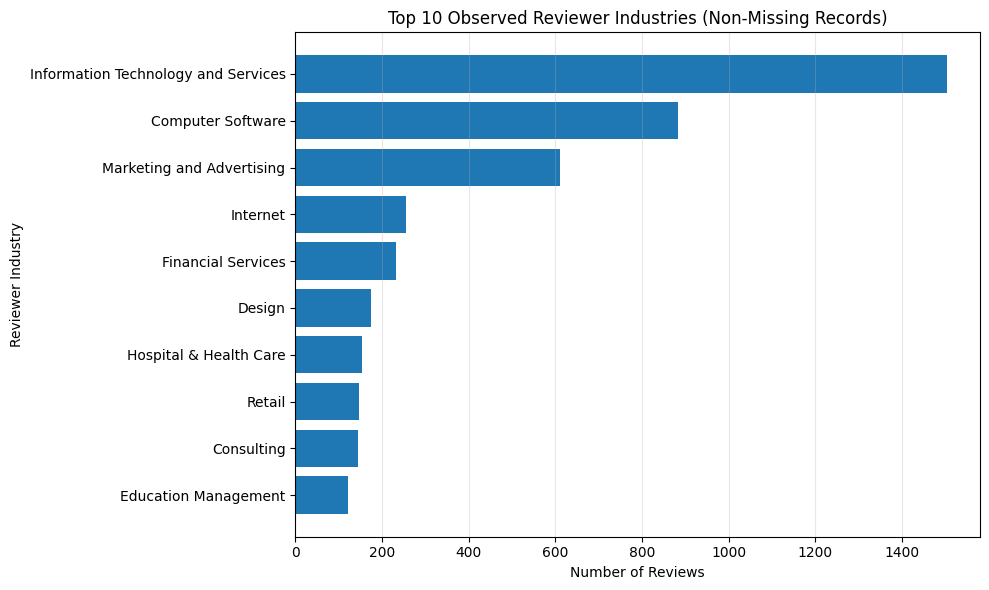

In [166]:
# Show the ten most common observed industries. This chart represents only
# the non-missing subset, not the full reviewer population.
top_industries = industry_distribution.head(10).sort_values("Review_Count")

plt.figure(figsize=(10, 6))
plt.barh(top_industries.index.astype(str), top_industries["Review_Count"])
plt.title("Top 10 Observed Reviewer Industries (Non-Missing Records)")
plt.xlabel("Number of Reviews")
plt.ylabel("Reviewer Industry")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


### 4.5.3 Reviewer Profile and Verification

Summarise reviewer-title availability, verification status, avatar availability, and validation method. `reviewer_title` is high-cardinality free text, so show only its most common exact values and do not treat it as a standardised job-title taxonomy. Reviewer names are not used because the dataset redacts almost every name; `validated_reviewer` is not analysed because the earlier audit found it constant and it was removed from `df_clean`.


In [167]:
# Availability of reviewer-title information.
reviewer_title_availability = pd.DataFrame({
    "Status": ["Available", "Missing"],
    "Review_Count": [
        int(df_clean["reviewer_title"].notna().sum()),
        int(df_clean["reviewer_title"].isna().sum())
    ]
})
reviewer_title_availability["Percentage"] = (
    reviewer_title_availability["Review_Count"] / len(df_clean) * 100
)

# Distributions for reviewer-verification attributes.
verified_user_distribution = df_clean["verified_current_user"].map(
    {1: "Verified current user", 0: "Not marked as verified"}
).value_counts(dropna=False)

avatar_distribution = df_clean["reviewer_has_avatar"].map(
    {1: "Avatar present", 0: "No avatar"}
).value_counts(dropna=False)

validation_method_distribution = (
    df_clean["validated_method"]
    .fillna("Missing")
    .value_counts(dropna=False)
)

print("REVIEWER TITLE AVAILABILITY")
print(reviewer_title_availability.round(2).to_string(index=False))
print("\nVERIFIED CURRENT USER")
print(verified_user_distribution.to_string())
print("\nREVIEWER AVATAR")
print(avatar_distribution.to_string())
print("\nVALIDATION METHOD (INCLUDING MISSING)")
print(validation_method_distribution.to_string())

print("\nTOP 10 EXACT REVIEWER TITLE VALUES")
print(df_clean["reviewer_title"].value_counts().head(10).to_string())


REVIEWER TITLE AVAILABILITY
   Status  Review_Count  Percentage
Available         56478       50.68
  Missing         54963       49.32

VERIFIED CURRENT USER
verified_current_user
Verified current user     67636
Not marked as verified    43805

REVIEWER AVATAR
reviewer_has_avatar
No avatar         60092
Avatar present    51349

VALIDATION METHOD (INCLUDING MISSING)
validated_method
Missing           95319
Business Email     9594
LinkedIn           6528

TOP 10 EXACT REVIEWER TITLE VALUES
reviewer_title
CEO                  857
Owner                721
Founder              694
Account Executive    586
Software Engineer    509
Project Manager      413
Account Manager      352
Director             335
Marketing Manager    327
Manager              286


## 4.6 Review Content Analysis

**Business objective:** Describe the written review content before feature extraction and pain-point classification in Phase 5. `review_text` is the primary text field; `markdown_content` is not substituted because it can duplicate content already available elsewhere.


### 4.6.1 Review Text Length

Calculate character and whitespace-delimited word counts for non-missing `review_text` values. The histogram's horizontal range is limited to the 99th percentile to make the main distribution readable; the summary table retains the full minimum and maximum.


In [168]:
# Create analysis-only length series; df_clean itself is not modified.
review_text_char_count = df_clean["review_text"].str.len()
review_text_word_count = df_clean["review_text"].str.split().str.len()

review_text_length_summary = pd.DataFrame({
    "Character_Count": review_text_char_count,
    "Word_Count": review_text_word_count
}).agg(["count", "mean", "median", "min", "max"]).round(2)

print("REVIEW TEXT LENGTH SUMMARY")
print(review_text_length_summary.to_string())
print("\nMissing review_text values:", int(df_clean["review_text"].isna().sum()))


REVIEW TEXT LENGTH SUMMARY
        Character_Count  Word_Count
count         111159.00   111159.00
mean             435.58       75.21
median           325.00       57.00
min               11.00        3.00
max            13398.00     2304.00

Missing review_text values: 282


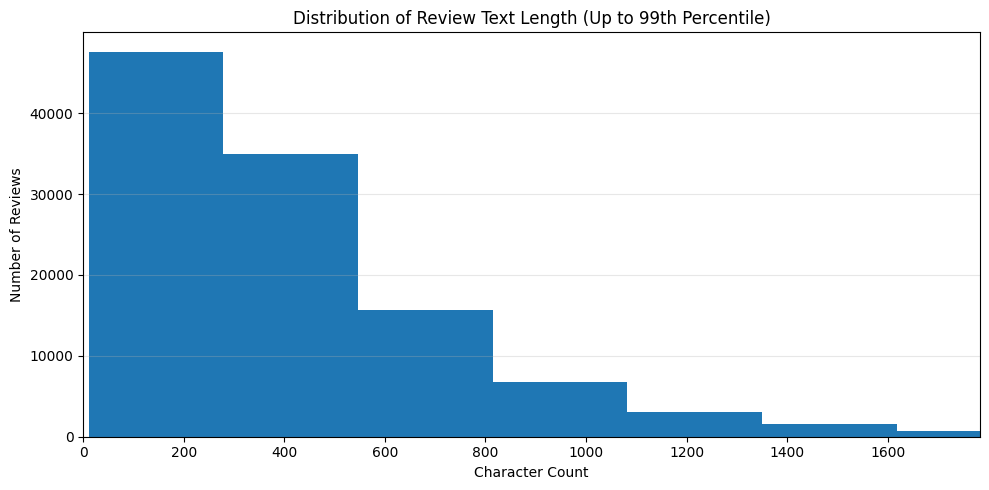

In [169]:
review_text_char_values = review_text_char_count.dropna()
review_text_chart_limit = review_text_char_values.quantile(0.99)

plt.figure(figsize=(10, 5))
plt.hist(review_text_char_values, bins=50)
plt.xlim(0, review_text_chart_limit)
plt.title("Distribution of Review Text Length (Up to 99th Percentile)")
plt.xlabel("Character Count")
plt.ylabel("Number of Reviews")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### 4.6.2 Review Title Analysis

Measure title availability and the character/word length of available titles. The title histogram is limited to the 99th percentile for readability, while the summary preserves the full range.


In [170]:
title_char_count = df_clean["title"].str.len()
title_word_count = df_clean["title"].str.split().str.len()

title_length_summary = pd.DataFrame({
    "Character_Count": title_char_count,
    "Word_Count": title_word_count
}).agg(["count", "mean", "median", "min", "max"]).round(2)

print("REVIEW TITLE AVAILABILITY")
print("Available titles:", int(df_clean["title"].notna().sum()))
print("Missing titles:", int(df_clean["title"].isna().sum()))
print("\nTITLE LENGTH SUMMARY")
print(title_length_summary.to_string())


REVIEW TITLE AVAILABILITY
Available titles: 111174
Missing titles: 267

TITLE LENGTH SUMMARY
        Character_Count  Word_Count
count         111174.00   111174.00
mean              42.08        6.38
median            42.00        6.00
min                1.00        1.00
max              504.00       79.00


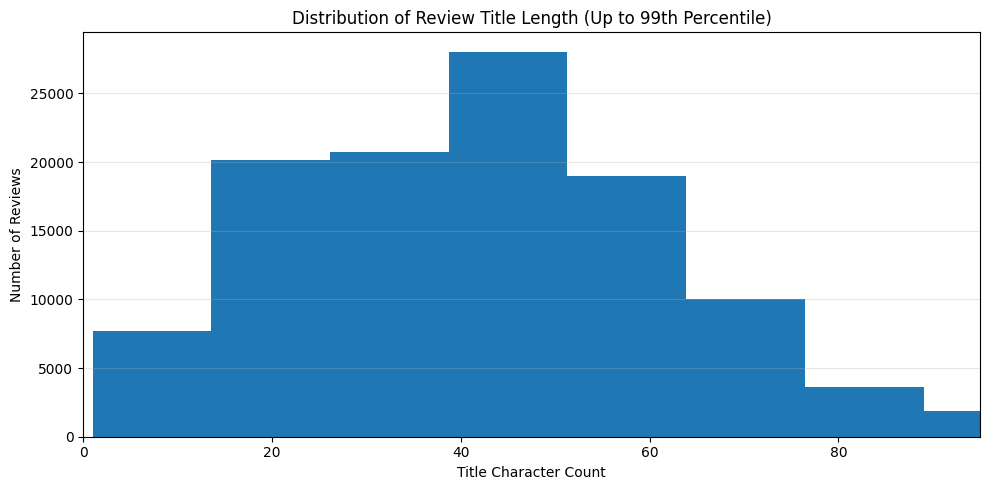

In [171]:
title_char_values = title_char_count.dropna()
title_chart_limit = title_char_values.quantile(0.99)

plt.figure(figsize=(10, 5))
plt.hist(title_char_values, bins=40)
plt.xlim(0, title_chart_limit)
plt.title("Distribution of Review Title Length (Up to 99th Percentile)")
plt.xlabel("Title Character Count")
plt.ylabel("Number of Reviews")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### 4.6.3 Short and Long Reviews

This question was already investigated in Phase 3 (cells 165–167): one pipe-only, one-character review was identified and replaced with missing text in `df_clean`; 23 reviews longer than 5,000 characters were inspected and appeared legitimate. The following check confirms the counts after cleaning. Long reviews are retained; no length-based deletion is applied.


In [172]:
# Compare the previously identified short-text issue before and after cleaning.
raw_short_review_count = int(df["review_text"].str.len().between(1, 10).sum())
clean_short_review_count = int(review_text_char_count.between(1, 10).sum())
long_review_count = int((review_text_char_count > 5000).sum())

review_length_flags = pd.DataFrame({
    "Check": [
        "Raw reviews with 1–10 characters",
        "Cleaned reviews with 1–10 characters",
        "Cleaned reviews longer than 5,000 characters"
    ],
    "Review_Count": [
        raw_short_review_count,
        clean_short_review_count,
        long_review_count
    ]
})

print(review_length_flags.to_string(index=False))
print("\nDecision: retain long reviews; the pipe-only review text remains missing in df_clean.")


                                       Check  Review_Count
            Raw reviews with 1–10 characters             1
        Cleaned reviews with 1–10 characters             0
Cleaned reviews longer than 5,000 characters            23

Decision: retain long reviews; the pipe-only review text remains missing in df_clean.


### 4.6.4 Review Content Patterns

Inspect basic word-frequency patterns in `review_text` only. Common English stop words and tokens shorter than three letters are excluded to make the table more informative. This is a preliminary vocabulary check, not feature extraction, sentiment classification, or complaint categorisation.


In [173]:
import re
from collections import Counter

basic_stop_words = {
    "the", "and", "for", "are", "but", "not", "with", "you", "your",
    "this", "that", "was", "were", "have", "has", "had", "from", "they",
    "their", "them", "there", "then", "than", "when", "what", "which",
    "who", "how", "can", "could", "would", "should", "will", "just",
    "into", "about", "also", "very", "more", "most", "some", "all", "any",
    "our", "out", "use", "used", "using", "one", "get", "got", "its",
    "it's", "its", "been", "being", "via", "per", "such", "each", "both",
    "tool", "tools", "product", "software", "work", "working"
}

review_tokens = []
for review in df_clean["review_text"].dropna():
    tokens = re.findall(r"[a-zA-Z]{3,}", review.casefold())
    review_tokens.extend(
        token for token in tokens if token not in basic_stop_words
    )

common_review_words = pd.DataFrame(
    Counter(review_tokens).most_common(20),
    columns=["Word", "Frequency"]
)

print("TOP 20 WORDS IN REVIEW TEXT (BASIC STOP WORDS EXCLUDED)")
print(common_review_words.to_string(index=False))


TOP 20 WORDS IN REVIEW TEXT (BASIC STOP WORDS EXCLUDED)
      Word  Frequency
      easy      61245
      like      53931
      time      37292
      team      23537
  features      21810
      user      20380
    really      20033
     great      19927
  platform      18502
      need      17754
     makes      17669
   support      17630
      find      17212
     other      16930
     helps      16498
everything      15344
 sometimes      15058
       don      14875
      able      14217
      make      14033


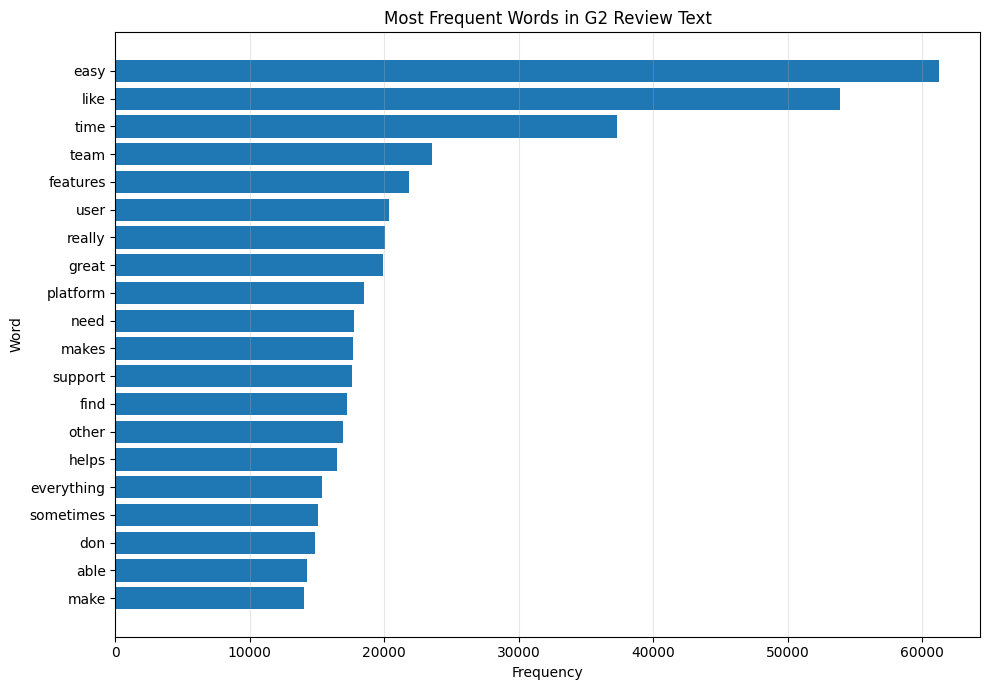

In [174]:
word_chart_data = common_review_words.sort_values("Frequency", ascending=True)

plt.figure(figsize=(10, 7))
plt.barh(word_chart_data["Word"], word_chart_data["Frequency"])
plt.title("Most Frequent Words in G2 Review Text")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


## 4.7 Review Metadata & Structured Feedback Analysis

**Business objective:** Describe structured-feedback coverage, review-source categories, and incentive status. The fields `likes`, `dislikes`, and `problems_solved` were already inspected in earlier cells (79–81 and 156) and contain descriptive text, not numeric like/dislike counts. They must not be converted into engagement counts.


### 4.7.1 Structured Feedback Availability

Measure the number and percentage of reviews with and without `has_structured_split`, then report the availability of each structured text field. Missing feedback is not interpreted as a zero value.


In [175]:
structured_flag_labels = df_clean["has_structured_split"].map({
    1: "With structured feedback",
    0: "Without structured feedback"
}).fillna("Unexpected / missing flag")

structured_flag_counts = structured_flag_labels.value_counts()
structured_feedback_summary = pd.DataFrame({
    "Review_Count": structured_flag_counts,
    "Percentage_of_All_Reviews": structured_flag_counts / len(df_clean) * 100
}).round(2)

feedback_fields = ["likes", "dislikes", "problems_solved"]
feedback_field_availability = pd.DataFrame({
    "Available_Count": df_clean[feedback_fields].notna().sum(),
    "Missing_Count": df_clean[feedback_fields].isna().sum(),
    "Available_Percentage": df_clean[feedback_fields].notna().mean() * 100
}).round(2)

print("STRUCTURED FEEDBACK FLAG")
print(structured_feedback_summary.to_string())
print("\nSTRUCTURED TEXT FIELD AVAILABILITY")
print(feedback_field_availability.to_string())


STRUCTURED FEEDBACK FLAG
                             Review_Count  Percentage_of_All_Reviews
has_structured_split                                                
Without structured feedback         76304                      68.47
With structured feedback            35137                      31.53

STRUCTURED TEXT FIELD AVAILABILITY
                 Available_Count  Missing_Count  Available_Percentage
likes                      35133          76308                 31.53
dislikes                   35079          76362                 31.48
problems_solved            34942          76499                 31.35


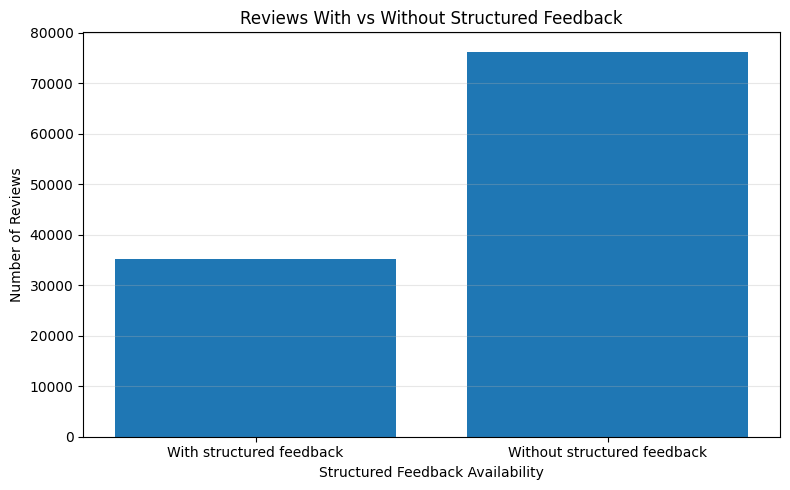

In [176]:
structured_chart = structured_feedback_summary.reindex([
    "With structured feedback",
    "Without structured feedback"
]).dropna(subset=["Review_Count"])

plt.figure(figsize=(8, 5))
plt.bar(structured_chart.index, structured_chart["Review_Count"])
plt.title("Reviews With vs Without Structured Feedback")
plt.xlabel("Structured Feedback Availability")
plt.ylabel("Number of Reviews")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### 4.7.2 Review Source Distribution

Calculate review counts and percentages for every observed `review_source` category. Use the nine categories found in the actual CSV rather than assuming a fixed category list.


In [177]:
review_source_counts = df_clean["review_source"].value_counts(dropna=False)
review_source_analysis = pd.DataFrame({
    "Review_Count": review_source_counts,
    "Percentage_of_All_Reviews": review_source_counts / len(df_clean) * 100
}).round(2)

print("REVIEW SOURCE DISTRIBUTION")
print(review_source_analysis.to_string())
print("\nObserved review-source categories:", df_clean["review_source"].nunique())


REVIEW SOURCE DISTRIBUTION
                                  Review_Count  Percentage_of_All_Reviews
review_source                                                            
Organic                                  98222                      88.14
G2 invite                                 4859                       4.36
Seller invite                             4550                       4.08
G2 invite on behalf of seller             2222                       1.99
In-app                                     926                       0.83
Organic Review from User Profile           387                       0.35
Thank You page                             162                       0.15
G2 Gives Campaign                          105                       0.09
Organic Review from Pop Up                   8                       0.01

Observed review-source categories: 9


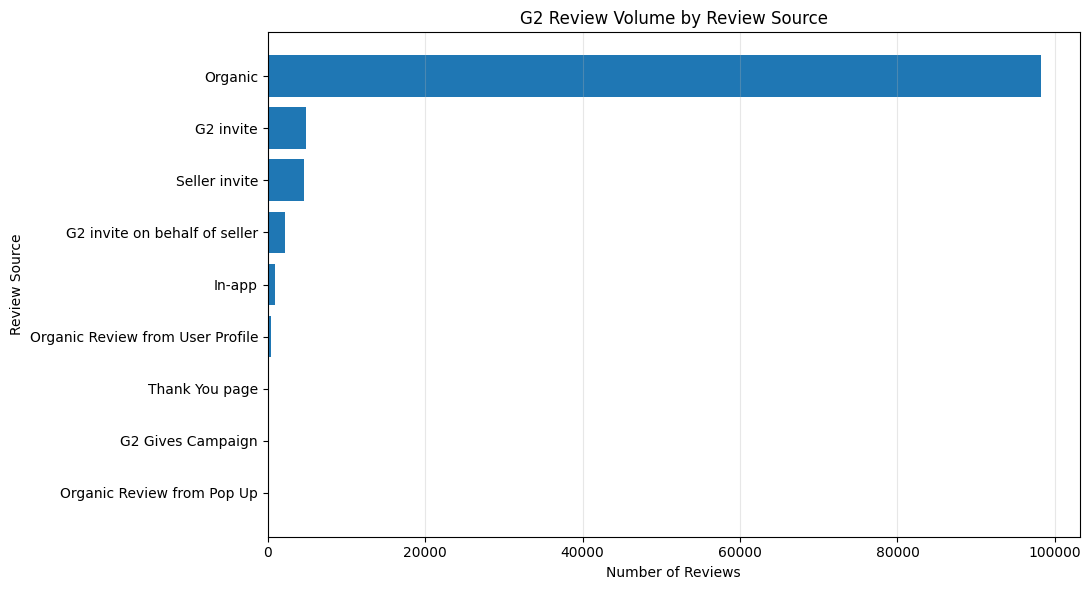

In [178]:
review_source_plot = review_source_analysis.sort_values("Review_Count")

plt.figure(figsize=(11, 6))
plt.barh(review_source_plot.index.astype(str), review_source_plot["Review_Count"])
plt.title("G2 Review Volume by Review Source")
plt.xlabel("Number of Reviews")
plt.ylabel("Review Source")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


### 4.7.3 Incentivized vs Non-Incentivized Reviews

Calculate counts and percentages for the two observed values in `incentivized`, then compare them in a bar chart.


In [179]:
incentive_labels = df_clean["incentivized"].map({
    0: "Non-incentivized",
    1: "Incentivized"
}).fillna("Unexpected / missing value")

incentive_counts = incentive_labels.value_counts()
incentive_analysis = pd.DataFrame({
    "Review_Count": incentive_counts,
    "Percentage_of_All_Reviews": incentive_counts / len(df_clean) * 100
}).round(2)

print("INCENTIVIZED vs NON-INCENTIVIZED REVIEWS")
print(incentive_analysis.to_string())


INCENTIVIZED vs NON-INCENTIVIZED REVIEWS
                  Review_Count  Percentage_of_All_Reviews
incentivized                                             
Incentivized             70887                      63.61
Non-incentivized         40554                      36.39


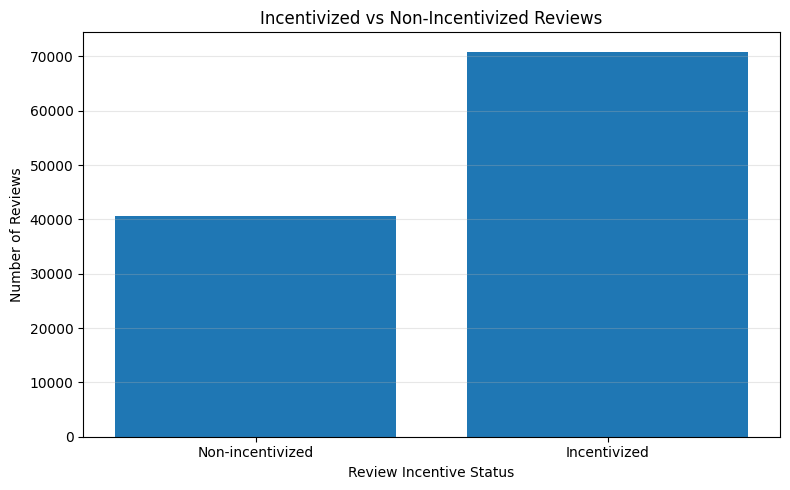

In [180]:
incentive_plot = incentive_analysis.reindex([
    "Non-incentivized",
    "Incentivized"
]).dropna(subset=["Review_Count"])

plt.figure(figsize=(8, 5))
plt.bar(incentive_plot.index, incentive_plot["Review_Count"])
plt.title("Incentivized vs Non-Incentivized Reviews")
plt.xlabel("Review Incentive Status")
plt.ylabel("Number of Reviews")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### EDA implementation status

Sections 4.1–4.7 contain the completed exploratory analysis. The final notebook has been re-executed from the top after rebuilding `df_clean` from `df_raw`. The CSV loader resolves the project-relative `../data/raw/g2_reviews.csv` path, the project-root `data/raw/g2_reviews.csv` path, or a CSV beside the notebook. Phase 4–7 analyses follow in the next sections.

# PYTHON ANALYSIS — REMAINING PROJECT PHASES

This section contains the **actual Python implementation cells** for the remaining analytical phases in the G2 project. It continues after the completed EDA (Sections 4.1–4.7). Run these cells from top to bottom. The existing `df`, `df_clean`, EDA outputs, and earlier cells are preserved.

**Scope in this notebook:** Python analysis only — Product Performance & Customer Satisfaction, Text Analysis & Feature Extraction, Company Segmentation & Review Bias Analysis, and evidence-based Business Insights. The raw dataset is not modified.

# PHASE 4 — PRODUCT PERFORMANCE & CUSTOMER SATISFACTION

**Business objective:** Compare products using valid 1–5 star ratings, identify how review counts affect the reliability of comparisons, examine rating distributions, and compare ratings over time and across company sizes.

The rating-analysis rule is applied consistently: include ratings from 1.0 through 5.0. Zero-star and 0.5-star records remain in `df_clean` but are excluded from rating metrics. Within the valid range, **low ratings mean every value from 1.0 through 2.0 inclusive**, including 1.5-star reviews.

## 4.1 Prepare the valid-rating analysis dataset

Create analysis-only helper columns. Do not modify `df_clean`.

In [181]:
# Keep only ratings on the documented 1–5 scale for rating-based analysis.
df_valid_ratings = df_clean.loc[
    df_clean["star_rating"].between(1, 5)
].copy()

# Stable product identity: use the slug and retain the cleaned display name.
product_keys = ["product_slug", "product_name_clean"]

# Create a clean company-size segment label for later comparisons.
company_size_mapping = {
    "Small-Business (50 or fewer emp.)": "Small business",
    "Mid-Market (51-1000 emp.)": "Mid-market",
    "Enterprise (> 1000 emp.)": "Enterprise"
}

for frame in (df_clean, df_valid_ratings):
    frame["Company_Size_Segment"] = (
        frame["reviewer_company_size"].map(company_size_mapping).fillna("Unknown")
    )

print("Total review records:", len(df_clean))
print("Valid 1–5 star ratings:", len(df_valid_ratings))
print("Excluded from rating calculations:", len(df_clean) - len(df_valid_ratings))
print("Products (slug + cleaned name combinations):", df_clean[product_keys].drop_duplicates().shape[0])
print("Overall valid average rating:", round(df_valid_ratings["star_rating"].mean(), 2))

Total review records: 111441
Valid 1–5 star ratings: 109220
Excluded from rating calculations: 2221
Products (slug + cleaned name combinations): 80
Overall valid average rating: 4.39


## 4.2 Establish and test a minimum review-count threshold

A product with very few valid ratings can have a more volatile average. Use **100 valid ratings** as the primary reporting threshold, then compare alternative thresholds (30, 50, 100, and 250) to show how the shortlist changes. This is an analytical reporting rule, not proof that a product below the threshold is invalid.

In [182]:
# Count valid ratings for each product and test several reporting thresholds.
product_sample_sizes = (
    df_valid_ratings.groupby(product_keys)
    .agg(Valid_Rating_Count=("star_rating", "count"))
    .reset_index()
)

threshold_values = [30, 50, 100, 250]
threshold_sensitivity = pd.DataFrame({
    "Minimum_Valid_Reviews": threshold_values,
    "Products_Eligible": [
        int((product_sample_sizes["Valid_Rating_Count"] >= threshold).sum())
        for threshold in threshold_values
    ]
})

MIN_VALID_REVIEWS = 100
eligible_products = product_sample_sizes.loc[
    product_sample_sizes["Valid_Rating_Count"] >= MIN_VALID_REVIEWS,
    product_keys
]

low_sample_products = product_sample_sizes.loc[
    product_sample_sizes["Valid_Rating_Count"] < MIN_VALID_REVIEWS
].sort_values("Valid_Rating_Count")

print("THRESHOLD SENSITIVITY")
print(threshold_sensitivity.to_string(index=False))
print(f"\nProducts meeting the primary threshold (n >= {MIN_VALID_REVIEWS}): {len(eligible_products)}")
print("Products below the primary threshold:")
print(low_sample_products.to_string(index=False))

THRESHOLD SENSITIVITY
 Minimum_Valid_Reviews  Products_Eligible
                    30                 80
                    50                 79
                   100                 79
                   250                 79

Products meeting the primary threshold (n >= 100): 79
Products below the primary threshold:
product_slug product_name_clean  Valid_Rating_Count
         fin                fin                  30


## 4.3 Final product-performance table

Calculate total review volume from all records, but calculate rating statistics only from valid 1–5 star ratings. Keep the valid-rating count beside every average.

In [183]:
# Review volume includes all records; rating metrics use only valid 1–5 ratings.
product_volume_all = (
    df_clean.groupby(product_keys)
    .size()
    .rename("Total_Reviews")
    .reset_index()
)

product_rating_metrics_final = (
    df_valid_ratings.groupby(product_keys)
    .agg(
        Valid_Rating_Count=("star_rating", "count"),
        Average_Rating=("star_rating", "mean"),
        Median_Rating=("star_rating", "median"),
        Five_Star_Count=("star_rating", lambda s: int((s == 5).sum())),
        Low_Rating_Count=("star_rating", lambda s: int(s.between(1, 2).sum()))
    )
    .reset_index()
)

product_performance_final = product_volume_all.merge(
    product_rating_metrics_final,
    on=product_keys,
    how="left"
)

product_performance_final["Five_Star_Percentage"] = (
    product_performance_final["Five_Star_Count"] /
    product_performance_final["Valid_Rating_Count"] * 100
)
product_performance_final["Low_Rating_Percentage"] = (
    product_performance_final["Low_Rating_Count"] /
    product_performance_final["Valid_Rating_Count"] * 100
)

product_performance_ranked = product_performance_final.loc[
    product_performance_final["Valid_Rating_Count"] >= MIN_VALID_REVIEWS
].copy()

print("All product records:", len(product_performance_final))
print("Eligible products for primary comparison:", len(product_performance_ranked))
print("Total review records:", product_performance_final["Total_Reviews"].sum())
print("Total valid ratings:", product_performance_final["Valid_Rating_Count"].sum())

print("\nTOP 10 PRODUCTS BY AVERAGE VALID RATING (n >= threshold)")
print(
    product_performance_ranked.sort_values("Average_Rating", ascending=False)
    [["product_name_clean", "Total_Reviews", "Valid_Rating_Count", "Average_Rating",
      "Median_Rating", "Five_Star_Percentage", "Low_Rating_Percentage"]]
    .head(10).round(2).to_string(index=False)
)

print("\nBOTTOM 10 PRODUCTS BY AVERAGE VALID RATING (n >= threshold)")
print(
    product_performance_ranked.sort_values("Average_Rating", ascending=True)
    [["product_name_clean", "Total_Reviews", "Valid_Rating_Count", "Average_Rating",
      "Median_Rating", "Five_Star_Percentage", "Low_Rating_Percentage"]]
    .head(10).round(2).to_string(index=False)
)

All product records: 80
Eligible products for primary comparison: 79
Total review records: 111441
Total valid ratings: 109220

TOP 10 PRODUCTS BY AVERAGE VALID RATING (n >= threshold)
product_name_clean  Total_Reviews  Valid_Rating_Count  Average_Rating  Median_Rating  Five_Star_Percentage  Low_Rating_Percentage
           awardco           1072                1072            4.88            5.0                 83.21                   0.00
           action1           1092                1092            4.88            5.0                 82.78                   0.18
         everstage           1499                1497            4.82            5.0                 80.23                   0.07
             qobra           1046                1046            4.76            5.0                 71.32                   0.00
             close           1015                1012            4.76            5.0                 68.28                   0.10
          navattic           1010   

## 4.4 Product rating distribution

Group valid ratings into the project's descriptive bands: Low (1–2), Mid-range (2.5–3.5), and High (4–5). Compare the rating mix for the ten most-reviewed eligible products.

In [184]:
# Create a rating band without changing the original star_rating values.
rating_band_conditions = [
    df_valid_ratings["star_rating"].between(1, 2),
    df_valid_ratings["star_rating"].between(2.5, 3.5),
    df_valid_ratings["star_rating"].between(4, 5)
]
rating_band_labels = ["Low (1–2)", "Mid-range (2.5–3.5)", "High (4–5)"]
df_valid_ratings["Rating_Band"] = np.select(
    rating_band_conditions,
    rating_band_labels,
    default="Check rating"
)

# Select the ten most-reviewed products for a readable comparison.
top_products_for_mix = (
    product_performance_ranked.sort_values("Total_Reviews", ascending=False)
    [product_keys].head(10)
)

top_rating_rows = df_valid_ratings.merge(
    top_products_for_mix,
    on=product_keys,
    how="inner"
)

product_rating_mix = pd.crosstab(
    top_rating_rows["product_name_clean"],
    top_rating_rows["Rating_Band"],
    normalize="index"
) * 100

product_rating_mix = product_rating_mix.reindex(columns=rating_band_labels, fill_value=0)
print("RATING-BAND PERCENTAGE BY TOP 10 PRODUCTS")
print(product_rating_mix.round(2).to_string())

RATING-BAND PERCENTAGE BY TOP 10 PRODUCTS
Rating_Band                                         Low (1–2)  Mid-range (2.5–3.5)  High (4–5)
product_name_clean                                                                            
agentforce sales (formerly salesforce sales cloud)      13.79                30.84       55.37
asana                                                    7.84                30.21       61.95
gusto                                                    3.23                 8.30       88.47
navan (formerly tripactions)                             2.28                14.43       83.29
nectar                                                   0.74                19.40       79.86
notion                                                   1.14                16.46       82.40
rippling                                                 1.51                 5.27       93.22
sap concur                                              12.36                32.66       54.98
slack   

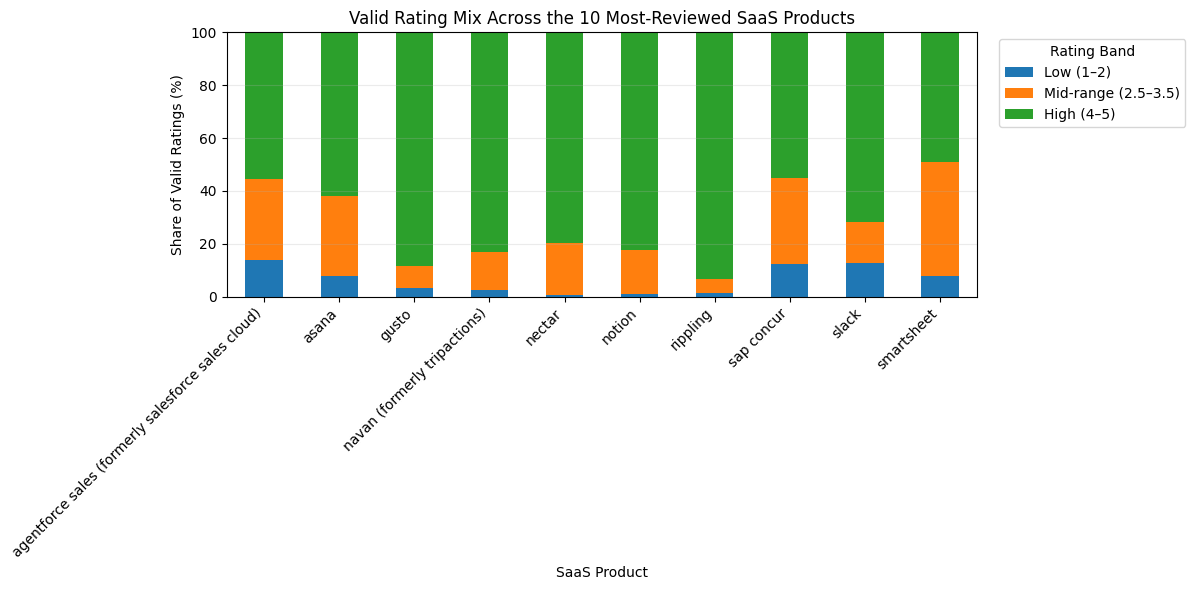

In [185]:
# Stacked bar chart: percentage mix of valid rating bands.
product_rating_mix.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    ylim=(0, 100)
)
plt.title("Valid Rating Mix Across the 10 Most-Reviewed SaaS Products")
plt.xlabel("SaaS Product")
plt.ylabel("Share of Valid Ratings (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Rating Band", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 4.5 Product rating trends over time

Compare yearly average valid ratings for the ten most-reviewed products. Require at least 30 valid ratings in a product-year before plotting that average. This keeps very small product-year groups from dominating the visual.

In [186]:
top_product_keys = product_performance_ranked.sort_values(
    "Total_Reviews", ascending=False
)[product_keys].head(10)

top_product_year_rows = df_valid_ratings.merge(
    top_product_keys,
    on=product_keys,
    how="inner"
).copy()
top_product_year_rows["Review_Year"] = top_product_year_rows["review_date"].dt.year

product_year_rating = (
    top_product_year_rows.groupby(product_keys + ["Review_Year"])
    .agg(
        Valid_Rating_Count=("star_rating", "count"),
        Average_Rating=("star_rating", "mean")
    )
    .reset_index()
)

MIN_PRODUCT_YEAR_REVIEWS = 30
product_year_rating_plot = product_year_rating.loc[
    product_year_rating["Valid_Rating_Count"] >= MIN_PRODUCT_YEAR_REVIEWS
].copy()

print("PRODUCT-YEAR RATING SUMMARY (groups with at least 30 valid ratings)")
print(product_year_rating_plot.head(25).round(2).to_string(index=False))

PRODUCT-YEAR RATING SUMMARY (groups with at least 30 valid ratings)
                                    product_slug                                 product_name_clean  Review_Year  Valid_Rating_Count  Average_Rating
agentforce-sales-formerly-salesforce-sales-cloud agentforce sales (formerly salesforce sales cloud)         2016                  55            2.53
agentforce-sales-formerly-salesforce-sales-cloud agentforce sales (formerly salesforce sales cloud)         2017                 208            2.37
agentforce-sales-formerly-salesforce-sales-cloud agentforce sales (formerly salesforce sales cloud)         2018                  96            2.14
agentforce-sales-formerly-salesforce-sales-cloud agentforce sales (formerly salesforce sales cloud)         2019                 121            2.29
agentforce-sales-formerly-salesforce-sales-cloud agentforce sales (formerly salesforce sales cloud)         2021                  39            2.47
agentforce-sales-formerly-salesforce-s

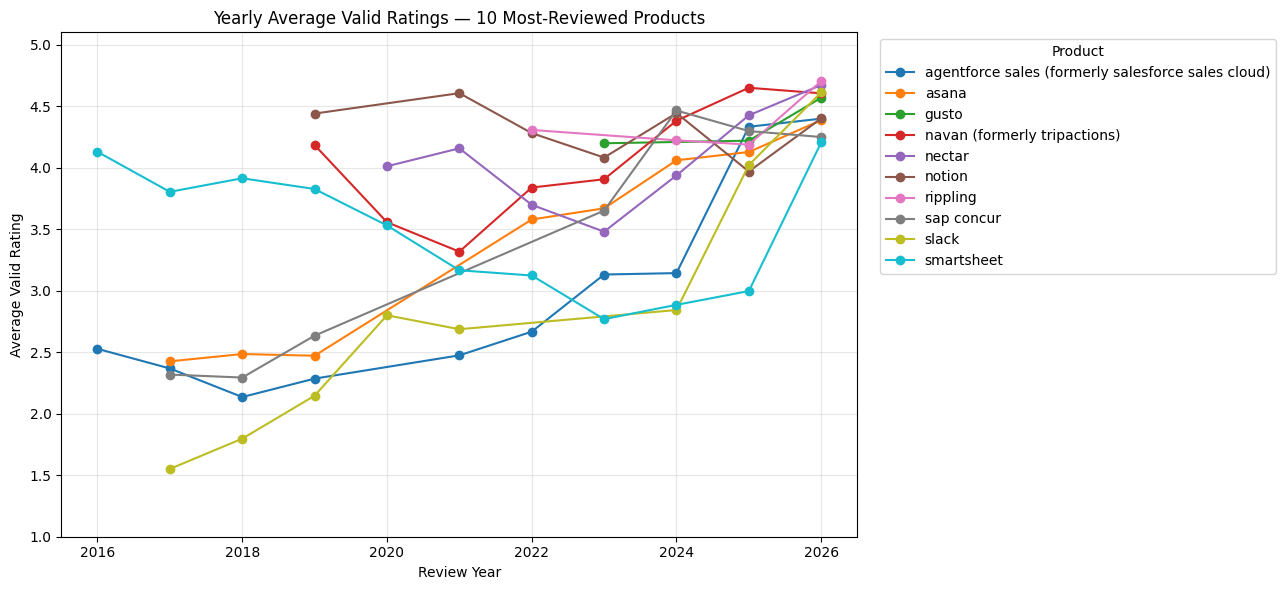

In [187]:
plt.figure(figsize=(13, 6))
for product_name, group in product_year_rating_plot.groupby("product_name_clean"):
    group = group.sort_values("Review_Year")
    plt.plot(group["Review_Year"], group["Average_Rating"], marker="o", linewidth=1.5, label=product_name)

plt.title("Yearly Average Valid Ratings — 10 Most-Reviewed Products")
plt.xlabel("Review Year")
plt.ylabel("Average Valid Rating")
plt.ylim(1, 5.1)
plt.legend(title="Product", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4.6 Customer satisfaction by company size

Compare valid rating metrics across Small business, Mid-market, and Enterprise reviewers. Keep Unknown company size separate. This is an overall descriptive comparison; Phase 6 will add within-product comparisons to reduce product-mix distortion.

In [188]:
company_size_satisfaction = (
    df_valid_ratings.groupby("Company_Size_Segment")
    .agg(
        Valid_Rating_Count=("star_rating", "count"),
        Average_Rating=("star_rating", "mean"),
        Median_Rating=("star_rating", "median"),
        Five_Star_Percentage=("star_rating", lambda s: (s == 5).mean() * 100),
        Low_Rating_Percentage=("star_rating", lambda s: s.between(1, 2).mean() * 100)
    )
    .sort_values("Valid_Rating_Count", ascending=False)
)

company_size_satisfaction["Average_Rating"] = company_size_satisfaction["Average_Rating"].round(2)
company_size_satisfaction["Median_Rating"] = company_size_satisfaction["Median_Rating"].round(2)
company_size_satisfaction["Five_Star_Percentage"] = company_size_satisfaction["Five_Star_Percentage"].round(2)
company_size_satisfaction["Low_Rating_Percentage"] = company_size_satisfaction["Low_Rating_Percentage"].round(2)

print("CUSTOMER SATISFACTION BY COMPANY SIZE")
print(company_size_satisfaction.to_string())

CUSTOMER SATISFACTION BY COMPANY SIZE
                      Valid_Rating_Count  Average_Rating  Median_Rating  Five_Star_Percentage  Low_Rating_Percentage
Company_Size_Segment                                                                                                
Small business                     45289            4.39            4.5                 47.66                   3.03
Mid-market                         39176            4.39            4.5                 46.74                   2.87
Enterprise                         17643            4.35            4.5                 45.38                   3.69
Unknown                             7112            4.51            5.0                 51.45                   0.96


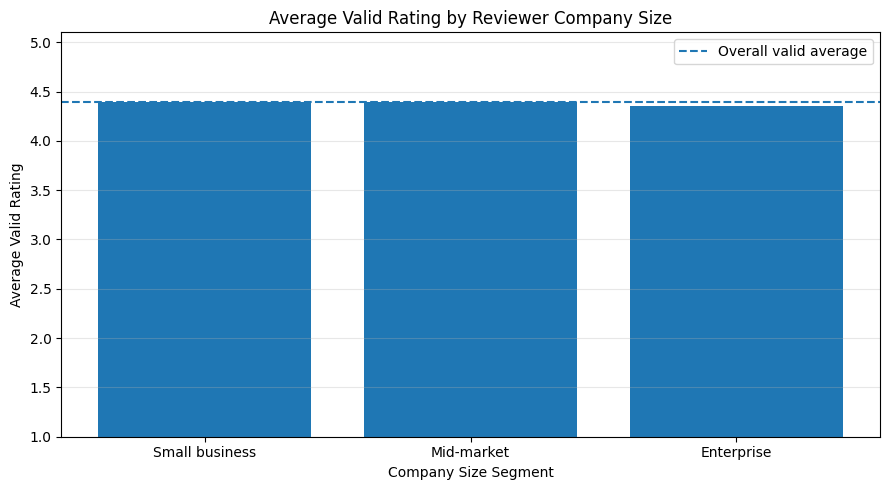

In [189]:
size_chart = company_size_satisfaction.drop(index="Unknown", errors="ignore")
plt.figure(figsize=(9, 5))
plt.bar(size_chart.index, size_chart["Average_Rating"])
plt.axhline(df_valid_ratings["star_rating"].mean(), linestyle="--", label="Overall valid average")
plt.title("Average Valid Rating by Reviewer Company Size")
plt.xlabel("Company Size Segment")
plt.ylabel("Average Valid Rating")
plt.ylim(1, 5.1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# PHASE 5 — TEXT ANALYSIS & FEATURE EXTRACTION

**Business objective:** Identify product capabilities discussed by reviewers and extract recurring customer pain-point themes. Keyword matches are candidate mentions, not proof of positive or negative sentiment. Structured `likes` and `dislikes` fields are analysed separately because they provide a stronger indication of positive and negative feedback.

## 5.1 Prepare review text for analysis

Use `review_text` as the primary text source. Create a separate lowercase/normalised text column; do not overwrite the original review text and do not combine `markdown_content` because it can duplicate content.

In [190]:
import re
from collections import Counter

# Work on a copy containing review text and the fields needed for analysis.
df_text = df_clean.copy()
df_text["review_text_clean"] = (
    df_text["review_text"]
    .fillna("")
    .astype(str)
    .str.casefold()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Rating eligibility is kept as a flag; text analysis does not discard zero/0.5 reviews.
df_text["Has_Valid_Rating"] = df_text["star_rating"].between(1, 5)

df_text["Review_Text_Available"] = df_text["review_text_clean"].ne("")

print("Total review records:", len(df_text))
print("Records with review text:", int(df_text["Review_Text_Available"].sum()))
print("Records without review text:", int((~df_text["Review_Text_Available"]).sum()))
print("Original df_clean unchanged:", "review_text_clean" not in df_clean.columns)

Total review records: 111441
Records with review text: 111159
Records without review text: 282
Original df_clean unchanged: True


## 5.2 Define feature keyword categories

The dictionary below is the initial framework from the project blueprint. We will inspect matched review samples before treating the counts as reliable findings.

In [191]:
feature_keywords = {
    "Ease of use": ["easy to use", "easy-to-use", "ease of use", "ease-of-use", "intuitive", "user friendly", "user-friendly", "simple to use"],
    "Integrations": ["integration", "integrations", "integrate", "integrated", "api", "compatibility", "sync"],
    "Automation": ["automation", "automate", "automated", "workflow automation", "automations"],
    "Collaboration": ["collaboration", "collaborate", "teamwork", "sharing", "shared workspace"],
    "Customisation": ["customization", "customisation", "customize", "customise", "flexibility", "configurable"],
    "Reporting": ["reporting", "reports", "dashboard", "dashboards", "analytics", "visualization", "visualisation"],
    "AI capabilities": ["artificial intelligence", "ai", "ai assistant", "generative ai", "copilot"],
    "Security": ["security", "privacy", "compliance", "encryption", "access control"],
    "Performance": ["performance", "speed", "slow", "loading", "reliability", "latency"],
    "Mobile experience": ["mobile app", "mobile", "ios", "android", "mobile application"]
}

# Escape keyword text so punctuation such as hyphens is treated literally.
def build_keyword_pattern(keyword_list):
    alternatives = [re.escape(term) for term in keyword_list]
    return re.compile(r"(?<!\w)(?:" + "|".join(alternatives) + r")(?!\w)", flags=re.IGNORECASE)

feature_patterns = {
    category: build_keyword_pattern(keywords)
    for category, keywords in feature_keywords.items()
}

print("Feature categories created:", len(feature_patterns))
for category, keywords in feature_keywords.items():
    print(f"{category}: {len(keywords)} keywords")

Feature categories created: 10
Ease of use: 8 keywords
Integrations: 7 keywords
Automation: 5 keywords
Collaboration: 5 keywords
Customisation: 6 keywords
Reporting: 7 keywords
AI capabilities: 5 keywords
Security: 5 keywords
Performance: 6 keywords
Mobile experience: 5 keywords


## 5.3 Extract feature mentions from review text

A review is counted once per feature category even if it repeats several keywords from that category. Percentages use reviews with available review text as the denominator. Average rating is calculated only among matched reviews with valid 1–5 ratings.

In [192]:
feature_flag_columns = {}
for category, pattern in feature_patterns.items():
    flag_column = "Feature__" + re.sub(r"[^A-Za-z0-9]+", "_", category).strip("_")
    feature_flag_columns[category] = flag_column
    df_text[flag_column] = df_text["review_text_clean"].str.contains(pattern, na=False)

text_available_count = int(df_text["Review_Text_Available"].sum())
feature_summary_rows = []

for category, flag_column in feature_flag_columns.items():
    matched = df_text[flag_column]
    valid_matched = df_text.loc[matched & df_text["Has_Valid_Rating"], "star_rating"]
    feature_summary_rows.append({
        "Feature_Category": category,
        "Review_Mentions": int(matched.sum()),
        "Percentage_of_Text_Reviews": (matched.sum() / text_available_count * 100) if text_available_count else np.nan,
        "Valid_Rating_Count": int(valid_matched.count()),
        "Average_Valid_Rating": valid_matched.mean()
    })

feature_summary = pd.DataFrame(feature_summary_rows).sort_values(
    "Review_Mentions", ascending=False
)
print("FEATURE MENTION SUMMARY")
print(feature_summary.round(2).to_string(index=False))

FEATURE MENTION SUMMARY
 Feature_Category  Review_Mentions  Percentage_of_Text_Reviews  Valid_Rating_Count  Average_Valid_Rating
      Ease of use            34673                       31.19               34263                  4.44
     Integrations            15661                       14.09               15361                  4.36
        Reporting            12335                       11.10               12104                  4.31
      Performance             9506                        8.55                9303                  4.35
       Automation             8723                        7.85                8554                  4.40
    Customisation             7774                        6.99                7678                  4.38
  AI capabilities             7612                        6.85                7547                  4.46
    Collaboration             6750                        6.07                6647                  4.25
Mobile experience             4

## 5.4 Feature mentions by product

Identify which products have the most review text mentioning each feature. The table reports review-level mentions, not the total number of repeated keyword occurrences.

In [193]:
feature_product_rows = []
for category, flag_column in feature_flag_columns.items():
    matched = df_text.loc[df_text[flag_column]]
    grouped = (
        matched.groupby(product_keys)
        .size()
        .rename("Feature_Review_Count")
        .reset_index()
    )
    grouped["Feature_Category"] = category
    feature_product_rows.append(grouped)

feature_by_product = pd.concat(feature_product_rows, ignore_index=True)
feature_by_product = feature_by_product.sort_values(
    ["Feature_Category", "Feature_Review_Count"], ascending=[True, False]
)

print("TOP PRODUCTS BY FEATURE MENTION")
for category in feature_keywords:
    print(f"\n{category}")
    print(
        feature_by_product.loc[feature_by_product["Feature_Category"] == category,
                               ["product_name_clean", "Feature_Review_Count"]]
        .head(5).to_string(index=False)
    )

TOP PRODUCTS BY FEATURE MENTION

Ease of use
product_name_clean  Feature_Review_Count
             gusto                  1121
            notion                  1056
          rippling                   970
        smartsheet                   781
             canva                   770

Integrations
                                product_name_clean  Feature_Review_Count
                                            notion                   768
                                             slack                   727
                                            zapier                   520
agentforce sales (formerly salesforce sales cloud)                   470
                                   microsoft teams                   390

Automation
    product_name_clean  Feature_Review_Count
                zapier                   547
 hubspot marketing hub                   393
               waalaxy                   378
              airtable                   367
monday work manageme

## 5.5 Manually validate feature keyword matches

The next cell builds a reproducible sample of up to five actual reviews per feature category. Check the displayed context for false positives and sentiment direction. The mention counts remain candidate keyword counts; a match is not automatically praise or evidence that the feature works well.

In [194]:
def show_feature_samples(category, sample_size=5, random_state=42):
    """Return reproducible examples for contextual review of one feature category."""
    if category not in feature_flag_columns:
        raise ValueError(f"Unknown feature category: {category}")
    flag_column = feature_flag_columns[category]
    columns_to_show = ["product_name_clean", "star_rating", "title", "review_text"]
    matched_rows = df_text.loc[df_text[flag_column], columns_to_show]
    return matched_rows.sample(
        n=min(sample_size, len(matched_rows)), random_state=random_state
    )

# Build a compact validation set for every feature category.
feature_validation_samples = []
for category, flag_column in feature_flag_columns.items():
    matched_rows = df_text.loc[
        df_text[flag_column],
        ["review_id", "product_name_clean", "star_rating", "title", "review_text"]
    ]
    sample = matched_rows.sample(n=min(5, len(matched_rows)), random_state=42).copy()
    sample["Feature_Category"] = category
    feature_validation_samples.append(sample)

feature_validation_samples = (
    pd.concat(feature_validation_samples, ignore_index=True)
    if feature_validation_samples else pd.DataFrame()
)
print("FEATURE KEYWORD VALIDATION SAMPLE")
print("Sampled examples:", len(feature_validation_samples))
print("Categories represented:", feature_validation_samples["Feature_Category"].nunique())

# The complete contextual sample is exported to the private QA folder in Cell 310.
# Display only a small working sample to keep notebook output compact.
if PUBLIC_SAFE_MODE:
    print("PUBLIC_SAFE_MODE=True: individual review excerpts are not displayed.")
else:
    display(feature_validation_samples.head(5))


FEATURE KEYWORD VALIDATION SAMPLE
Sampled examples: 50
Categories represented: 10


,review_id,product_name_clean,star_rating,title,review_text,Feature_Category
0,3733114,workday hcm,3.5,workday includes everything you need but is ha...,I like that it's pretty customizable and once ...,Ease of use
1,11633849,hubspot sales hub,5.0,HubSpot Sales Hub: Superior CRM for Unmatched ...,I really appreciate HubSpot Sales Hub for its ...,Ease of use
2,10879440,cloudtalk,4.5,Easy to use,"The call quality is Great, even on weaker inte...",Ease of use
3,10532592,rippling,0.0,Highly recommend it to anyone looking for an a...,One thing that really stands out is the layout...,Ease of use
4,13215968,paycom,4.0,easy UI - detailed expected pay resources,"IT HAS A USER FRIENDLY UI, IT SHOWS PAY TO DAT...",Ease of use


## 5.6 Analyse structured positive and negative feedback separately

`likes` is treated as structured positive feedback text, `dislikes` as structured negative feedback text, and `problems_solved` as a description of the problem addressed. Missing fields remain missing; they are not replaced by zero or empty business meaning.

In [195]:
structured_feedback_fields = ["likes", "dislikes", "problems_solved"]

for field in structured_feedback_fields:
    print(
        f"{field}: available={int(df_clean[field].notna().sum()):,}; "
        f"missing={int(df_clean[field].isna().sum()):,}"
    )

# Create normalised helper text columns without changing df_clean.
df_structured = df_clean.copy()
for field in structured_feedback_fields:
    df_structured[field + "_clean"] = (
        df_structured[field].fillna("").astype(str).str.casefold()
        .str.replace(r"\s+", " ", regex=True).str.strip()
    )

print("Structured feedback analysis copy created:", df_structured.shape)

likes: available=35,133; missing=76,308
dislikes: available=35,079; missing=76,362
problems_solved: available=34,942; missing=76,499


Structured feedback analysis copy created: (111441, 28)


## 5.7 Feature themes in likes and dislikes

Compare how often each feature category appears in the `likes` and `dislikes` fields. These fields support a more defensible positive/negative distinction than searching the general review text alone.

In [196]:
structured_feature_rows = []
for category, pattern in feature_patterns.items():
    likes_match = df_structured["likes_clean"].str.contains(pattern, na=False)
    dislikes_match = df_structured["dislikes_clean"].str.contains(pattern, na=False)
    structured_feature_rows.append({
        "Feature_Category": category,
        "Likes_Mentions": int(likes_match.sum()),
        "Dislikes_Mentions": int(dislikes_match.sum())
    })

structured_feature_summary = pd.DataFrame(structured_feature_rows)
structured_feature_summary["Likes_Dislikes_Difference"] = (
    structured_feature_summary["Likes_Mentions"] - structured_feature_summary["Dislikes_Mentions"]
)
structured_feature_summary = structured_feature_summary.sort_values(
    "Likes_Mentions", ascending=False
)
print(structured_feature_summary.to_string(index=False))

 Feature_Category  Likes_Mentions  Dislikes_Mentions  Likes_Dislikes_Difference
      Ease of use            8430               2297                       6133
     Integrations            3730               2128                       1602
        Reporting            2510               2111                        399
       Automation            2163                862                       1301
  AI capabilities            1868               1237                        631
    Collaboration            1522                315                       1207
    Customisation            1459               1444                         15
      Performance            1219               2173                       -954
         Security             835                398                        437
Mobile experience             621                741                       -120


## 5.8 Customer pain-point keyword framework

The categories below are candidates for complaint analysis. Search `dislikes` first because it is the structured negative-feedback field. Keyword matches still require manual sample validation before a category is reported as a confirmed complaint.

In [197]:
pain_point_keywords = {
    "Pricing": ["pricing", "price", "expensive", "cost", "subscription fee", "overpriced", "affordable"],
    "Onboarding": ["onboarding", "setup", "set up", "implementation", "training", "migration"],
    "Learning curve": ["difficult to learn", "hard to learn", "confusing", "complicated", "steep learning curve"],
    "Customer support": ["customer support", "support team", "response time", "customer service", "help desk"],
    "Performance": ["slow", "lag", "latency", "crash", "crashes", "bug", "bugs", "loading", "glitch"],
    "Integrations": ["integration", "integrations", "api", "compatibility", "sync", "connect to"],
    "Functionality": ["missing feature", "limited features", "lack of features", "limitation", "functionality", "feature request"],
    "Mobile experience": ["mobile app", "mobile", "ios", "android"]
}

pain_point_patterns = {
    category: build_keyword_pattern(keywords)
    for category, keywords in pain_point_keywords.items()
}

pain_point_rows = []
for category, pattern in pain_point_patterns.items():
    dislikes_match = df_structured["dislikes_clean"].str.contains(pattern, na=False)
    review_text_match = df_text["review_text_clean"].str.contains(pattern, na=False)
    pain_point_rows.append({
        "Pain_Point_Category": category,
        "Dislikes_Field_Mentions": int(dislikes_match.sum()),
        "Review_Text_Candidate_Mentions": int(review_text_match.sum())
    })

pain_point_summary = pd.DataFrame(pain_point_rows).sort_values(
    "Dislikes_Field_Mentions", ascending=False
)
print("PAIN-POINT KEYWORD SUMMARY")
print(pain_point_summary.to_string(index=False))

PAIN-POINT KEYWORD SUMMARY
Pain_Point_Category  Dislikes_Field_Mentions  Review_Text_Candidate_Mentions
            Pricing                     2686                            9695
         Onboarding                     2685                           21191
        Performance                     2237                            6739
     Learning curve                     1820                            5247
       Integrations                     1743                           12199
   Customer support                     1423                            8592
      Functionality                      884                            3958
  Mobile experience                      741                            4003


## 5.9 Validate pain-point matches with review samples

The next cell builds a reproducible sample of up to five actual structured-dislike records per pain-point category. Check that the text describes the category and not merely mentions the same word. The counts should be treated as candidate mentions until that review is complete.

In [198]:
def show_pain_point_samples(category, sample_size=5, random_state=42):
    """Return reproducible structured-dislike examples for one candidate pain point."""
    if category not in pain_point_patterns:
        raise ValueError(f"Unknown pain-point category: {category}")
    pattern = pain_point_patterns[category]
    mask = df_structured["dislikes_clean"].str.contains(pattern, na=False)
    columns_to_show = ["product_name_clean", "star_rating", "title", "dislikes"]
    matched_rows = df_structured.loc[mask, columns_to_show]
    return matched_rows.sample(n=min(sample_size, len(matched_rows)), random_state=random_state)

# Create a deterministic sample from each category for contextual validation.
pain_point_validation_samples = []
for category, pattern in pain_point_patterns.items():
    mask = df_structured["dislikes_clean"].str.contains(pattern, na=False)
    matched_rows = df_structured.loc[
        mask, ["review_id", "product_name_clean", "star_rating", "title", "dislikes"]
    ]
    sample = matched_rows.sample(n=min(5, len(matched_rows)), random_state=42).copy()
    sample["Pain_Point_Category"] = category
    pain_point_validation_samples.append(sample)

pain_point_validation_samples = (
    pd.concat(pain_point_validation_samples, ignore_index=True)
    if pain_point_validation_samples else pd.DataFrame()
)
print("STRUCTURED DISLIKE / PAIN-POINT VALIDATION SAMPLE")
print("Sampled examples:", len(pain_point_validation_samples))
print("Categories represented:", pain_point_validation_samples["Pain_Point_Category"].nunique())

# The complete contextual sample is exported to the private QA folder in Cell 310.
if PUBLIC_SAFE_MODE:
    print("PUBLIC_SAFE_MODE=True: individual feedback excerpts are not displayed.")
else:
    display(pain_point_validation_samples.head(5))


STRUCTURED DISLIKE / PAIN-POINT VALIDATION SAMPLE
Sampled examples: 40
Categories represented: 8


,review_id,product_name_clean,star_rating,title,dislikes,Pain_Point_Category
0,4534309,sap concur,2.5,The product everyone uses,For the end user it is pretty easy to use. For...,Pricing
1,8872952,hubspot sales hub,1.5,Waste of money,"Unless you buy the most expensive package, you...",Pricing
2,12888808,agentforce sales (formerly salesforce sales cl...,3.5,Powerful but complex. Worth it if you're ready...,The learning curve is steep and the interface ...,Pricing
3,9814281,fin by intercom,4.0,All in 1place,1. **Pricing:** Intercom’s pricing is expensiv...,Pricing
4,9647446,waalaxy,4.5,Great for prospecting,Free version is very limited. and entry cost i...,Pricing


## 5.10 SaaS business terminology extraction

Count review-level mentions of selected SaaS terms. These counts measure vocabulary mentions only; they do not calculate ARR, MRR, CAC, LTV or other financial metrics. Ambiguous acronyms (especially MRR) must be reviewed in context.

In [199]:
saas_terminology = {
    "ARR": ["arr", "annual recurring revenue"],
    "MRR": ["mrr", "monthly recurring revenue"],
    "CAC": ["cac", "customer acquisition cost"],
    "LTV": ["ltv", "lifetime value", "customer lifetime value"],
    "NRR": ["nrr", "net revenue retention"],
    "ACV": ["acv", "annual contract value"],
    "ROI": ["roi", "return on investment"],
    "CRM": ["crm", "customer relationship management"],
    "ERP": ["erp", "enterprise resource planning"],
    "API": ["api", "application programming interface"],
    "AI": ["artificial intelligence", "ai assistant", "generative ai"],
    "UX": ["ux", "user experience"],
    "UI": ["ui", "user interface"],
    "SaaS": ["saas", "software as a service"],
    "Cloud": ["cloud", "cloud-based", "cloud computing"],
    "Churn": ["churn", "churn rate"],
    "Retention": ["retention", "customer retention"],
    "Renewal": ["renewal", "renewals"],
    "Onboarding": ["onboarding"],
    "Adoption": ["adoption", "user adoption"],
    "Engagement": ["engagement", "user engagement"],
    "Customer support": ["customer support", "customer service"],
    "Implementation": ["implementation", "implementation process"]
}

terminology_patterns = {
    term: build_keyword_pattern(phrases)
    for term, phrases in saas_terminology.items()
}

terminology_rows = []
for term, pattern in terminology_patterns.items():
    matches = df_text["review_text_clean"].str.contains(pattern, na=False)
    terminology_rows.append({
        "Term": term,
        "Review_Mentions": int(matches.sum()),
        "Percentage_of_Text_Reviews": matches.sum() / max(text_available_count, 1) * 100
    })

terminology_summary = pd.DataFrame(terminology_rows).sort_values(
    "Review_Mentions", ascending=False
)
print(terminology_summary.round(2).to_string(index=False))

            Term  Review_Mentions  Percentage_of_Text_Reviews
              UI             7723                        6.95
Customer support             7004                        6.30
             CRM             3319                        2.99
              UX             2917                        2.62
      Onboarding             2888                        2.60
  Implementation             2007                        1.81
           Cloud             1703                        1.53
      Engagement             1044                        0.94
             API              817                        0.73
             ROI              392                        0.35
              AI              350                        0.31
        Adoption              347                        0.31
            SaaS              300                        0.27
         Renewal              227                        0.20
             ERP              199                        0.18
       R

## 5.11 Inspect terminology in context

The next cell creates a reproducible sample of up to five actual review texts per term. Acronyms need context: for example, MRR can mean Monthly Recurring Revenue or Mean Reciprocal Rank. These are vocabulary mentions, not financial calculations.

In [200]:
def show_terminology_samples(term, sample_size=5, random_state=42):
    if term not in terminology_patterns:
        raise ValueError(f"Unknown terminology: {term}")
    pattern = terminology_patterns[term]
    mask = df_text["review_text_clean"].str.contains(pattern, na=False)
    cols = ["product_name_clean", "star_rating", "title", "review_text"]
    matched_rows = df_text.loc[mask, cols]
    return matched_rows.sample(n=min(sample_size, len(matched_rows)), random_state=random_state)

terminology_validation_samples = []
for term in saas_terminology:
    pattern = terminology_patterns[term]
    mask = df_text["review_text_clean"].str.contains(pattern, na=False)
    matched_rows = df_text.loc[
        mask, ["review_id", "product_name_clean", "star_rating", "title", "review_text"]
    ]
    sample = matched_rows.sample(n=min(5, len(matched_rows)), random_state=42).copy()
    sample["Terminology"] = term
    terminology_validation_samples.append(sample)

terminology_validation_samples = (
    pd.concat(terminology_validation_samples, ignore_index=True)
    if terminology_validation_samples else pd.DataFrame()
)
print("SAAS TERMINOLOGY VALIDATION SAMPLE")
print("Sampled examples:", len(terminology_validation_samples))
print("Terms represented:", terminology_validation_samples["Terminology"].nunique())

# The complete contextual sample is exported to the private QA folder in Cell 310.
if PUBLIC_SAFE_MODE:
    print("PUBLIC_SAFE_MODE=True: individual review excerpts are not displayed.")
else:
    display(terminology_validation_samples.head(5))


SAAS TERMINOLOGY VALIDATION SAMPLE
Sampled examples: 108
Terms represented: 23


,review_id,product_name_clean,star_rating,title,review_text,Terminology
0,12466802,everstage,5.0,Smooth UI with Powerful Monthly Breakouts for ...,"Breakouts by month, ARR and Renewals. Ability ...",ARR
1,9678123,everstage,4.0,"Easy to read, and modern","Very easy to use, intuitive, clean and readabl...",ARR
2,8615914,captivateiq,4.5,Great way to track commission,It's very easy to use. In one short demo/meeti...,ARR
3,9655820,everstage,5.0,Account Manager,I love being able to see my payout in real tim...,ARR
4,12465107,hubspot sales hub,4.5,Automates Outreach and Tracks Key ARR Metrics ...,We like the ability Hubspot gives us to automa...,ARR


# PHASE 6 — COMPANY SEGMENTATION & REVIEW BIAS ANALYSIS

**Business objective:** Compare reviewer experiences across company sizes and examine whether ratings differ by review source, incentivisation, and verified-current-user status. These are descriptive associations, not causal effects. Where possible, compare groups within the same product to reduce product-mix distortion.

## 6.1 Company-size segment profile

Summarise review volumes and valid rating metrics for Small business, Mid-market, Enterprise, and Unknown company size.

In [201]:
company_segment_profile = (
    df_clean.groupby("Company_Size_Segment")
    .agg(Total_Reviews=("review_id", "size"))
    .join(
        df_valid_ratings.groupby("Company_Size_Segment").agg(
            Valid_Rating_Count=("star_rating", "count"),
            Average_Rating=("star_rating", "mean"),
            Median_Rating=("star_rating", "median"),
            Five_Star_Percentage=("star_rating", lambda s: (s == 5).mean() * 100),
            Low_Rating_Percentage=("star_rating", lambda s: s.between(1, 2).mean() * 100)
        ),
        how="left"
    )
)
company_segment_profile["Share_of_All_Reviews"] = (
    company_segment_profile["Total_Reviews"] / len(df_clean) * 100
)
print(company_segment_profile.round(2).to_string())

                      Total_Reviews  Valid_Rating_Count  Average_Rating  Median_Rating  Five_Star_Percentage  Low_Rating_Percentage  Share_of_All_Reviews
Company_Size_Segment                                                                                                                                     
Enterprise                    17902               17643            4.35            4.5                 45.38                   3.69                 16.06
Mid-market                    39816               39176            4.39            4.5                 46.74                   2.87                 35.73
Small business                46535               45289            4.39            4.5                 47.66                   3.03                 41.76
Unknown                        7188                7112            4.51            5.0                 51.45                   0.96                  6.45


## 6.2 Compare company-size ratings within the same products

A simple overall comparison can be distorted if segments review different products. This table compares company-size groups within product, retaining only product-segment groups with at least 30 valid ratings.

In [202]:
MIN_PRODUCT_SEGMENT_REVIEWS = 30
product_segment_ratings = (
    df_valid_ratings.groupby(product_keys + ["Company_Size_Segment"])
    .agg(
        Valid_Rating_Count=("star_rating", "count"),
        Average_Rating=("star_rating", "mean"),
        Median_Rating=("star_rating", "median")
    )
    .reset_index()
)

product_segment_ratings_eligible = product_segment_ratings.loc[
    product_segment_ratings["Valid_Rating_Count"] >= MIN_PRODUCT_SEGMENT_REVIEWS
].copy()

print("Eligible product × company-size groups:", len(product_segment_ratings_eligible))
print(product_segment_ratings_eligible.sort_values(
    ["product_name_clean", "Company_Size_Segment"]
).head(30).round(2).to_string(index=False))

Eligible product × company-size groups: 267
                                    product_slug                                 product_name_clean Company_Size_Segment  Valid_Rating_Count  Average_Rating  Median_Rating
                                       1password                                          1password           Enterprise                 213            4.58            4.5
                                       1password                                          1password           Mid-market                 392            4.49            4.5
                                       1password                                          1password       Small business                 463            4.46            4.5
                                         action1                                            action1           Mid-market                 602            4.88            5.0
                                         action1                                            acti

## 6.3 Feature and pain-point mentions by company size

Use the review-level theme flags built in Phase 5. Report the percentage of available review texts in each segment that mention each theme. The values are keyword-based candidate mentions and must be interpreted using the validation samples.

In [203]:
theme_segment_data = df_text.loc[df_text["Review_Text_Available"]].copy()
feature_segment_rows = []
for category, flag_column in feature_flag_columns.items():
    grouped = theme_segment_data.groupby("Company_Size_Segment")[flag_column].agg(
        Review_Count="size", Mention_Count="sum", Mention_Rate="mean"
    ).reset_index()
    grouped["Feature_Category"] = category
    grouped["Mention_Rate_Percent"] = grouped["Mention_Rate"] * 100
    feature_segment_rows.append(grouped)

feature_by_company_size = pd.concat(feature_segment_rows, ignore_index=True)
print("FEATURE MENTION RATE BY COMPANY SIZE")
print(feature_by_company_size[
    ["Feature_Category", "Company_Size_Segment", "Review_Count", "Mention_Count", "Mention_Rate_Percent"]
].round(2).to_string(index=False))

FEATURE MENTION RATE BY COMPANY SIZE
 Feature_Category Company_Size_Segment  Review_Count  Mention_Count  Mention_Rate_Percent
      Ease of use           Enterprise         17871           5293                 29.62
      Ease of use           Mid-market         39730          12312                 30.99
      Ease of use       Small business         46394          14394                 31.03
      Ease of use              Unknown          7164           2674                 37.33
     Integrations           Enterprise         17871           2430                 13.60
     Integrations           Mid-market         39730           5405                 13.60
     Integrations       Small business         46394           6952                 14.98
     Integrations              Unknown          7164            874                 12.20
       Automation           Enterprise         17871           1169                  6.54
       Automation           Mid-market         39730           

## 6.4 Ratings by review source

Compare review volume and valid rating metrics across all observed source categories. Keep the valid-rating count visible because some source categories are small.

In [204]:
review_source_rating = (
    df_clean.groupby("review_source")
    .agg(Total_Reviews=("review_id", "size"))
    .join(
        df_valid_ratings.groupby("review_source").agg(
            Valid_Rating_Count=("star_rating", "count"),
            Average_Rating=("star_rating", "mean"),
            Median_Rating=("star_rating", "median"),
            Five_Star_Percentage=("star_rating", lambda s: (s == 5).mean() * 100),
            Low_Rating_Percentage=("star_rating", lambda s: s.between(1, 2).mean() * 100)
        ),
        how="left"
    )
)
print("RATING METRICS BY REVIEW SOURCE")
print(review_source_rating.sort_values("Total_Reviews", ascending=False).round(2).to_string())

RATING METRICS BY REVIEW SOURCE
                                  Total_Reviews  Valid_Rating_Count  Average_Rating  Median_Rating  Five_Star_Percentage  Low_Rating_Percentage
review_source                                                                                                                                  
Organic                                   98222               96362            4.44            4.5                 48.97                   2.32
G2 invite                                  4859                4698            3.73            4.0                 24.37                  14.11
Seller invite                              4550                4420            4.21            4.5                 36.99                   3.94
G2 invite on behalf of seller              2222                2176            4.25            4.5                 39.02                   3.81
In-app                                      926                 921            4.44            5.0      

## 6.5 Incentivised vs non-incentivised ratings

Compare valid rating distributions and summary metrics for incentivised and non-incentivised reviews. Differences are associations and do not establish that incentives caused rating differences.

In [205]:
incentive_rating_summary = (
    df_clean.groupby("incentivized")
    .agg(Total_Reviews=("review_id", "size"))
    .join(
        df_valid_ratings.groupby("incentivized").agg(
            Valid_Rating_Count=("star_rating", "count"),
            Average_Rating=("star_rating", "mean"),
            Median_Rating=("star_rating", "median"),
            Five_Star_Percentage=("star_rating", lambda s: (s == 5).mean() * 100),
            Low_Rating_Percentage=("star_rating", lambda s: s.between(1, 2).mean() * 100)
        ),
        how="left"
    )
)
incentive_rating_summary.index = incentive_rating_summary.index.map({0: "Non-incentivized", 1: "Incentivized"}).fillna("Unknown")
print(incentive_rating_summary.round(2).to_string())

                  Total_Reviews  Valid_Rating_Count  Average_Rating  Median_Rating  Five_Star_Percentage  Low_Rating_Percentage
incentivized                                                                                                                   
Non-incentivized          40554               39184            4.49            5.0                 52.63                   2.13
Incentivized              70887               70036            4.33            4.5                 44.17                   3.40


## 6.6 Review-source × incentive analysis

Examine how incentivisation is distributed across review sources and compare valid ratings for each source/incentive combination. Retain group counts to reveal small samples.

In [206]:
source_incentive_counts = pd.crosstab(
    df_clean["review_source"],
    df_clean["incentivized"],
    margins=True
)
print("REVIEW SOURCE × INCENTIVE COUNTS")
print(source_incentive_counts.to_string())

source_incentive_ratings = (
    df_valid_ratings.groupby(["review_source", "incentivized"])
    .agg(
        Valid_Rating_Count=("star_rating", "count"),
        Average_Rating=("star_rating", "mean"),
        Median_Rating=("star_rating", "median")
    )
    .reset_index()
    .sort_values(["review_source", "incentivized"])
)
print("\nVALID RATINGS BY SOURCE AND INCENTIVE STATUS")
print(source_incentive_ratings.round(2).to_string(index=False))

REVIEW SOURCE × INCENTIVE COUNTS
incentivized                          0      1     All
review_source                                         
G2 Gives Campaign                     0    105     105
G2 invite                           128   4731    4859
G2 invite on behalf of seller       319   1903    2222
In-app                              228    698     926
Organic                           39212  59010   98222
Organic Review from Pop Up            8      0       8
Organic Review from User Profile    354     33     387
Seller invite                       156   4394    4550
Thank You page                      149     13     162
All                               40554  70887  111441

VALID RATINGS BY SOURCE AND INCENTIVE STATUS
                   review_source  incentivized  Valid_Rating_Count  Average_Rating  Median_Rating
               G2 Gives Campaign             1                 101            3.18            3.0
                       G2 invite             0                 12

## 6.7 Compare incentive status within the same products

For each product, compare incentivised and non-incentivised ratings only when both groups have at least 30 valid ratings. The difference is `incentivized average − non-incentivized average`.

In [207]:
product_incentive_ratings = (
    df_valid_ratings.groupby(product_keys + ["incentivized"])
    .agg(
        Valid_Rating_Count=("star_rating", "count"),
        Average_Rating=("star_rating", "mean")
    )
    .reset_index()
)

product_incentive_pivot = product_incentive_ratings.pivot_table(
    index=product_keys,
    columns="incentivized",
    values=["Valid_Rating_Count", "Average_Rating"]
)

# Require both incentive groups to meet the minimum sample size.
required_columns = [("Valid_Rating_Count", 0), ("Valid_Rating_Count", 1),
                    ("Average_Rating", 0), ("Average_Rating", 1)]
product_incentive_comparison = product_incentive_pivot.dropna(subset=required_columns).copy()
product_incentive_comparison = product_incentive_comparison.loc[
    (product_incentive_comparison[("Valid_Rating_Count", 0)] >= 30) &
    (product_incentive_comparison[("Valid_Rating_Count", 1)] >= 30)
]
product_incentive_comparison["Average_Rating_Difference_Incentivized_Minus_Non"] = (
    product_incentive_comparison[("Average_Rating", 1)] -
    product_incentive_comparison[("Average_Rating", 0)]
)

print("PRODUCTS WITH >=30 VALID RATINGS IN BOTH INCENTIVE GROUPS:", len(product_incentive_comparison))
print(product_incentive_comparison.round(2).to_string())

PRODUCTS WITH >=30 VALID RATINGS IN BOTH INCENTIVE GROUPS: 73
                                                                                                    Average_Rating       Valid_Rating_Count         Average_Rating_Difference_Incentivized_Minus_Non
incentivized                                                                                                     0     1                  0       1                                                 
product_slug                                     product_name_clean                                                                                                                                 
1password                                        1password                                                    4.53  4.48              354.0   715.0                                            -0.04
action1                                          action1                                                      4.88  4.88              198.0   894.0   

## 6.8 Verified-current-user rating comparison

Compare valid ratings for reviews marked as verified current users versus reviews not marked as verified. This is a descriptive check, not an assessment of reviewer honesty.

In [208]:
verified_user_rating_summary = (
    df_clean.groupby("verified_current_user")
    .agg(Total_Reviews=("review_id", "size"))
    .join(
        df_valid_ratings.groupby("verified_current_user").agg(
            Valid_Rating_Count=("star_rating", "count"),
            Average_Rating=("star_rating", "mean"),
            Median_Rating=("star_rating", "median"),
            Five_Star_Percentage=("star_rating", lambda s: (s == 5).mean() * 100),
            Low_Rating_Percentage=("star_rating", lambda s: s.between(1, 2).mean() * 100)
        ),
        how="left"
    )
)
verified_user_rating_summary.index = verified_user_rating_summary.index.map(
    {0: "Not marked verified", 1: "Verified current user"}
).fillna("Unknown")
print(verified_user_rating_summary.round(2).to_string())

                       Total_Reviews  Valid_Rating_Count  Average_Rating  Median_Rating  Five_Star_Percentage  Low_Rating_Percentage
verified_current_user                                                                                                               
Not marked verified            43805               42652            4.31            4.5                 42.88                   3.81
Verified current user          67636               66568            4.44            4.5                 49.98                   2.39


## 6.9 Compare review sources within the same products

Overall source comparisons can be distorted when source categories have different product mixes. This table compares each product-source group with that product's own average valid rating. Only product-source groups with at least 30 valid ratings are retained. The difference is descriptive and does not establish that review source caused a rating difference.

In [209]:
MIN_PRODUCT_SOURCE_REVIEWS = 30

product_overall_rating = (
    df_valid_ratings.groupby(product_keys)
    .agg(Product_Valid_Rating_Count=("star_rating", "count"),
         Product_Average_Rating=("star_rating", "mean"))
    .reset_index()
)

product_source_rating = (
    df_valid_ratings.groupby(product_keys + ["review_source"])
    .agg(Valid_Rating_Count=("star_rating", "count"),
         Average_Rating=("star_rating", "mean"),
         Median_Rating=("star_rating", "median"),
         Five_Star_Percentage=("star_rating", lambda s: (s == 5).mean() * 100),
         Low_Rating_Percentage=("star_rating", lambda s: s.between(1, 2).mean() * 100))
    .reset_index()
    .merge(product_overall_rating, on=product_keys, how="left")
)
product_source_rating_eligible = product_source_rating.loc[
    product_source_rating["Valid_Rating_Count"] >= MIN_PRODUCT_SOURCE_REVIEWS
].copy()
product_source_rating_eligible["Difference_From_Product_Average"] = (
    product_source_rating_eligible["Average_Rating"] -
    product_source_rating_eligible["Product_Average_Rating"]
)

print("Eligible product × review-source groups:", len(product_source_rating_eligible))
print("Products represented:", product_source_rating_eligible[product_keys].drop_duplicates().shape[0])
print(product_source_rating_eligible.sort_values(
    ["product_name_clean", "review_source"]
).round(3).head(40).to_string(index=False))

Eligible product × review-source groups: 144
Products represented: 79
                                    product_slug                                 product_name_clean                    review_source  Valid_Rating_Count  Average_Rating  Median_Rating  Five_Star_Percentage  Low_Rating_Percentage  Product_Valid_Rating_Count  Product_Average_Rating  Difference_From_Product_Average
                                       1password                                          1password                          Organic                1050           4.493            4.5                44.476                  1.524                        1069                   4.496                           -0.003
                                         action1                                            action1                          Organic                1003           4.880            5.0                83.051                  0.100                        1092                   4.878                      

## 6.10 Compare verified-current-user status within the same products

For each product, compare reviews marked as verified current users with reviews not marked as verified. Require at least 30 valid ratings in each group. This reduces product-mix distortion but remains a descriptive association, not proof that verification changes rating behaviour.

In [210]:
MIN_PRODUCT_VERIFICATION_GROUP_REVIEWS = 30

product_verified_ratings = (
    df_valid_ratings.groupby(product_keys + ["verified_current_user"])
    .agg(Valid_Rating_Count=("star_rating", "count"),
         Average_Rating=("star_rating", "mean"),
         Median_Rating=("star_rating", "median"),
         Five_Star_Percentage=("star_rating", lambda s: (s == 5).mean() * 100),
         Low_Rating_Percentage=("star_rating", lambda s: s.between(1, 2).mean() * 100))
    .reset_index()
)

product_verified_pivot = product_verified_ratings.pivot_table(
    index=product_keys,
    columns="verified_current_user",
    values=["Valid_Rating_Count", "Average_Rating", "Median_Rating"]
)
required_verification_columns = [
    ("Valid_Rating_Count", 0), ("Valid_Rating_Count", 1),
    ("Average_Rating", 0), ("Average_Rating", 1)
]
product_verified_comparison = product_verified_pivot.dropna(
    subset=required_verification_columns
).copy()
product_verified_comparison = product_verified_comparison.loc[
    (product_verified_comparison[("Valid_Rating_Count", 0)] >= MIN_PRODUCT_VERIFICATION_GROUP_REVIEWS) &
    (product_verified_comparison[("Valid_Rating_Count", 1)] >= MIN_PRODUCT_VERIFICATION_GROUP_REVIEWS)
].copy()
product_verified_comparison["Average_Rating_Difference_Verified_Minus_Not"] = (
    product_verified_comparison[("Average_Rating", 1)] -
    product_verified_comparison[("Average_Rating", 0)]
)

print("Products with >=30 valid ratings in both verification groups:", len(product_verified_comparison))
print(product_verified_comparison.round(3).to_string())

Products with >=30 valid ratings in both verification groups: 78
                                                                                                    Average_Rating        Median_Rating      Valid_Rating_Count         Average_Rating_Difference_Verified_Minus_Not
verified_current_user                                                                                            0      1             0    1                  0       1                                             
product_slug                                     product_name_clean                                                                                                                                                 
1password                                        1password                                                   4.393  4.562          4.50  4.5              414.0   655.0                                        0.169
action1                                          action1                           

# PHASE 7 — BUSINESS INSIGHTS & RECOMMENDATIONS

**Business objective:** Convert the completed Python analysis into evidence-based findings. This phase creates consolidated evidence tables and a populated, data-backed insight register. The register states descriptive findings and practical recommendations to investigate; it does not claim that review source, incentives, company size, or product features caused an outcome.

## 7.1 Consolidate project KPIs

Create a single summary of the main dataset and analysis metrics.

In [211]:
project_kpis = pd.DataFrame({
    "Metric": [
        "Total review records",
        "Distinct product identifiers (slug + cleaned name)",
        "Valid 1–5 star ratings",
        "Records excluded from rating metrics (<1 star)",
        "Overall average valid rating",
        "Overall median valid rating",
        "Five-star share of valid ratings",
        "Low-rating share of valid ratings (1.0–2.0 stars, inclusive)",
        "Reviews with structured feedback",
        "Incentivized reviews",
        "Non-incentivized reviews"
    ],
    "Value": [
        len(df_clean),
        df_clean[product_keys].drop_duplicates().shape[0],
        len(df_valid_ratings),
        int((df_clean["star_rating"] < 1).sum()),
        round(df_valid_ratings["star_rating"].mean(), 3),
        round(df_valid_ratings["star_rating"].median(), 3),
        round((df_valid_ratings["star_rating"] == 5).mean() * 100, 2),
        round(df_valid_ratings["star_rating"].between(1, 2).mean() * 100, 2),
        int((df_clean["has_structured_split"] == 1).sum()),
        int((df_clean["incentivized"] == 1).sum()),
        int((df_clean["incentivized"] == 0).sum())
    ]
})
print(project_kpis.to_string(index=False))

                                                      Metric     Value
                                        Total review records 111441.00
          Distinct product identifiers (slug + cleaned name)     80.00
                                      Valid 1–5 star ratings 109220.00
              Records excluded from rating metrics (<1 star)   2221.00
                                Overall average valid rating      4.39
                                 Overall median valid rating      4.50
                            Five-star share of valid ratings     47.21
Low-rating share of valid ratings (1.0–2.0 stars, inclusive)      2.95
                            Reviews with structured feedback  35137.00
                                        Incentivized reviews  70887.00
                                    Non-incentivized reviews  40554.00


## 7.2 Create evidence tables for the final report

Collect the strongest product, feature, pain-point, segment, and review-source evidence in named DataFrames. These tables support the written insight report; they do not automatically prove why a pattern occurred.

In [212]:
# Product evidence: eligible products ordered by average valid rating.
product_evidence = product_performance_ranked.sort_values(
    "Average_Rating", ascending=False
).copy()

# Feature and pain-point evidence tables are the validated-candidate frequency tables
# produced in Phase 5. They should be interpreted only after sample review.
feature_evidence = feature_summary.copy()
pain_point_evidence = pain_point_summary.copy()
segment_evidence = company_segment_profile.reset_index().copy()
source_evidence = review_source_rating.reset_index().copy()
incentive_evidence = incentive_rating_summary.reset_index().copy()

print("PRODUCT EVIDENCE ROWS:", len(product_evidence))
print("FEATURE CATEGORIES:", len(feature_evidence))
print("PAIN-POINT CATEGORIES:", len(pain_point_evidence))
print("COMPANY-SIZE SEGMENTS:", len(segment_evidence))
print("REVIEW-SOURCE CATEGORIES:", len(source_evidence))

PRODUCT EVIDENCE ROWS: 79
FEATURE CATEGORIES: 10
PAIN-POINT CATEGORIES: 8
COMPANY-SIZE SEGMENTS: 4
REVIEW-SOURCE CATEGORIES: 9


## 7.3 Create a business-insight register

For each finding, record what happened, the evidence, the business implication, a possible action, and the limitation. Complete the interpretation and recommendation columns only after reviewing the actual outputs and validation samples.

In [213]:
# Build a data-backed business-insight register from the analysis outputs.
# Interpretations are descriptive; recommendations are actions to investigate, not causal claims.

# Product performance leaders and laggards use the same 100-valid-review threshold.
best_product_row = product_performance_ranked.sort_values(
    ["Average_Rating", "Valid_Rating_Count"], ascending=[False, False]
).iloc[0]
lowest_product_row = product_performance_ranked.sort_values(
    ["Average_Rating", "Valid_Rating_Count"], ascending=[True, False]
).iloc[0]

# Leading feature and structured-dislike pain-point candidates.
top_feature_row = feature_summary.sort_values("Review_Mentions", ascending=False).iloc[0]
top_pain_row = pain_point_summary.sort_values("Dislikes_Field_Mentions", ascending=False).iloc[0]

# Company-size group with the highest count and the highest average rating.
known_segment_profile = company_segment_profile.drop(index="Unknown", errors="ignore")
segment_highest_avg = known_segment_profile["Average_Rating"].idxmax()
segment_lowest_avg = known_segment_profile["Average_Rating"].idxmin()

# Incentive comparison labels are normalized to readable names in the preceding cell.
non_incentivized_avg = incentive_rating_summary.loc["Non-incentivized", "Average_Rating"] if "Non-incentivized" in incentive_rating_summary.index else np.nan
incentivized_avg = incentive_rating_summary.loc["Incentivized", "Average_Rating"] if "Incentivized" in incentive_rating_summary.index else np.nan
incentive_difference = incentivized_avg - non_incentivized_avg if pd.notna(incentivized_avg) and pd.notna(non_incentivized_avg) else np.nan

# Review-source and verification comparisons with sufficient within-product overlap.
source_group_count = len(product_source_rating_eligible)
source_product_count = product_source_rating_eligible[product_keys].drop_duplicates().shape[0]
incentive_product_count = len(product_incentive_comparison)
verified_product_count = len(product_verified_comparison)

# SaaS vocabulary: display the most common terms, but treat them as mentions only.
saas_terms_for_summary = terminology_summary.head(5)["Term"].tolist()
saas_top_term = terminology_summary.iloc[0] if len(terminology_summary) else None

business_insight_register = pd.DataFrame([
    {
        "Finding_Area": "Product performance",
        "What_Happened": (f"Among products meeting the {MIN_VALID_REVIEWS}-valid-review threshold, "
                          f"{best_product_row['product_name_clean']} has the highest average rating "
                          f"({best_product_row['Average_Rating']:.2f}/5; n={int(best_product_row['Valid_Rating_Count']):,}), "
                          f"while {lowest_product_row['product_name_clean']} has the lowest "
                          f"({lowest_product_row['Average_Rating']:.2f}/5; n={int(lowest_product_row['Valid_Rating_Count']):,})."),
        "Evidence_Metric": "Average valid rating, median, five-star share, low-rating share, and valid review count",
        "Products_or_Segments_Affected": f"{best_product_row['product_name_clean']}; {lowest_product_row['product_name_clean']}; {len(product_performance_ranked)} eligible products",
        "Potential_Business_Implication": "Customer satisfaction differs across products; review volume should be considered alongside ratings.",
        "Recommendation_To_Validate": "Prioritize product-level review of strengths and complaints for lower-rated products with adequate review volume; compare feature and pain-point evidence before proposing product changes.",
        "Limitation_or_Caveat": "G2 reviewers are self-selected. The 100-review threshold is a reporting rule, not a statistical guarantee. Product display-name variants are retained where slugs map to distinct names."
    },
    {
        "Finding_Area": "Customer satisfaction",
        "What_Happened": (f"The overall average valid rating is {df_valid_ratings['star_rating'].mean():.2f}/5 "
                          f"(median {df_valid_ratings['star_rating'].median():.1f}); "
                          f"{(df_valid_ratings['star_rating'] == 5).mean() * 100:.1f}% are five-star and "
                          f"{df_valid_ratings['star_rating'].between(1, 2).mean() * 100:.1f}% are low ratings (1.0–2.0)."),
        "Evidence_Metric": "Overall mean, median, five-star percentage, and low-rating percentage",
        "Products_or_Segments_Affected": "All records with ratings from 1.0 through 5.0",
        "Potential_Business_Implication": "The rating distribution provides a high-level view, while low-rating reviews provide a focused source of customer friction.",
        "Recommendation_To_Validate": "Track low-rating share and review themes together over time; inspect low-rating examples before prioritizing corrective actions.",
        "Limitation_or_Caveat": "Zero-star and 0.5-star records are excluded from rating metrics under the documented 1.0–5.0 rule but remain in the cleaned dataset."
    },
    {
        "Finding_Area": "Product features",
        "What_Happened": (f"The most frequently detected feature candidate is {top_feature_row['Feature_Category']} "
                          f"({int(top_feature_row['Review_Mentions']):,} reviews; "
                          f"{top_feature_row['Percentage_of_Text_Reviews']:.1f}% of reviews with text)."),
        "Evidence_Metric": "Review-level keyword matches by feature category; structured likes/dislikes mention counts",
        "Products_or_Segments_Affected": str(top_feature_row['Feature_Category']),
        "Potential_Business_Implication": "This capability is commonly discussed in customer reviews and may be important to product evaluation.",
        "Recommendation_To_Validate": "Read the contextual validation sample and compare the feature's mentions in likes versus dislikes before treating it as a strength or weakness.",
        "Limitation_or_Caveat": "Keyword counts identify mentions, not sentiment, feature quality, usage frequency, or causal impact."
    },
    {
        "Finding_Area": "Customer pain points",
        "What_Happened": (f"The highest-count structured-dislike candidate is {top_pain_row['Pain_Point_Category']} "
                          f"({int(top_pain_row['Dislikes_Field_Mentions']):,} dislikes-field mentions)."),
        "Evidence_Metric": "Keyword matches in structured dislikes, with review-text candidate matches reported separately",
        "Products_or_Segments_Affected": str(top_pain_row['Pain_Point_Category']),
        "Potential_Business_Implication": "This topic may represent a recurring source of customer friction in the structured feedback available.",
        "Recommendation_To_Validate": "Review actual dislike examples, quantify the affected products, and distinguish severity from frequency before prioritizing fixes.",
        "Limitation_or_Caveat": "Structured dislikes are available for only a subset of reviews. Keyword presence is a candidate pain point and may include contextual false positives."
    },
    {
        "Finding_Area": "Company-size segmentation",
        "What_Happened": (f"Among known company-size segments, {segment_highest_avg} has the highest overall average rating "
                          f"({known_segment_profile.loc[segment_highest_avg, 'Average_Rating']:.2f}/5) and "
                          f"{segment_lowest_avg} the lowest ({known_segment_profile.loc[segment_lowest_avg, 'Average_Rating']:.2f}/5). "
                          f"The within-product table retains {len(product_segment_ratings_eligible)} product-segment groups with at least {MIN_PRODUCT_SEGMENT_REVIEWS} ratings."),
        "Evidence_Metric": "Segment rating summaries and product × company-size groups meeting the minimum count",
        "Products_or_Segments_Affected": f"{segment_highest_avg}; {segment_lowest_avg}; {len(product_segment_ratings_eligible)} eligible product-segment groups",
        "Potential_Business_Implication": "Different organization sizes may report different experiences, but comparisons should be checked within the same products.",
        "Recommendation_To_Validate": "Use the within-product comparison to identify recurring segment gaps, then inspect relevant feedback before tailoring onboarding or support.",
        "Limitation_or_Caveat": "Company size is missing for some reviews. Overall segment averages can be affected by product mix and self-selection."
    },
    {
        "Finding_Area": "Review source and incentives",
        "What_Happened": (f"The overall average-rating difference between incentivized and non-incentivized reviews is "
                          f"{incentive_difference:+.2f} points (incentivized minus non-incentivized). "
                          f"Within-product incentive comparisons are available for {incentive_product_count} products; "
                          f"within-product source groups cover {source_product_count} products."),
        "Evidence_Metric": "Review-source/incentive rating summaries and within-product comparisons with minimum group sizes",
        "Products_or_Segments_Affected": f"{source_product_count} products for source comparisons; {incentive_product_count} for incentive comparison",
        "Potential_Business_Implication": "Review collection characteristics are associated with different observed rating patterns and should be considered when interpreting product comparisons.",
        "Recommendation_To_Validate": "Compare like-for-like products and monitor source/incentive composition alongside ratings; investigate large within-product differences.",
        "Limitation_or_Caveat": "These are descriptive associations. They do not prove that incentives or review sources caused rating differences."
    },
    {
        "Finding_Area": "SaaS terminology",
        "What_Happened": (f"The most frequently detected SaaS vocabulary item is {saas_top_term['Term']} "
                          f"({int(saas_top_term['Review_Mentions']):,} review mentions). "
                          f"Other high-count terms include: {', '.join(saas_terms_for_summary)}." if saas_top_term is not None else "No terminology matches were detected."),
        "Evidence_Metric": "Review-level terminology keyword matches and contextual sample output",
        "Products_or_Segments_Affected": ", ".join(saas_terms_for_summary),
        "Potential_Business_Implication": "The vocabulary indicates business topics discussed by reviewers, but does not measure the underlying SaaS financial metrics.",
        "Recommendation_To_Validate": "Inspect acronym context before using ARR, MRR, CAC, LTV, NRR, or ROI mentions in a business narrative.",
        "Limitation_or_Caveat": "Acronyms may have multiple meanings. Mentions do not calculate revenue, acquisition cost, retention, or return on investment."
    }
])

print("BUSINESS INSIGHT REGISTER")
display(business_insight_register)

BUSINESS INSIGHT REGISTER


,Finding_Area,What_Happened,Evidence_Metric,Products_or_Segments_Affected,Potential_Business_Implication,Recommendation_To_Validate,Limitation_or_Caveat
0,Product performance,Among products meeting the 100-valid-review th...,"Average valid rating, median, five-star share,...",awardco; smartsheet; 79 eligible products,Customer satisfaction differs across products;...,Prioritize product-level review of strengths a...,G2 reviewers are self-selected. The 100-review...
1,Customer satisfaction,The overall average valid rating is 4.39/5 (me...,"Overall mean, median, five-star percentage, an...",All records with ratings from 1.0 through 5.0,The rating distribution provides a high-level ...,Track low-rating share and review themes toget...,Zero-star and 0.5-star records are excluded fr...
2,Product features,The most frequently detected feature candidate...,Review-level keyword matches by feature catego...,Ease of use,This capability is commonly discussed in custo...,Read the contextual validation sample and comp...,"Keyword counts identify mentions, not sentimen..."
3,Customer pain points,The highest-count structured-dislike candidate...,"Keyword matches in structured dislikes, with r...",Pricing,This topic may represent a recurring source of...,"Review actual dislike examples, quantify the a...",Structured dislikes are available for only a s...
4,Company-size segmentation,"Among known company-size segments, Mid-market ...",Segment rating summaries and product × company...,Mid-market; Enterprise; 267 eligible product-s...,Different organization sizes may report differ...,Use the within-product comparison to identify ...,Company size is missing for some reviews. Over...
5,Review source and incentives,The overall average-rating difference between ...,Review-source/incentive rating summaries and w...,79 products for source comparisons; 73 for inc...,Review collection characteristics are associat...,Compare like-for-like products and monitor sou...,These are descriptive associations. They do no...
6,SaaS terminology,The most frequently detected SaaS vocabulary i...,Review-level terminology keyword matches and c...,"UI, Customer support, CRM, UX, Onboarding",The vocabulary indicates business topics discu...,"Inspect acronym context before using ARR, MRR,...",Acronyms may have multiple meanings. Mentions ...


## 7.4 Export aggregate Python analysis outputs

Save aggregate tables only. Do not export the raw G2 review text or redistribute the original CSV. The output folder is created relative to the notebook's current working directory.

In [214]:
from pathlib import Path

python_output_dir = project_root / "reports" / "python_analysis_outputs"
python_output_dir.mkdir(parents=True, exist_ok=True)

export_tables = {
    "project_kpis.csv": project_kpis,
    "product_performance.csv": product_performance_final,
    "product_rating_mix.csv": product_rating_mix,
    "company_size_satisfaction.csv": company_size_satisfaction,
    "feature_summary.csv": feature_summary,
    "feature_by_product.csv": feature_by_product,
    "structured_feature_summary.csv": structured_feature_summary,
    "pain_point_summary.csv": pain_point_summary,
    "terminology_summary.csv": terminology_summary,
    "feature_validation_sample_counts.csv": feature_validation_samples.groupby("Feature_Category").size().rename("Sampled_Reviews").reset_index(),
    "pain_point_validation_sample_counts.csv": pain_point_validation_samples.groupby("Pain_Point_Category").size().rename("Sampled_Reviews").reset_index(),
    "terminology_validation_sample_counts.csv": terminology_validation_samples.groupby("Terminology").size().rename("Sampled_Reviews").reset_index(),
    "company_segment_profile.csv": company_segment_profile,
    "review_source_rating.csv": review_source_rating,
    "incentive_rating_summary.csv": incentive_rating_summary,
    "verified_user_rating_summary.csv": verified_user_rating_summary,
    "product_source_rating_within_product.csv": product_source_rating_eligible,
    "product_incentive_rating_within_product.csv": product_incentive_comparison,
    "product_verified_user_within_product.csv": product_verified_comparison,
    "business_insight_register.csv": business_insight_register,
}


def prepare_export_table(filename, table):
    """Return a CSV-ready table with meaningful indexes preserved as columns."""
    export_table = table.copy()

    # Flatten MultiIndex columns into stable, Excel-friendly headers.
    if isinstance(export_table.columns, pd.MultiIndex):
        if "incentive" in filename:
            labels = {0: "Non_Incentivized", 1: "Incentivized"}
        elif "verified_user" in filename:
            labels = {
                0: "Not_Marked_Verified",
                1: "Verified_Current_User",
            }
        else:
            labels = {}

        flattened_columns = []
        for column in export_table.columns.to_flat_index():
            parts = list(column) if isinstance(column, tuple) else [column]
            if len(parts) > 1 and parts[1] in labels:
                parts[1] = labels[parts[1]]
            parts = [
                str(part) for part in parts
                if part is not None and str(part) != ""
            ]
            flattened_columns.append("_".join(parts))
        export_table.columns = flattened_columns

    # Convert named or non-Range indexes (including MultiIndexes) into data columns.
    meaningful_index = (
        isinstance(export_table.index, pd.MultiIndex)
        or export_table.index.name is not None
        or (
            not isinstance(export_table.index, pd.RangeIndex)
            and not pd.api.types.is_integer_dtype(export_table.index.dtype)
        )
    )
    if meaningful_index:
        export_table = export_table.reset_index()
    else:
        # Unnamed integer indexes commonly arise from sorting/filtering and are
        # row positions, not analytical categories; do not export them.
        export_table = export_table.reset_index(drop=True)

    if not export_table.columns.is_unique:
        duplicates = export_table.columns[export_table.columns.duplicated()].tolist()
        raise ValueError(f"Duplicate CSV headers in {filename}: {duplicates}")

    return export_table


exported_files = []
for filename, table in export_tables.items():
    output_path = python_output_dir / filename
    export_table = prepare_export_table(filename, table)
    export_table.to_csv(output_path, index=False)
    exported_files.append(output_path)

print(f"Exported {len(exported_files)} aggregate tables to: {python_output_dir.resolve()}")
print("Raw review text and reviewer identity fields are not exported.")


Exported 20 aggregate tables to: /mnt/data/G2_Product_Experience_Ready_v3/reports/python_analysis_outputs
Raw review text and reviewer identity fields are not exported.


## 7.3 Export the review-level fact table for Excel PivotTables

**Grain:** one row per G2 review. This table is intentionally separate from the 19 aggregate exports: it preserves review-level dimensions for flexible PivotTable analysis.

The product identity fields use the exact notebook logic: `Product_Key = Product_Slug + "|" + Product_Name_Clean`. `Product_Display_Name` is the most frequent original product name within each product key, so capitalization-only aliases are consolidated while distinct Monday product names remain separate.

The export contains no review text, markdown content, reviewer name, reviewer title, or reviewer industry. The text-availability flag is calculated after the pipe-only placeholder has been treated as missing, matching `df_clean` and `df_text`.


In [215]:
# Build a review-level, one-row-per-review fact table for Excel PivotTables.
# This is a separate export from the 19 aggregate analysis tables above.

# Choose a readable display label for each stable product key. The mode is
# deterministic for this fixed source file and resolves capitalization aliases.
def most_common_product_display_name(values):
    counts = values.dropna().astype("string").str.strip().value_counts()
    return counts.index[0] if not counts.empty else "Unknown"

product_display_lookup = (
    df_clean.groupby(product_keys, dropna=False)["product_name"]
    .agg(most_common_product_display_name)
    .rename("Product_Display_Name")
    .reset_index()
)

valid_rating_mask = df_clean["star_rating"].between(1, 5)
review_text_clean_for_export = (
    df_clean["review_text"]
    .fillna("")
    .astype(str)
    .str.casefold()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

review_facts = pd.DataFrame({
    "Review_ID": df_clean["review_id"],
    "Product_Slug": df_clean["product_slug"],
    "Product_Name_Original": df_clean["product_name"],
    "Product_Name_Clean": df_clean["product_name_clean"],
    "Product_Key": (
        df_clean["product_slug"].astype("string").str.strip()
        + "|" + df_clean["product_name_clean"].astype("string")
    ),
    "Review_Date": df_clean["review_date"],
    "Review_Month": df_clean["review_date"].dt.to_period("M").dt.to_timestamp(),
    "Star_Rating_Raw": df_clean["star_rating"],
    "Valid_Star_Rating": df_clean["star_rating"].where(valid_rating_mask),
    "Valid_Rating_Flag": valid_rating_mask.astype("int8"),
    "Five_Star_Flag": df_clean["star_rating"].eq(5).astype("int8"),
    "Low_Rating_Flag": df_clean["star_rating"].between(1, 2).astype("int8"),
    "Company_Size_Segment": df_clean["Company_Size_Segment"],
    "Review_Source": df_clean["review_source"],
    "Incentivized": df_clean["incentivized"].map({1: "Yes", 0: "No"}).fillna("Unknown"),
    "Verified_Current_User": df_clean["verified_current_user"].map({1: "Yes", 0: "No"}).fillna("Unknown"),
    "Structured_Feedback_Flag": df_clean["has_structured_split"].map({1: "Yes", 0: "No"}).fillna("Unknown"),
    "Review_Text_Available": review_text_clean_for_export.ne("").map({True: "Yes", False: "No"}),
    "Review_Count_Flag": 1,
})

# Add one display label per (slug, cleaned name) group without changing row grain.
review_facts = review_facts.merge(
    product_display_lookup,
    left_on=["Product_Slug", "Product_Name_Clean"],
    right_on=["product_slug", "product_name_clean"],
    how="left",
    validate="many_to_one",
).drop(columns=["product_slug", "product_name_clean"])

review_facts = review_facts[[
    "Review_ID", "Product_Slug", "Product_Display_Name", "Product_Name_Original",
    "Product_Name_Clean", "Product_Key", "Review_Date", "Review_Month",
    "Star_Rating_Raw", "Valid_Star_Rating", "Valid_Rating_Flag", "Five_Star_Flag",
    "Low_Rating_Flag", "Company_Size_Segment", "Review_Source", "Incentivized",
    "Verified_Current_User", "Structured_Feedback_Flag", "Review_Text_Available",
    "Review_Count_Flag",
]]

# Validate the row grain, identity logic, rating flags, text flag, and safe export scope.
expected_product_groups = df_clean[product_keys].drop_duplicates().shape[0]
assert review_facts.shape == (len(df_clean), 20)
assert review_facts["Review_ID"].is_unique
assert review_facts["Product_Key"].nunique() == expected_product_groups
assert review_facts["Product_Display_Name"].nunique() == expected_product_groups
assert review_facts["Valid_Rating_Flag"].sum() == int(valid_rating_mask.sum())
assert review_facts["Five_Star_Flag"].sum() == int(df_clean["star_rating"].eq(5).sum())
assert review_facts["Low_Rating_Flag"].sum() == int(df_clean["star_rating"].between(1, 2).sum())
assert review_facts["Review_Text_Available"].eq("No").sum() == int((~df_text["Review_Text_Available"]).sum())
assert review_facts["Review_Count_Flag"].eq(1).all()
assert review_facts["Product_Key"].notna().all()
assert review_facts["Review_Date"].notna().all()
assert review_facts["Review_Month"].dt.day.eq(1).all()
assert not any(column in review_facts.columns for column in [
    "review_text", "markdown_content", "reviewer_name", "reviewer_title", "reviewer_industry"
])

review_facts_path = python_output_dir / "G2_Review_Facts_for_PivotTables.csv"
review_facts.to_csv(review_facts_path, index=False, date_format="%Y-%m-%d")

print("Review-level fact table exported:", review_facts_path.resolve())
print("Fact table shape:", review_facts.shape)
print("Unique reviews:", review_facts["Review_ID"].nunique())
print("Unique product keys:", review_facts["Product_Key"].nunique())
print("Valid ratings:", int(review_facts["Valid_Rating_Flag"].sum()))
print("Reviews without text after cleaning:", int(review_facts["Review_Text_Available"].eq("No").sum()))
print("The fact table contains no raw review text or reviewer identity fields.")


Review-level fact table exported: /mnt/data/G2_Product_Experience_Ready_v3/reports/python_analysis_outputs/G2_Review_Facts_for_PivotTables.csv
Fact table shape: (111441, 20)
Unique reviews: 111441
Unique product keys: 80
Valid ratings: 109220
Reviews without text after cleaning: 282
The fact table contains no raw review text or reviewer identity fields.


In [216]:
# Export detailed contextual validation samples as internal QA artifacts.
# These files contain review excerpts and must not be committed to a public repository.
from zipfile import ZipFile, ZIP_DEFLATED

validation_samples_dir = project_root / "reports" / "validation_samples"
validation_sample_tables = {
    "feature_validation_samples.csv": feature_validation_samples,
    "pain_point_validation_samples.csv": pain_point_validation_samples,
    "terminology_validation_samples.csv": terminology_validation_samples,
}

expected_validation_columns = {
    "feature_validation_samples.csv": ["review_id", "product_name_clean", "star_rating", "title", "review_text", "Feature_Category"],
    "pain_point_validation_samples.csv": ["review_id", "product_name_clean", "star_rating", "title", "dislikes", "Pain_Point_Category"],
    "terminology_validation_samples.csv": ["review_id", "product_name_clean", "star_rating", "title", "review_text", "Terminology"],
}

validation_sample_paths = []
validation_samples_zip_path = None

if PUBLIC_SAFE_MODE:
    print("PUBLIC_SAFE_MODE=True: detailed validation CSVs and ZIP were not exported.")
    print("Keep detailed review examples in your private local QA workspace only.")
else:
    validation_samples_dir.mkdir(parents=True, exist_ok=True)
    for filename, table in validation_sample_tables.items():
        expected_columns = expected_validation_columns[filename]
        assert table.columns.tolist() == expected_columns, (
            f"Unexpected columns in {filename}: {table.columns.tolist()}"
        )
        assert not table.empty, f"Validation sample is empty: {filename}"
        assert table["review_id"].notna().all(), f"Missing review IDs in {filename}"
        category_column = expected_columns[-1]
        assert table[category_column].notna().all(), f"Missing categories in {filename}"
        assert table.groupby(category_column).size().le(5).all(), (
            f"More than five sampled records in a category in {filename}"
        )
        assert not table.duplicated(["review_id", category_column]).any(), (
            f"Duplicate review/category pairs in {filename}"
        )
        output_path = validation_samples_dir / filename
        table.to_csv(output_path, index=False)
        validation_sample_paths.append(output_path)

    validation_samples_zip_path = validation_samples_dir / "validation_samples.zip"
    with ZipFile(validation_samples_zip_path, mode="w", compression=ZIP_DEFLATED) as archive:
        for output_path in validation_sample_paths:
            archive.write(output_path, arcname=output_path.name)

    print("Detailed validation sample files exported:", len(validation_sample_paths))
    for filename, table in validation_sample_tables.items():
        print(f"- {filename}: {len(table):,} rows")
    print("Validation sample folder:", validation_samples_dir.resolve())
    print("Validation ZIP:", validation_samples_zip_path.resolve())


Detailed validation sample files exported: 3
- feature_validation_samples.csv: 50 rows
- pain_point_validation_samples.csv: 40 rows
- terminology_validation_samples.csv: 108 rows
Validation sample folder: /mnt/data/G2_Product_Experience_Ready_v3/reports/validation_samples
Validation ZIP: /mnt/data/G2_Product_Experience_Ready_v3/reports/validation_samples/validation_samples.zip


## Notebook completion and execution status

Run the notebook from the first cell to the last cell after placing `g2_reviews.csv` in `data/raw/` (or beside the notebook).

### Generated outputs

- `reports/python_analysis_outputs/`:
  - 20 aggregate analytical CSV files.
  - 1 review-level fact table with 111,441 review records and 20 columns for Excel PivotTables.
  - 21 CSV files total in this folder.
- `reports/validation_samples/`:
  - 3 detailed contextual validation-sample CSV files.
  - 1 ZIP containing those same 3 files.

The three validation sample-count summaries are included among the 20 aggregate CSVs. The detailed sampled review examples are internal QA artifacts containing review text or structured feedback; keep them out of public repositories.

The review-level fact table contains no raw review text, markdown content, reviewer name, reviewer title, or reviewer industry.

When `PUBLIC_SAFE_MODE = True`, detailed validation CSVs and their ZIP are not exported. The analysis and aggregate outputs still run.

**Interpretation rules:** low ratings are 1.0–2.0 inclusive; only ratings from 1.0 to 5.0 enter rating metrics; keyword counts are candidate mentions; review-source and incentive differences are descriptive associations; SaaS acronym mentions are not financial calculations. Review the displayed keyword-validation samples before treating individual keyword categories as confirmed themes.


## Final analytical validation checks

The final cell verifies key row-count, rating-range, threshold, low-rating, output-table, and insight-register invariants after Phases 4–7 have executed.

In [217]:
# Final consistency checks across the complete project workflow.
from zipfile import ZipFile

assert df_raw.shape == (111441, 23)
assert len(df_clean) == len(df_raw) == 111441
assert df_clean["review_id"].is_unique
assert df_clean["star_rating"].notna().all()
assert df_valid_ratings["star_rating"].between(1, 5).all()
assert int(df_valid_ratings["star_rating"].between(1, 2).sum()) == int(
    product_performance_final["Low_Rating_Count"].sum()
)
assert (product_performance_ranked["Valid_Rating_Count"] >= MIN_VALID_REVIEWS).all()
assert feature_summary["Feature_Category"].nunique() == len(feature_keywords)
assert pain_point_summary["Pain_Point_Category"].nunique() == len(pain_point_keywords)
assert terminology_summary["Term"].nunique() == len(saas_terminology)
assert len(business_insight_register) == 7
assert business_insight_register["What_Happened"].str.strip().ne("").all()
assert business_insight_register["Recommendation_To_Validate"].str.strip().ne("").all()

# Aggregate export inventory and CSV integrity.
assert len(export_tables) == 20
assert len(exported_files) == 20
assert len({path.name for path in exported_files}) == 20
for output_path in exported_files:
    assert output_path.is_file(), f"Missing aggregate CSV: {output_path.name}"
    exported_df = pd.read_csv(output_path, low_memory=False)
    assert not any(
        str(column).startswith("Unnamed:") or str(column).casefold() == "index"
        for column in exported_df.columns
    ), f"Unexpected index column: {output_path.name}"
    assert exported_df.columns.is_unique, f"Duplicate headers: {output_path.name}"

# The within-product incentive comparison must be exported with the expected 73 eligible products.
incentive_comparison_path = python_output_dir / "product_incentive_rating_within_product.csv"
assert incentive_comparison_path.is_file()
incentive_export_check = pd.read_csv(incentive_comparison_path)
assert len(product_incentive_comparison) == 73
assert len(incentive_export_check) == 73
assert {"product_slug", "product_name_clean"}.issubset(incentive_export_check.columns)
assert any("Non_Incentivized" in str(column) for column in incentive_export_check.columns)
assert any("Incentivized" in str(column) for column in incentive_export_check.columns)

# Review-level fact table: validate both in-memory structure and exported readback.
assert len(review_facts.columns) == 20
assert review_facts.shape == (len(df_clean), 20)
assert review_facts["Review_ID"].is_unique
assert review_facts["Product_Key"].nunique() == df_clean[product_keys].drop_duplicates().shape[0] == 80
assert review_facts["Review_Text_Available"].eq("No").sum() == int((~df_text["Review_Text_Available"]).sum()) == 282
assert review_facts_path.is_file()
review_facts_readback = pd.read_csv(review_facts_path, low_memory=False)
assert review_facts_readback.shape == (111441, 20)
assert review_facts_readback["Review_ID"].is_unique
assert review_facts_readback["Product_Key"].nunique() == 80
assert not any(
    str(column).startswith("Unnamed:")
    for column in review_facts_readback.columns
)
assert not {
    "review_text", "markdown_content", "reviewer_name", "reviewer_title", "reviewer_industry"
}.intersection({str(column).casefold() for column in review_facts_readback.columns})

# Detailed validation CSVs and ZIP are required for the private working notebook only.
if PUBLIC_SAFE_MODE:
    assert validation_sample_paths == []
    assert validation_samples_zip_path is None
else:
    assert len(validation_sample_paths) == 3
    for sample_path in validation_sample_paths:
        assert sample_path.is_file()
    assert validation_samples_zip_path is not None and validation_samples_zip_path.is_file()
    with ZipFile(validation_samples_zip_path) as archive:
        expected_zip_names = {
            "feature_validation_samples.csv",
            "pain_point_validation_samples.csv",
            "terminology_validation_samples.csv",
        }
        assert set(archive.namelist()) == expected_zip_names
        assert archive.testzip() is None

print("ALL FINAL VALIDATION CHECKS PASSED")
print("Raw rows:", len(df_raw))
print("Cleaned rows:", len(df_clean))
print("Valid rating rows:", len(df_valid_ratings))
print("Low ratings (1.0–2.0 inclusive):", int(df_valid_ratings["star_rating"].between(1, 2).sum()))
print("Eligible product comparisons:", len(product_performance_ranked))
print("Within-product incentive comparisons:", len(product_incentive_comparison))
print("Feature categories:", len(feature_summary))
print("Pain-point categories:", len(pain_point_summary))
print("SaaS terminology categories:", len(terminology_summary))
print("Business insights written:", len(business_insight_register))
print("Aggregate output files:", len(exported_files))
print("Review-level fact table:", review_facts_readback.shape)
print("Detailed validation files exported:", len(validation_sample_paths))


ALL FINAL VALIDATION CHECKS PASSED
Raw rows: 111441
Cleaned rows: 111441
Valid rating rows: 109220
Low ratings (1.0–2.0 inclusive): 3217
Eligible product comparisons: 79
Within-product incentive comparisons: 73
Feature categories: 10
Pain-point categories: 8
SaaS terminology categories: 23
Business insights written: 7
Aggregate output files: 20
Review-level fact table: (111441, 20)
Detailed validation files exported: 3
